In [1]:
#Extract Data
import glob
import os
import pandas as pd
import numpy as np

# ── Settings ────────────────────────────────────────────────────────────────
TOUCH_ON_READ = True      # refresh atime/mtime of every CSV (scratch purge protection)
TOUCH_DIRS    = True      # also refresh the containing csv_output/ directories

def touch(path):
    """Equivalent of `touch path`: set atime and mtime to now. Never raises."""
    try:
        os.utime(path, None)
        return True
    except OSError as e:          # PermissionError, FileNotFoundError, ...
        print(f"WARNING: could not touch {path}: {e}")
        return False

# ── Locate all CSV files ────────────────────────────────────────────────────
csv_dir = "/scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E*/csv_output"
#csv_dir = "/scratch/general/vast/u1520754/muon_sim_chain_tree/Muon_pid13_E*/csv_output"

csv_files = sorted(glob.glob(os.path.join(csv_dir, "*.csv")))

print(f"Found {len(csv_files)} CSV files in {csv_dir}")
for f in csv_files:
    print(f"  {f}")

if not csv_files:
    raise SystemExit(f"No CSV files found in {csv_dir}")

# ── Load and concatenate all CSVs into one DataFrame ────────────────────────
dfs = []
n_touched = 0
for f in csv_files:
    try:
        df_i = pd.read_csv(f)
        df_i["__source_file"] = os.path.basename(f)  # keep provenance, optional
        dfs.append(df_i)
    except Exception as e:
        print(f"WARNING: failed to read {f}: {e}")
    finally:
        # touch AFTER reading, also for files that failed to parse
        if TOUCH_ON_READ:
            n_touched += touch(f)

if TOUCH_ON_READ and TOUCH_DIRS:
    for d in sorted({os.path.dirname(f) for f in csv_files}):
        touch(d)

if TOUCH_ON_READ:
    print(f"Touched {n_touched}/{len(csv_files)} CSV files")

if not dfs:
    raise SystemExit("No CSV files could be read successfully.")

df = pd.concat(dfs, ignore_index=True)
print(f"Combined DataFrame shape: {df.shape}")

# ── Helper functions ─────────────────────────────────────────────────────────
def slant_depth(zem, obs_height, zenith_rad):
    theta = np.pi - zenith_rad
    arg = (obs_height / zem) * np.sin(theta)
    arg = np.clip(arg, -1.0, 1.0)
    beta = np.where(np.isfinite(arg), np.arcsin(arg), 0.0)
    beta = np.clip(beta, 0.0, np.pi / 2)
    alpha = np.pi - theta - beta
    s = zem * np.sin(alpha) / np.sin(theta)
    return np.clip(s, 0, np.inf)

def incidence_angle(Zenith_deg, Azimuth_deg):
    cos_Zenith = np.cos(np.radians(Zenith_deg))
    cos_Azimuth = np.cos(np.radians(Azimuth_deg - 180))
    cos_Incidence = np.sqrt(1 - cos_Zenith**2 - cos_Azimuth**2)
    Incidence = np.degrees(np.arccos(cos_Incidence))
    return Incidence

# ── Derived columns (same as your single-file version, now on combined df) ──
X = np.array(df["tel_x"])            # m
Z = np.array(df["tel_z"])            # m
R = np.sqrt(X**2 + Z**2)             # m
H = np.array(df["height"])           # m
Zenith = np.array(df["zen"])         # deg
Azimuth = np.array(df["az"])         # deg
try:
    Inj_Zenith = np.array(df["injection_zenith_deg"])
    Inj_Azimuth = np.array(df["injection_azimuth_deg"])
    Inj_x       = np.array(df["injection_x"])
    Inj_y       = np.array(df["injection_y"])
    Inj_z       = np.array(df["injection_z_minus_R_m"])
    Inj_r       = np.sqrt(Inj_x**2 + Inj_y**2 +Inj_z**2)
    x_mag  = np.array(df["x_mag"])
    y_mag  = np.array(df["y_mag"])
    z_mag  = np.array(df["z_mag"])
    Slant  = np.sqrt((x_mag - Inj_x)**2 + (y_mag - Inj_y)**2 +(z_mag - Inj_z)**2)/1000  # km
    Inj_Incidence = incidence_angle(Inj_Zenith, Inj_Azimuth) 

except:
    Slant = slant_depth(H + 6371e3, 2944 + 6371e3, np.radians(Zenith)) / 1000  # km
    pass
Max_PE = np.array(df["max_pe"])      # photo-electron
Time_at_Max_PE = np.array(df["time_at_max_pe_ns"])  # ns
Avg_PE = np.array(df["avg_pe"])
Total_PE = np.array(df["total_pe"])
Energy_GeV = np.array(df["energy_string"])          # GeV

Ground_Energy = np.array(df["max_muon_energy_GeV"]) # GeV


cos_Zenith = np.cos(np.radians(Zenith))
cos_Azimuth = np.cos(np.radians(Azimuth - 180))
cos_Incidence = np.sqrt(1 - cos_Zenith**2 - cos_Azimuth**2)
Incidence = incidence_angle(Zenith, Azimuth)  # deg
x_corr = np.array(df["correction_x_m"])  # m
y_corr = np.array(df["correction_y_m"])  # m


r99_m = np.array(df["r99_m"])
r68_m = np.array(df["r68_m"])
seed = np.array(df["seed"])

file_size = np.array(df["file_size_MB"])  # MB
photon_count = np.array(df["cph_photon_count"])*5
max_photon_10ns = np.array(df["cph_max_photons_10ns"])*5
E_list = np.sort(np.array(list(set(Energy_GeV))))
deleted_low_pe = np.array(df["deleted_low_pe"])
runtime_hours = np.array(df["runtime_seconds"]) / 3600

total_particles    = np.array(df["total_particles"])
muon_component     = np.array(df["muon_component"])
electron_component = np.array(df["electron_component"])
hadronic_component = np.array(df["hadronic_component"])
gamma_component    = np.array(df["gamma_component"])
other_component    = np.array(df["other_component"])

# ── Summary stats ─────────────────────────────────────────────────────────
print(f"Total events: {len(df)}")
print(f"Total events with Max_PE >= 20: {np.sum(Max_PE >= 20)}")
print(f"Max_PE  -> max={np.nanmax(Max_PE):.4f}, min={np.nanmin(Max_PE):.4f}, median={np.nanmedian(Max_PE):.4f}")
print(f"Zenith  -> max={np.nanmax(Zenith):.2f}, min={np.nanmin(Zenith):.2f}, median={np.nanmedian(Zenith):.2f}")
print(f"Azimuth -> max={np.nanmax(Azimuth):.2f}, min={np.nanmin(Azimuth):.2f}, median={np.nanmedian(Azimuth):.2f}")
print(f"Production Height -> max={np.nanmax(H):.2f}, min={np.nanmin(H):.2f}, median={np.nanmedian(H):.2f}")
print(f"Unique energies found: {E_list}")

Found 61 CSV files in /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E*/csv_output
  /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e2_R1/csv_output/adaptive_pid13_E1e2_R1_y0.0_zen89.0_az267.0.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e2_R1/csv_output/adaptive_pid13_E1e2_R1_y0.0_zen89.0_az268.0.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e2_R1/csv_output/adaptive_pid13_E1e2_R1_y0.0_zen89.0_az269.0.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e2_R1/csv_output/adaptive_pid13_E1e2_R1_y0.0_zen89.0_az270.0.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e2_R1/csv_output/adaptive_pid13_E1e2_R1_y0.0_zen89.0_az271.0.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e2_R1/csv_output/adaptive_pid13_E1e2_R1_y0.0_zen89.0_az272.0.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree_

binning          bins used   CV raw   CV wtd  5%/mean  95%/mean
same as weights        149     2.69     0.00     1.00      1.00


coarser                115     2.59     0.38     0.19      1.43
finer                13169     3.64     0.84     0.17      2.39


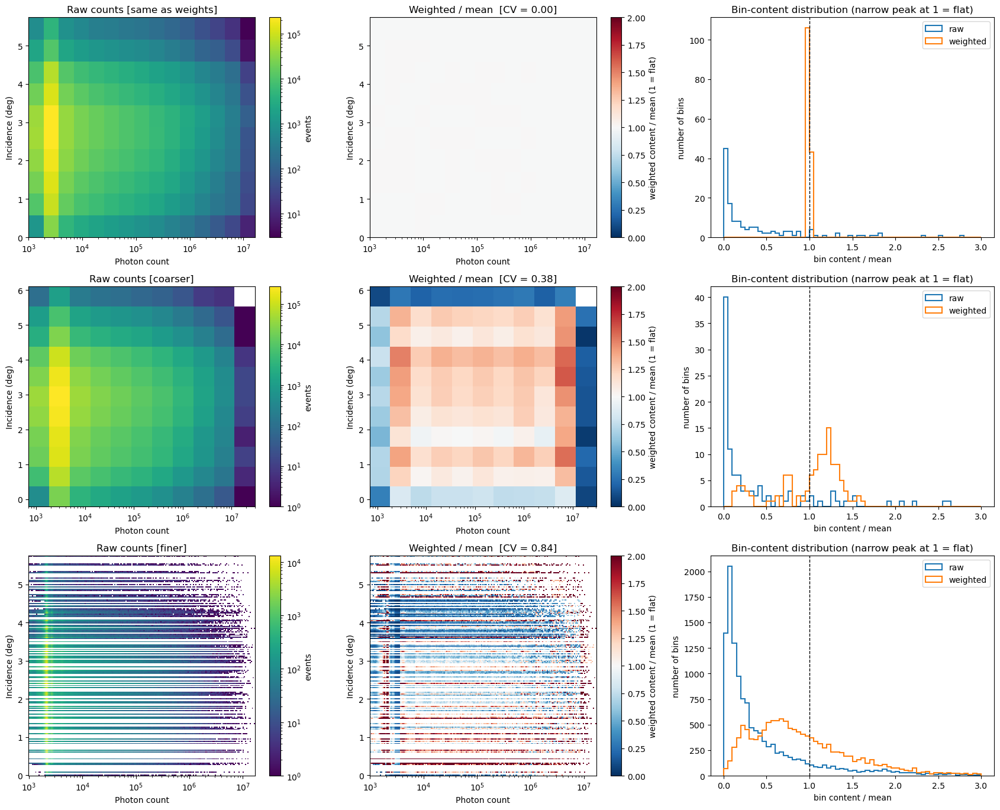

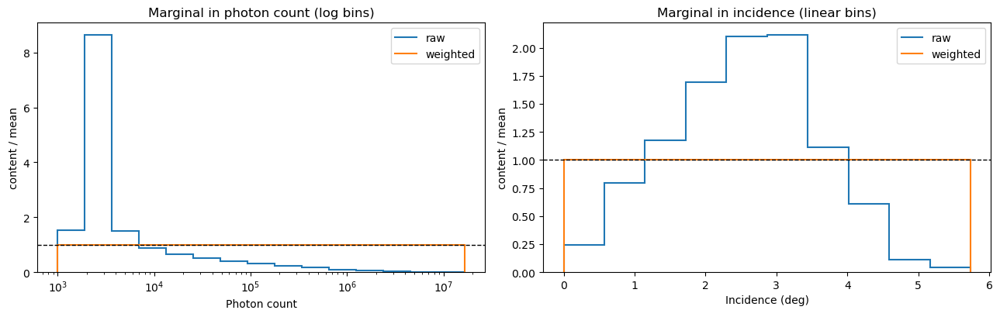


weights: min 0.0548, median 0.139, max 4.21e+03
effective N = 19383 of 1896128 (1.0%)
events at cap: 3


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# =========================================================
# CONFIG
# =========================================================
CHECK_BINNINGS = {                       # name: (n_logpc_bins, n_inc_bins)
    "same as weights": (N_LPC_BINS_W, N_INC_BINS_W),
    "coarser":         (10, 10),
    "finer":           (200, 200),
}
MIN_RAW_PER_BIN = 5                      # ignore bins with fewer raw events in flatness stats

pc_c  = photon_count[valid_w]
inc_c = Incidence[valid_w]
w_c   = weights_2d[valid_w]

def make_edges(n_lpc, n_inc, offset=0.0):
    """Log-spaced photon-count edges and linear incidence edges.
    offset (fraction of a bin) shifts the edges so they don't line up with the weight bins."""
    lo, hi = np.log10(pc_c.min()), np.log10(pc_c.max())
    d = (hi - lo) / n_lpc
    pc_e = np.logspace(lo - offset * d, hi + (1 - offset) * d, n_lpc + 2)
    di = (inc_c.max() - inc_c.min()) / n_inc
    inc_e = np.linspace(inc_c.min() - offset * di, inc_c.max() + (1 - offset) * di, n_inc + 2)
    return pc_e, inc_e

def flatness(H_w, H_raw):
    """Spread of weighted bin contents over well-populated bins."""
    m = H_raw >= MIN_RAW_PER_BIN
    v = H_w[m]
    return m.sum(), v.std() / v.mean(), np.percentile(v, 5) / v.mean(), np.percentile(v, 95) / v.mean()

# =========================================================
# 1. Raw vs weighted 2D histograms for each binning
# =========================================================
n_rows = len(CHECK_BINNINGS)
fig, axs = plt.subplots(n_rows, 3, figsize=(17, 4.6 * n_rows), squeeze=False)

print(f"{'binning':16s} {'bins used':>9s} {'CV raw':>8s} {'CV wtd':>8s} {'5%/mean':>8s} {'95%/mean':>9s}")
for r, (name, (nl, ni)) in enumerate(CHECK_BINNINGS.items()):
    offset = 0.0 if name == "same as weights" else 0.37
    if name == "same as weights":
        pc_e, inc_e = 10**lpc_edges_w, inc_edges_w
    else:
        pc_e, inc_e = make_edges(nl, ni, offset)

    H_raw, _, _ = np.histogram2d(pc_c, inc_c, bins=[pc_e, inc_e])
    H_w,   _, _ = np.histogram2d(pc_c, inc_c, bins=[pc_e, inc_e], weights=w_c)

    nb, cv_w, p5, p95 = flatness(H_w, H_raw)
    _,  cv_r, _,  _   = flatness(H_raw, H_raw)
    print(f"{name:16s} {nb:9d} {cv_r:8.2f} {cv_w:8.2f} {p5:8.2f} {p95:9.2f}")

    # raw
    ax = axs[r, 0]
    im = ax.pcolormesh(pc_e, inc_e, np.where(H_raw > 0, H_raw, np.nan).T,
                       norm=LogNorm(), cmap="viridis", shading="flat")
    ax.set_title(f"Raw counts [{name}]")
    plt.colorbar(im, ax=ax, label="events")

    # weighted, linear colour scale centred on the mean: flat = uniform colour
    ax = axs[r, 1]
    mean_w = H_w[H_raw >= MIN_RAW_PER_BIN].mean()
    im = ax.pcolormesh(pc_e, inc_e, np.where(H_raw > 0, H_w / mean_w, np.nan).T,
                       vmin=0, vmax=2, cmap="RdBu_r", shading="flat")
    ax.set_title(f"Weighted / mean  [CV = {cv_w:.2f}]")
    plt.colorbar(im, ax=ax, label="weighted content / mean (1 = flat)")

    # distribution of weighted bin contents
    ax = axs[r, 2]
    m = H_raw >= MIN_RAW_PER_BIN
    ax.hist(H_raw[m] / H_raw[m].mean(), bins=60, range=(0, 3), histtype="step", lw=1.5, label="raw")
    ax.hist(H_w[m] / mean_w,            bins=60, range=(0, 3), histtype="step", lw=1.5, label="weighted")
    ax.axvline(1, color="k", ls="--", lw=1)
    ax.set_xlabel("bin content / mean"); ax.set_ylabel("number of bins")
    ax.set_title("Bin-content distribution (narrow peak at 1 = flat)")
    ax.legend()

    for ax in axs[r, :2]:
        ax.set_xscale("log")
        ax.set_xlabel("Photon count")
        ax.set_ylabel("Incidence (deg)")

plt.tight_layout()
plt.show()

# =========================================================
# 2. Marginals: log10(photon count) and incidence
# =========================================================
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
pc_e, inc_e = 10**lpc_edges_w, inc_edges_w

for ax, x, edges, xlabel, logx in ((axs[0], pc_c, pc_e, "Photon count", True),
                                   (axs[1], inc_c, inc_e, "Incidence (deg)", False)):
    h_r, _ = np.histogram(x, bins=edges)
    h_w, _ = np.histogram(x, bins=edges, weights=w_c)
    ax.stairs(h_r / h_r.mean(), edges, label="raw", lw=1.5)
    ax.stairs(h_w / h_w.mean(), edges, label="weighted", lw=1.5)
    ax.axhline(1, color="k", ls="--", lw=1)
    ax.set_xlabel(xlabel); ax.set_ylabel("content / mean")
    if logx: ax.set_xscale("log")
    ax.legend()
axs[0].set_title("Marginal in photon count (log bins)")
axs[1].set_title("Marginal in incidence (linear bins)")
plt.tight_layout()
plt.show()

# =========================================================
# 3. Weight sanity
# =========================================================
n_eff = w_c.sum()**2 / np.sum(w_c**2)
print(f"\nweights: min {w_c.min():.3g}, median {np.median(w_c):.3g}, max {w_c.max():.3g}")
print(f"effective N = {n_eff:.0f} of {len(w_c)} ({n_eff/len(w_c):.1%})")
print(f"events at cap: {np.sum(np.isclose(w_c, w_c.max())):d}")

In [2]:
#Trigger Efficiency vs Photon Count, Energy, and Incidence
import plotly.io as pio
pio.renderers.default = "notebook"
# ---------------------------------------------------------
# Grid of 1D trigger-efficiency curves:
#   one panel per incidence bin
#   x = energy (log), y = trigger efficiency (log)
#   one line per photon-count bin, colored by photon count
#   binomial (Wilson) error bars on each point
# ---------------------------------------------------------
import math
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex, Normalize

# ============ USER CONTROLS ============
N_E_BINS   = 5
N_PC_BINS  = 6
N_INC_BINS = 3

E_MODE     = "log"
BIN_MODE   = "log"
INC_MODE   = "linear"

MAX_COLS   = 3

PC_RANGE  = (1e3, np.nanmax(photon_count))
E_RANGE   = (1e3, 1e6)
INC_RANGE = (0.0, 3)

PE_THRESHOLD = 20.0
MIN_EVENTS   = 10
Y_LOG        = True
Y_FLOOR      = 1e-4

ERR_MODE     = "wilson"

PANEL_W = 380
PANEL_H = 320
# =======================================

pc_all  = np.asarray(photon_count, dtype=float)
E_all   = np.asarray(Energy_GeV,   dtype=float)
inc_all = np.asarray(Incidence,    dtype=float)
pe_all  = np.asarray(Max_PE,       dtype=float)
r_all   = np.asarray(R,            dtype=float)

mask = (
    np.isfinite(pc_all) & np.isfinite(E_all)
    & np.isfinite(inc_all) & np.isfinite(pe_all)
    & (pc_all  >= PC_RANGE[0])  & (pc_all  <= PC_RANGE[1])
    & (E_all   >= E_RANGE[0])   & (E_all   <= E_RANGE[1])
    & (inc_all >= INC_RANGE[0]) & (inc_all <= INC_RANGE[1])
    & (r_all == 0)
)

pc_d, E_d, inc_d, pe_d = pc_all[mask], E_all[mask], inc_all[mask], pe_all[mask]
print(f"Events in range: {len(pc_d)} of {len(pc_all)}")
if len(pc_d) == 0:
    raise SystemExit("No events survive the range and reflection cuts.")

def quantile_bins(v, nbins, lo, hi):
    v = v[(v >= lo) & (v <= hi)]
    e = np.percentile(v, np.linspace(0.0, 100.0, nbins + 1))
    e[0], e[-1] = lo, hi
    return np.unique(e)

def log_bins(nbins, lo, hi):
    return np.logspace(np.log10(lo), np.log10(hi), nbins + 1)

E_bins  = (quantile_bins(E_d, N_E_BINS, *E_RANGE) if E_MODE == "quantile"
           else log_bins(N_E_BINS, *E_RANGE))
pc_bins = (quantile_bins(pc_d, N_PC_BINS, *PC_RANGE) if BIN_MODE == "quantile"
           else log_bins(N_PC_BINS, *PC_RANGE))
inc_bins = (quantile_bins(inc_d, N_INC_BINS, *INC_RANGE) if INC_MODE == "quantile"
            else np.linspace(INC_RANGE[0], INC_RANGE[1], N_INC_BINS + 1))

N_E_EFF   = len(E_bins)   - 1
N_PC_EFF  = len(pc_bins)  - 1
N_INC_EFF = len(inc_bins) - 1

for name, want, got in (("energy",       N_E_BINS,   N_E_EFF),
                        ("photon count", N_PC_BINS,  N_PC_EFF),
                        ("incidence",    N_INC_BINS, N_INC_EFF)):
    if got != want:
        print(f"NOTE: {name} bins collapsed {want} -> {got} (ties).")

sample = np.column_stack([E_d, pc_d, inc_d])
edges  = [E_bins, pc_bins, inc_bins]

n_tot,  _ = np.histogramdd(sample, bins=edges)
n_trig, _ = np.histogramdd(sample[pe_d >= PE_THRESHOLD], bins=edges)

with np.errstate(divide="ignore", invalid="ignore"):
    eff = np.where(n_tot > 0, n_trig / n_tot, np.nan)

def wilson_interval(k, n, z=1.0):
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    out_lo = np.full(k.shape, np.nan)
    out_hi = np.full(k.shape, np.nan)
    good = n > 0
    if not np.any(good):
        return out_lo, out_hi
    kg, ng = k[good], n[good]
    p = kg / ng
    denom = 1.0 + z**2 / ng
    center = (p + z**2 / (2.0 * ng)) / denom
    half = (z / denom) * np.sqrt(p * (1.0 - p) / ng + z**2 / (4.0 * ng**2))
    out_lo[good] = np.clip(center - half, 0.0, 1.0)
    out_hi[good] = np.clip(center + half, 0.0, 1.0)
    return out_lo, out_hi

if ERR_MODE == "wilson":
    lo_ci, hi_ci = wilson_interval(n_trig, n_tot, z=1.0)
    err_minus = eff - lo_ci
    err_plus  = hi_ci - eff
else:
    with np.errstate(divide="ignore", invalid="ignore"):
        s = np.where(n_tot > 0, np.sqrt(eff * (1.0 - eff) / n_tot), np.nan)
    err_minus = np.minimum(s, eff)
    err_plus  = np.minimum(s, 1.0 - eff)

E_cen  = np.sqrt(E_bins[:-1]  * E_bins[1:])
pc_cen = np.sqrt(pc_bins[:-1] * pc_bins[1:])

cmap = plt.get_cmap("plasma")
norm = Normalize(vmin=np.log10(pc_bins[0]), vmax=np.log10(pc_bins[-1]))
PC_colors = [to_hex(cmap(norm(np.log10(p)))) for p in pc_cen]

def log_ticks(bins):
    lo, hi = np.floor(np.log10(bins[0])), np.ceil(np.log10(bins[-1]))
    d = np.arange(lo, hi + 1)
    return (10.0 ** d), [f"10<sup>{int(v)}</sup>" for v in d]

E_tv, E_tt = log_ticks(E_bins)

n_cols = min(MAX_COLS, N_INC_EFF)
n_rows = math.ceil(N_INC_EFF / n_cols)

titles = [
    f"{inc_bins[k]:.2f}&ndash;{inc_bins[k+1]:.2f}&deg; "
    f"(N={int(n_tot[:, :, k].sum())})"
    for k in range(N_INC_EFF)
]

fig = make_subplots(
    rows=n_rows, cols=n_cols,
    subplot_titles=titles,
    shared_xaxes=False, shared_yaxes=False,   # <- so per-panel tick labels are drawn
    horizontal_spacing=0.06,
    vertical_spacing=0.14,
)

for k in range(N_INC_EFF):
    r = k // n_cols + 1
    c = k % n_cols + 1

    for j in range(N_PC_EFF):
        n_col_ = n_tot[:, j, k]
        k_col_ = n_trig[:, j, k]
        e_col_ = eff[:, j, k]
        em     = err_minus[:, j, k]
        ep     = err_plus[:, j, k]

        keep = (n_col_ >= MIN_EVENTS) & np.isfinite(e_col_) & (e_col_ > 0)
        if not np.any(keep):
            continue

        label = f"{pc_bins[j]:.3g}&ndash;{pc_bins[j+1]:.3g}"

        fig.add_trace(
            go.Scatter(
                x=E_cen[keep],
                y=e_col_[keep],
                error_y=dict(
                    type="data",
                    symmetric=False,
                    array=ep[keep],
                    arrayminus=np.minimum(em[keep], e_col_[keep] * 0.999),  # keep lower bound > 0 on log axis
                    thickness=1.0,
                    width=2,
                ),
                mode="lines+markers",
                line=dict(color=PC_colors[j], width=1.8),
                marker=dict(size=5, color=PC_colors[j]),
                name=label,
                legendgroup=label,
                showlegend=(k == 0),
                customdata=np.stack(
                    [n_col_[keep], k_col_[keep], em[keep], ep[keep]], axis=-1
                ),
                hovertemplate=(
                    f"photon count = {label}<br>"
                    f"incidence {inc_bins[k]:.2f}&ndash;{inc_bins[k+1]:.2f}&deg;<br>"
                    "E = %{x:.3g} GeV<br>"
                    "efficiency = %{y:.4g} "
                    "(+%{customdata[3]:.2g} / &minus;%{customdata[2]:.2g})<br>"
                    "N total = %{customdata[0]:.0f}<br>"
                    "N triggered = %{customdata[1]:.0f}"
                    "<extra></extra>"
                ),
            ),
            row=r, col=c,
        )

# ---------------------------------------------------------
# Axes: force tick labels on EVERY panel
# ---------------------------------------------------------
y_axis_kw = dict(
    range=[np.log10(Y_FLOOR), np.log10(2)] if Y_LOG else [-0.03,1.03],
    type="log" if Y_LOG else "linear",
)

for r in range(1, n_rows + 1):
    for c in range(1, n_cols + 1):
        fig.update_xaxes(
            type="log", tickvals=E_tv, ticktext=E_tt,
            range=[np.log10(E_bins[0]), np.log10(E_bins[-1])],
            showgrid=True, gridcolor="rgba(0,0,0,0.08)",
            showticklabels=True,     # explicit: keep labels on every panel
            title_text="Energy (GeV)",
            row=r, col=c,
        )
        fig.update_yaxes(
            showgrid=True, gridcolor="rgba(0,0,0,0.08)",
            showticklabels=True,
            title_text="Trigger efficiency" if c == 1 else None,
            **y_axis_kw, row=r, col=c,
        )

fig.update_annotations(font_size=11)

cb_dec = np.arange(np.ceil(np.log10(pc_bins[0])),
                   np.floor(np.log10(pc_bins[-1])) + 1e-9)
fig.add_trace(
    go.Scatter(
        x=[None], y=[None], mode="markers",
        marker=dict(
            colorscale="Plasma",
            cmin=np.log10(pc_bins[0]), cmax=np.log10(pc_bins[-1]),
            color=[np.log10(pc_bins[0])],
            showscale=True,
            colorbar=dict(
                title="Photon<br>count",
                tickvals=cb_dec,
                ticktext=[f"10<sup>{int(v)}</sup>" for v in cb_dec],
                len=0.85, y=0.5, x=1.02,
            ),
        ),
        hoverinfo="skip", showlegend=False,
    ),
    row=1, col=1,
)

mode_txt = ("equal-count quantile" if E_MODE == "quantile"
            else "equal-decade log")
err_txt  = ("Wilson score, 1&sigma;" if ERR_MODE == "wilson"
            else "normal approximation")
fig.update_layout(
    title=(f"Trigger efficiency (Max_PE &ge; {PE_THRESHOLD:.0f}) "
           f"vs. energy, by photon count and incidence angle<br>"
           f"<sub>{N_E_EFF} energy bins ({mode_txt}) | "
           f"points with N < {MIN_EVENTS} dropped | "
           f"errors: {err_txt}</sub>"),
    width=PANEL_W * n_cols + 260,
    height=PANEL_H * n_rows + 150,
    margin=dict(l=80, r=200, t=120, b=60),
    legend=dict(
        title="Photon count",
        x=1.14, y=0.5, yanchor="middle",
        bgcolor="rgba(255,255,255,0.85)",
        bordercolor="rgba(0,0,0,0.2)", borderwidth=1,
        font_size=10,
    ),
    template="plotly_white",
    hovermode="closest",
)

fig.show()
# fig.write_html("trigger_efficiency_vs_energy.html")

Events in range: 4798 of 491751


Events in range: 514054 of 3006832


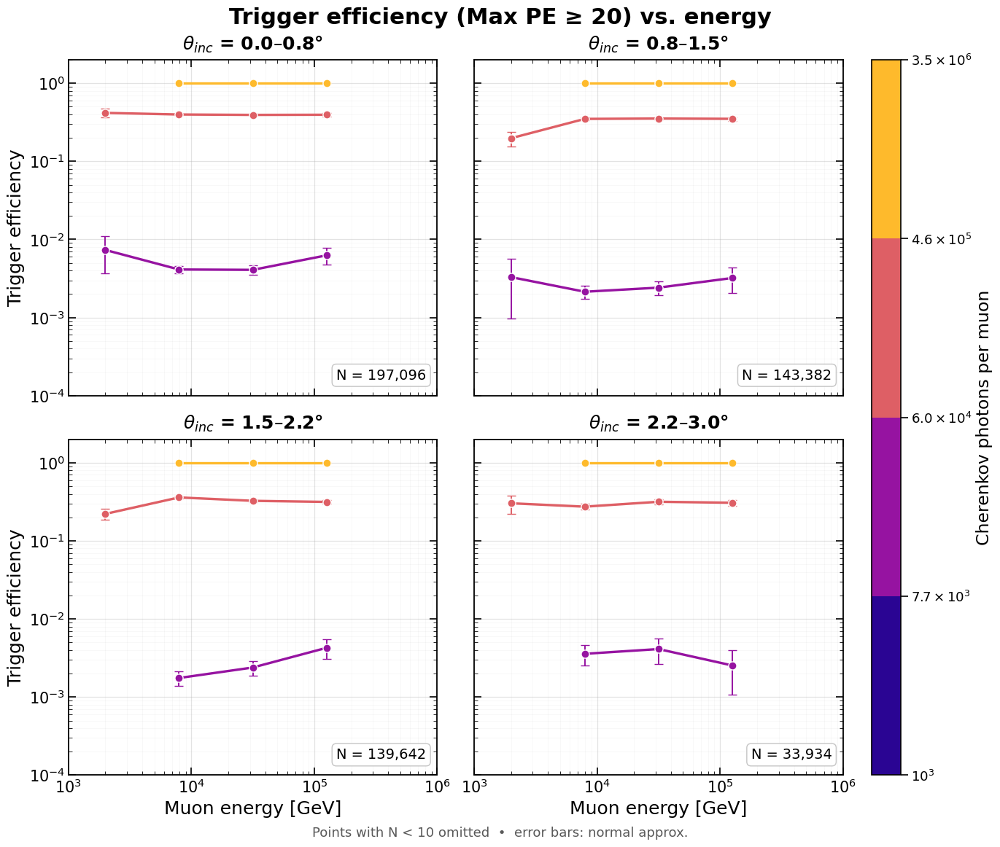

In [10]:
# Trigger Efficiency vs Energy, by Photon Count and Incidence (matplotlib, presentation style)
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import LogLocator, NullFormatter, LogFormatterMathtext

# ============ USER CONTROLS ============
N_E_BINS   = 5
N_PC_BINS  = 4
N_INC_BINS = 4

E_MODE     = "log"        # "log" | "quantile"
BIN_MODE   = "log"        # photon-count binning
INC_MODE   = "linear"     # "linear" | "quantile"

MAX_COLS   = 2

PC_RANGE  = (1e3, np.nanmax(photon_count))
E_RANGE   = (1e3, 1e6)
INC_RANGE = (0.0, 3)

PE_THRESHOLD = 20.0
MIN_EVENTS   = 10
Y_LOG        = True
Y_FLOOR      = 1e-4

ERR_MODE     = "normal"   # "wilson" | "normal"

PANEL_W, PANEL_H = 6.0, 5.0   # inches per panel
SAVE_PATH = None              # e.g. "trigger_eff_vs_energy.pdf"
# =======================================

# ── Style ─────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "font.size": 16,
    "axes.titlesize": 18, "axes.labelsize": 18,
    "xtick.labelsize": 15, "ytick.labelsize": 15,
    "legend.fontsize": 14,
    "axes.linewidth": 1.3,
    "xtick.major.size": 7, "ytick.major.size": 7,
    "xtick.minor.size": 3.5, "ytick.minor.size": 3.5,
    "xtick.major.width": 1.2, "ytick.major.width": 1.2,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
})

# ── Data selection ────────────────────────────────────────────────────────
pc_all  = np.asarray(photon_count, dtype=float)
E_all   = np.asarray(Energy_GeV,   dtype=float)
inc_all = np.asarray(Incidence,    dtype=float)
pe_all  = np.asarray(Max_PE,       dtype=float)
r_all   = np.asarray(R,            dtype=float)

mask = (
    np.isfinite(pc_all) & np.isfinite(E_all)
    & np.isfinite(inc_all) & np.isfinite(pe_all)
    & (pc_all  >= PC_RANGE[0])  & (pc_all  <= PC_RANGE[1])
    & (E_all   >= E_RANGE[0])   & (E_all   <= E_RANGE[1])
    & (inc_all >= INC_RANGE[0]) & (inc_all <= INC_RANGE[1])
    & (r_all == 0)
)
pc_d, E_d, inc_d, pe_d = pc_all[mask], E_all[mask], inc_all[mask], pe_all[mask]
print(f"Events in range: {len(pc_d)} of {len(pc_all)}")
if len(pc_d) == 0:
    raise SystemExit("No events survive the range and reflection cuts.")

# ── Binning ───────────────────────────────────────────────────────────────
def quantile_bins(v, nbins, lo, hi):
    v = v[(v >= lo) & (v <= hi)]
    e = np.percentile(v, np.linspace(0.0, 100.0, nbins + 1))
    e[0], e[-1] = lo, hi
    return np.unique(e)

def log_bins(nbins, lo, hi):
    return np.logspace(np.log10(lo), np.log10(hi), nbins + 1)

E_bins  = (quantile_bins(E_d, N_E_BINS, *E_RANGE) if E_MODE == "quantile"
           else log_bins(N_E_BINS, *E_RANGE))
pc_bins = (quantile_bins(pc_d, N_PC_BINS, *PC_RANGE) if BIN_MODE == "quantile"
           else log_bins(N_PC_BINS, *PC_RANGE))
inc_bins = (quantile_bins(inc_d, N_INC_BINS, *INC_RANGE) if INC_MODE == "quantile"
            else np.linspace(INC_RANGE[0], INC_RANGE[1], N_INC_BINS + 1))

N_E_EFF, N_PC_EFF, N_INC_EFF = len(E_bins) - 1, len(pc_bins) - 1, len(inc_bins) - 1
for name, want, got in (("energy", N_E_BINS, N_E_EFF),
                        ("photon count", N_PC_BINS, N_PC_EFF),
                        ("incidence", N_INC_BINS, N_INC_EFF)):
    if got != want:
        print(f"NOTE: {name} bins collapsed {want} -> {got} (ties).")

# ── Efficiency + errors ───────────────────────────────────────────────────
sample = np.column_stack([E_d, pc_d, inc_d])
edges  = [E_bins, pc_bins, inc_bins]
n_tot,  _ = np.histogramdd(sample, bins=edges)
n_trig, _ = np.histogramdd(sample[pe_d >= PE_THRESHOLD], bins=edges)

with np.errstate(divide="ignore", invalid="ignore"):
    eff = np.where(n_tot > 0, n_trig / n_tot, np.nan)

def wilson_interval(k, n, z=1.0):
    k, n = np.asarray(k, float), np.asarray(n, float)
    lo, hi = np.full(k.shape, np.nan), np.full(k.shape, np.nan)
    g = n > 0
    if not g.any():
        return lo, hi
    p = k[g] / n[g]
    denom  = 1.0 + z**2 / n[g]
    center = (p + z**2 / (2.0 * n[g])) / denom
    half   = (z / denom) * np.sqrt(p * (1.0 - p) / n[g] + z**2 / (4.0 * n[g]**2))
    lo[g], hi[g] = np.clip(center - half, 0, 1), np.clip(center + half, 0, 1)
    return lo, hi

if ERR_MODE == "wilson":
    lo_ci, hi_ci = wilson_interval(n_trig, n_tot, z=1.0)
    err_minus = np.clip(eff - lo_ci, 0.0, None)
    err_plus  = np.clip(hi_ci - eff, 0.0, None)
else:
    with np.errstate(divide="ignore", invalid="ignore"):
        s = np.where(n_tot > 0, np.sqrt(eff * (1.0 - eff) / n_tot), np.nan)
    err_minus = np.clip(np.minimum(s, eff),       0.0, None)
    err_plus  = np.clip(np.minimum(s, 1.0 - eff), 0.0, None)

E_cen = np.sqrt(E_bins[:-1] * E_bins[1:])

# ── Discrete colour map: one colour per photon-count bin ──────────────────
base = plt.get_cmap("plasma")
pc_colors = base(np.linspace(0.05, 0.85, N_PC_EFF))     # skip pale yellow end
cmap_d = ListedColormap(pc_colors)
norm_d = BoundaryNorm(pc_bins, cmap_d.N)

def sci_tex(v):
    """1.47e+04 -> '$1.5\\times10^{4}$', 1e3 -> '$10^{3}$'."""
    e = int(np.floor(np.log10(v))); m = v / 10**e
    return rf"$10^{{{e}}}$" if np.isclose(m, 1, atol=0.05) else rf"${m:.1f}\times10^{{{e}}}$"

# ── Figure ────────────────────────────────────────────────────────────────
n_cols = min(MAX_COLS, N_INC_EFF)
n_rows = math.ceil(N_INC_EFF / n_cols)

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(PANEL_W * n_cols + 1.6, PANEL_H * n_rows + 1.2),
                         sharex=True, sharey=True, squeeze=False,
                         constrained_layout=True)
axes_flat = axes.ravel()

for k in range(N_INC_EFF):
    ax = axes_flat[k]
    for j in range(N_PC_EFF):
        n_c, e_c = n_tot[:, j, k], eff[:, j, k]
        keep = (n_c >= MIN_EVENTS) & np.isfinite(e_c) & (e_c > 0)
        if not keep.any():
            continue
        em = np.minimum(err_minus[:, j, k][keep], e_c[keep] * 0.999)  # stay > 0 on log axis
        ep = err_plus[:, j, k][keep]
        ax.errorbar(E_cen[keep], e_c[keep], yerr=[em, ep],
                    color=pc_colors[j], lw=2.4, marker='o', ms=8,
                    mec='white', mew=1.0, elinewidth=1.4, capsize=4, capthick=1.4,
                    zorder=3)

    ax.set_xscale('log')
    ax.set_xlim(E_bins[0], E_bins[-1])
    if Y_LOG:
        ax.set_yscale('log')
        ax.set_ylim(Y_FLOOR, 2)
        ax.yaxis.set_major_locator(LogLocator(base=10, numticks=12))
        ax.yaxis.set_major_formatter(LogFormatterMathtext())
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10), numticks=100))
        ax.yaxis.set_minor_formatter(NullFormatter())
    else:
        ax.set_ylim(-0.03, 1.03)
    ax.xaxis.set_major_formatter(LogFormatterMathtext())
    ax.xaxis.set_minor_formatter(NullFormatter())

    ax.grid(True, which='major', alpha=0.35, lw=0.9)
    ax.grid(True, which='minor', alpha=0.12, lw=0.5)

    ax.set_title(rf"$\theta_{{inc}}$ = {inc_bins[k]:.1f}–{inc_bins[k+1]:.1f}°",
                 fontweight='bold', pad=10)
    ax.text(0.97, 0.04, f"N = {int(n_tot[:, :, k].sum()):,}",
            transform=ax.transAxes, ha='right', va='bottom', fontsize=14,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.75', alpha=0.9))

# Outer labels only
for r in range(n_rows):
    axes[r, 0].set_ylabel("Trigger efficiency")
for c in range(n_cols):
    col_panels = [j for j in range(c, N_INC_EFF, n_cols)]
    if col_panels:
        axes_flat[col_panels[-1]].set_xlabel("Muon energy [GeV]")
        axes_flat[col_panels[-1]].tick_params(labelbottom=True)
for ax in axes_flat[N_INC_EFF:]:
    ax.set_visible(False)

# Discrete colourbar = photon-count legend
sm = ScalarMappable(norm=norm_d, cmap=cmap_d)
cb = fig.colorbar(sm, ax=axes_flat[:N_INC_EFF].tolist(), spacing='uniform',
                  ticks=pc_bins, pad=0.02, aspect=25, fraction=0.04)
cb.ax.set_yticklabels([sci_tex(v) for v in pc_bins])
cb.set_label("Cherenkov photons per muon", fontsize=17)
cb.ax.tick_params(labelsize=13, direction='out')
cb.outline.set_linewidth(1.2)

err_txt = "Wilson 1σ" if ERR_MODE == "wilson" else "normal approx."
fig.suptitle(f"Trigger efficiency (Max PE ≥ {PE_THRESHOLD:.0f}) vs. energy",
             fontsize=22, fontweight='bold')
fig.text(0.5, -0.02,
         f"Points with N < {MIN_EVENTS} omitted  •  error bars: {err_txt}",
         ha='center', fontsize=13, color='0.35')

if SAVE_PATH:
    fig.savefig(SAVE_PATH, dpi=300, bbox_inches='tight')
plt.show()

In [35]:
# Fitting Landau-Gauss-Body & GEV⊗Gauss-Body -- binned Poisson likelihood version
# WEIGHTED version: the max_PE distribution is contaminated by the parent
# photon_count distribution. weights_pc (same length as photon_count) makes the
# PC distribution flat in log; we apply it to each PE event before fitting.
#
# Weighting scheme (effective counts):
#   W_bin  = sum of w in a PE bin ; W2_bin = sum of w^2 in that bin
#   n_i^eff = W_bin^2 / W2_bin   (variance-matching Poisson count)
#   fractions + data efficiency use W=sum w with n_eff = Wtot^2 / sum(w^2)
import os
from scipy.stats import norm, genextreme
import numpy as np
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(v, "1")
from concurrent.futures import ProcessPoolExecutor, as_completed
import pylandau
import logging
from scipy.integrate import cumulative_trapezoid
from iminuit import Minuit
from iminuit.util import IMinuitWarning
import warnings

logging.getLogger("pylandau").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=IMinuitWarning)

# ---------------------------------------------------------
# 0. Configuration
# ---------------------------------------------------------
PE_THRESHOLD = 20.0
N_P = 5
N_I = 6
EQUAL_COUNT_BINS = False
PC_RANGE  = (1e3, float(np.nanmax(photon_count)))
INC_RANGE = (0.0, np.nanmax(Incidence))
MIN_EVENTS_PER_BIN = 2
N_WORKERS = os.cpu_count()
XMIN_CUT = 1
XMAX_CUT = 149
N_BINS_PE = 100

SIGMA_MIN = 0
KAPPA_LO = 1e-3
KAPPA_HI = 2e3
EPS_MU    = 1e-12

LAMBDA_TRIGGER = 0.0
BIN_EDGES_PE = np.logspace(np.log10(XMIN_CUT), np.log10(XMAX_CUT), N_BINS_PE + 1)
BIN_WIDTHS   = np.diff(BIN_EDGES_PE)
BIN_CENTERS  = 0.5 * (BIN_EDGES_PE[:-1] + BIN_EDGES_PE[1:])
BIN_LO       = BIN_EDGES_PE[:-1]
BIN_HI       = BIN_EDGES_PE[1:]

X_LO, X_HI = XMIN_CUT, XMAX_CUT
N_GRID     = 100
X_GRID     = np.logspace(np.log10(XMIN_CUT), np.log10(XMAX_CUT), N_GRID)

_GH_T, _GH_W = np.polynomial.hermite.hermgauss(64)
_GH_W = _GH_W / np.sqrt(np.pi)

# ---------------------------------------------------------
# 0b. Weighted-count helpers
# ---------------------------------------------------------
def _eff_count(w_subset):
    """Effective (variance-matching) number of events for a weights array."""
    w = np.asarray(w_subset, dtype=float)
    W = float(w.sum())
    W2 = float(np.sum(w * w))
    return W * W / W2 if W2 > 0 else 0.0


def _weighted_hist(pe_vals, w_vals, edges):
    """Return (bin_weight_sum, bin_weight2_sum) histograms."""
    W, _  = np.histogram(pe_vals, bins=edges, weights=w_vals)
    W2, _ = np.histogram(pe_vals, bins=edges, weights=w_vals ** 2)
    return W.astype(float), W2.astype(float)


def _effective_bin_counts(W, W2):
    """n_i^eff = W_i^2/W2_i ; 0 where W_i == 0."""
    n = np.zeros_like(W, dtype=float)
    ok = W2 > 0
    n[ok] = np.maximum(W[ok], 0.0) ** 2 / W2[ok]
    return n


# ---------------------------------------------------------
# 1. Global selection (carry weights along)
# ---------------------------------------------------------
mask2d = (
    np.isfinite(Max_PE) & np.isfinite(photon_count) & np.isfinite(Incidence)
    & (photon_count >= PC_RANGE[0]) & (photon_count <= PC_RANGE[1])
    & (Incidence >= INC_RANGE[0]) & (Incidence <= INC_RANGE[1])
    & (R == 0) #& (Energy_GeV <= 5e5)
)

#Weighted Photon Count:
# ── 2D flattening weights: flat in log10(photon_count) and linear Incidence ──
N_LPC_BINS_W = N_P
N_INC_BINS_W = N_I
N_FLOOR      = 1          # bins with >= N_FLOOR events are flattened exactly
SPARSE_MODE  = "floor"     # "floor": sparse bins get weight target/N_FLOOR (under-filled)
                           # "drop" : sparse bins get weight 0 (excluded)
PC_MIN       = min(PC_RANGE)

valid_w = mask2d #np.isfinite(photon_count) & (photon_count > 0) & np.isfinite(Incidence)
if PC_MIN is not None:
    valid_w &= photon_count >= PC_MIN

lpc_v = np.log10(photon_count[valid_w])
inc_v = Incidence[valid_w]

lpc_edges_w = np.linspace(lpc_v.min(), lpc_v.max(), N_LPC_BINS_W + 1)
inc_lo, inc_hi = INC_RANGE if INC_RANGE is not None else (inc_v.min(), inc_v.max())
inc_edges_w = np.linspace(inc_lo, inc_hi, N_INC_BINS_W + 1)

H2, _, _ = np.histogram2d(lpc_v, inc_v, bins=[lpc_edges_w, inc_edges_w])
ix = np.clip(np.digitize(lpc_v, lpc_edges_w) - 1, 0, N_LPC_BINS_W - 1)
iy = np.clip(np.digitize(inc_v, inc_edges_w) - 1, 0, N_INC_BINS_W - 1)
n_in_bin = H2[ix, iy]

w_v = 1.0 / np.maximum(n_in_bin, N_FLOOR)       # every bin with n >= N_FLOOR gets total weight 1
if SPARSE_MODE == "drop":
    w_v[n_in_bin < N_FLOOR] = 0.0

weights_2d = np.zeros(len(photon_count))
weights_2d[valid_w] = w_v
weights_2d *= valid_w.sum() / weights_2d.sum()

n_eff = weights_2d.sum()**2 / np.sum(weights_2d**2)
occ = H2 > 0
print(f"bins occupied: {occ.sum()}, flattened (n >= {N_FLOOR}): {(H2 >= N_FLOOR).sum()}, "
      f"sparse: {(occ & (H2 < N_FLOOR)).sum()} holding {H2[occ & (H2 < N_FLOOR)].sum():.0f} events")
print(f"weight max/median = {weights_2d.max()/np.median(weights_2d[valid_w]):.0f}, "
      f"effective N = {n_eff:.0f} ({n_eff/valid_w.sum():.1%})")
weights_pc = np.ones(len(weights_2d))#weights_2d


pe_all  = np.asarray(Max_PE[mask2d],       dtype=float)
pc_all  = np.asarray(photon_count[mask2d], dtype=float)
inc_all = np.asarray(Incidence[mask2d],    dtype=float)
w_all   = np.asarray(weights_pc[mask2d],   dtype=float)   # <-- weights applied

w_all = np.where(np.isfinite(pe_all), w_all, 0.0)         # guard non-finite PE

# ---------------------------------------------------------
# 2. Build 2D bin edges
# ---------------------------------------------------------
if EQUAL_COUNT_BINS:
    quantiles = np.linspace(0, 1, N_P + 1)
    pc_edges = np.unique(np.quantile(pc_all, quantiles))
    quantiles = np.linspace(0, 1, N_I + 1)
    inc_edges = np.unique(np.quantile(inc_all, quantiles))
    if len(pc_edges) - 1 != N_P:
        print(f"WARNING: equal-count binning produced {len(pc_edges)-1} unique bins instead of {N_P}")
else:
    inc_edges = np.linspace(INC_RANGE[0], INC_RANGE[1], N_I + 1)
    pc_edges = np.logspace(np.log10(PC_RANGE[0]), np.log10(PC_RANGE[1]), N_P + 1)

print("Incidence bin edges:", inc_edges)
print("Photon count bin edges:", pc_edges)

# ---------------------------------------------------------
# 3. Landau-Gauss body model (unchanged)
# ---------------------------------------------------------
def landau_gauss(x, mpv, eta, sigma, Amplitude):
    sigma_val = np.atleast_1d(sigma)[0] if isinstance(sigma, np.ndarray) else sigma
    eta_val = np.atleast_1d(eta)[0] if isinstance(eta, np.ndarray) else eta
    if sigma_val < SIGMA_MIN:
        return Amplitude * pylandau.landau(x, mpv, eta)
    kappa = eta_val / sigma_val
    if kappa >= KAPPA_HI:
        return Amplitude * pylandau.landau(x, mpv, eta)
    if kappa < KAPPA_LO:
        return Amplitude * np.exp(-0.5 * ((x - mpv) / sigma_val) ** 2) / (
            sigma_val * np.sqrt(2 * np.pi))
    return pylandau.langau(x, mpv, eta, sigma, Amplitude)


def _shape_unnorm(x, mpv, eta, sigma):
    return landau_gauss(np.asarray(x, dtype=float), mpv, eta, sigma, 1.0)


def _expected_counts_lg(mpv, eta, sigma, n_body):
    f = _shape_unnorm(BIN_EDGES_PE, mpv, eta, sigma)
    if not np.all(np.isfinite(f)):
        return None
    f = np.maximum(f, 0.0)
    integ = 0.5 * (f[:-1] + f[1:]) * BIN_WIDTHS
    tot = integ.sum()
    if not np.isfinite(tot) or tot <= 0.0:
        return None
    return n_body * integ / tot


_surv_cache = {}
def body_survival(threshold, mpv_val, eta_val, sigma_val, max_pe_body=0):
    if not all(np.isfinite(v) for v in (threshold, mpv_val, eta_val, sigma_val)):
        return np.nan
    if sigma_val <= 0 or eta_val < 0:
        return np.nan
    lo, hi = XMIN_CUT, XMAX_CUT
    if threshold <= lo:
        return 1.0
    if threshold >= hi:
        return 0.0
    key = tuple(round(float(v), 5) for v in (threshold, mpv_val, eta_val, sigma_val))
    if key in _surv_cache:
        return _surv_cache[key]
    try:
        y = _shape_unnorm(X_GRID, mpv_val, eta_val, sigma_val)
        if not np.all(np.isfinite(y)):
            raise ValueError("Non-finite PDF values")
        cdf = cumulative_trapezoid(y, X_GRID, initial=0.0)
        Fa, Fb, Ft = np.interp([lo, hi, threshold], X_GRID, cdf)
        denom = Fb - Fa
        out = (Fb - Ft) / denom if denom > 0 else np.nan
    except Exception:
        out = np.nan
    out = float(np.clip(out, 0.0, 1.0)) if np.isfinite(out) else np.nan
    _surv_cache[key] = out
    return out

# ---------------------------------------------------------
# 3b. GEV ⊗ Gaussian body model (unchanged)
# ---------------------------------------------------------
def _gev_shape_unnorm(x, mu, scale, xi, sg):
    x = np.asarray(x, dtype=float)[..., None]
    s = np.sqrt(2.0) * sg * _GH_T
    with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
        y = genextreme.pdf(x - s, -xi, loc=mu, scale=scale)
    return np.sum(_GH_W * np.where(np.isfinite(y), y, 0.0), axis=-1)


def _expected_counts_gev(mu, scale, xi, sg, n_body):
    f = _gev_shape_unnorm(BIN_EDGES_PE, mu, scale, xi, sg)
    if not np.all(np.isfinite(f)):
        return None
    f = np.maximum(f, 0.0)
    integ = 0.5 * (f[:-1] + f[1:]) * BIN_WIDTHS
    tot = integ.sum()
    if not np.isfinite(tot) or tot <= 0.0:
        return None
    return n_body * integ / tot


def _gev_conv_sf(x, mu, scale, xi, sg):
    x = np.asarray(x, dtype=float)[..., None]
    s = np.sqrt(2.0) * sg * _GH_T
    with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
        S = genextreme.sf(x - s, -xi, loc=mu, scale=scale)
    return np.sum(_GH_W * np.where(np.isfinite(S), S, 0.0), axis=-1)


def body_survival_gev(threshold, mu, scale, xi, sg):
    if not all(np.isfinite(v) for v in (mu, scale, xi, sg)):
        return np.nan
    if scale <= 0 or sg < 0:
        return np.nan
    lo, hi = XMIN_CUT, XMAX_CUT
    if threshold <= lo:
        return 1.0
    if threshold >= hi:
        return 0.0
    try:
        Slo = float(_gev_conv_sf(lo, mu, scale, xi, sg))
        Shi = float(_gev_conv_sf(hi, mu, scale, xi, sg))
        Sth = float(_gev_conv_sf(threshold, mu, scale, xi, sg))
        denom = Slo - Shi
        out = (Sth - Shi) / denom if denom > 0 else np.nan
    except Exception:
        out = np.nan
    return float(np.clip(out, 0.0, 1.0)) if np.isfinite(out) else np.nan

# ---------------------------------------------------------
# 3c. Trigger efficiency + error propagation (unchanged)
# ---------------------------------------------------------
def combine_efficiency(p_surv, A, A_sat):
    if not np.isfinite(p_surv):
        return np.nan
    return A_sat + A * p_surv


def trigger_efficiency(mpv, eta, sigma, A, A_sat, threshold=PE_THRESHOLD, max_pe_body=0):
    return combine_efficiency(body_survival(threshold, mpv, eta, sigma, max_pe_body), A, A_sat)


def trigger_efficiency_gev(mu, scale, xi, sg, A, A_sat, threshold=PE_THRESHOLD):
    return combine_efficiency(body_survival_gev(threshold, mu, scale, xi, sg), A, A_sat)


def _propagate_survival_error(survival_fn, params, cov, A, A_err, A_sat, A_sat_err, eps=1e-3):
    if cov is None or not np.all(np.isfinite(cov)):
        return np.nan
    params = np.array(params, dtype=float)
    n = len(params)
    p0 = survival_fn(*params)
    if not np.isfinite(p0):
        return np.nan
    grad = np.zeros(n)
    for k in range(n):
        step = max(abs(params[k]) * eps, 1e-6)
        d = np.zeros(n); d[k] = step
        p_plus  = survival_fn(*(params + d))
        p_minus = survival_fn(*(params - d))
        grad[k] = (p_plus - p_minus) / (2.0 * step) if np.isfinite(p_plus) and np.isfinite(p_minus) else 0.0
    var_p = max(float(grad @ cov @ grad), 0.0)
    var_eff = (A_sat_err ** 2 if np.isfinite(A_sat_err) else 0.0)
    var_eff += (p0 ** 2) * (A_err ** 2 if np.isfinite(A_err) else 0.0)
    var_eff += (A ** 2) * var_p
    return float(np.sqrt(var_eff)) if np.isfinite(var_eff) and var_eff >= 0 else np.nan

# ---------------------------------------------------------
# 3d. Population fractions -- WEIGHTED
# ---------------------------------------------------------
def compute_fractions(pe_vals, w_vals=None):
    """
    Weighted population fractions (A_0, A, A_sat) and their errors.

        A     : weighted fraction in [XMIN_CUT, XMAX_CUT)            (body)
        A_0   : weighted fraction below XMIN_CUT
        A_sat : weighted fraction at/above XMAX_CUT

    Errors use a reweighted binomial with n_eff = Wtot^2 / sum(w^2).
    """
    pe_vals = np.asarray(pe_vals, dtype=float)
    if w_vals is None:
        w_vals = np.ones_like(pe_vals)
    w_vals = np.asarray(w_vals, dtype=float)

    if len(pe_vals) == 0:
        return dict(A=np.nan, A_err=np.nan,
                    A_0=np.nan, A_0_err=np.nan,
                    A_sat=np.nan, A_sat_err=np.nan,
                    k_0=0, k_mid=0, k_sat=0, n_total=0,
                    frac_valid=False)

    W_tot = float(w_vals.sum())
    W2_tot = float(np.sum(w_vals * w_vals))
    if W_tot <= 0 or not np.isfinite(W_tot):
        return dict(A=np.nan, A_err=np.nan,
                    A_0=np.nan, A_0_err=np.nan,
                    A_sat=np.nan, A_sat_err=np.nan,
                    k_0=0, k_mid=0, k_sat=0, n_total=0,
                    frac_valid=False)

    m0  = pe_vals < XMIN_CUT
    ms  = pe_vals >= XMAX_CUT
    mm  = (pe_vals >= XMIN_CUT) & (pe_vals < XMAX_CUT)
    W0   = float(w_vals[m0].sum())
    Wsat = float(w_vals[ms].sum())
    Wmid = float(w_vals[mm].sum())

    n_eff = W_tot * W_tot / W2_tot if W2_tot > 0 else 0.0

    def _werr(Wgrp):
        p = Wgrp / W_tot
        return np.sqrt(max(p * (1.0 - p), 0.0) / n_eff) if n_eff > 0 else np.nan

    return dict(
        A=Wmid / W_tot,        A_err=_werr(Wmid),
        A_0=W0 / W_tot,        A_0_err=_werr(W0),
        A_sat=Wsat / W_tot,    A_sat_err=_werr(Wsat),
        k_0=int(W0), k_mid=int(Wmid), k_sat=int(Wsat), n_total=int(W_tot),
        frac_valid=True,
    )

# ---------------------------------------------------------
# 3e. Poisson likelihood helpers (unchanged)
# ---------------------------------------------------------
def _poisson_nll(mu, counts):
    mu = np.maximum(mu, EPS_MU)
    return np.sum(mu - counts * np.log(mu))


def _trigger_nll(p, k_trig, n_body):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(k_trig * np.log(p) + (n_body - k_trig) * np.log(1 - p))

def _poisson_deviance(mu, counts):
    mu = np.maximum(mu, EPS_MU)
    n  = counts.astype(float)
    term = mu - n
    nz = n > 0
    term[nz] += n[nz] * np.log(n[nz] / mu[nz])
    return 2.0 * np.sum(term)

# ---------------------------------------------------------
# 3f. Minuit helper (unchanged)
# ---------------------------------------------------------
def _is_near_bound(value, limit, rtol=1e-3):
    return abs(value - limit) <= rtol * max(abs(limit), 1.0)


def _run_minuit(cost_func, start, limits, strategies=(0, 1), ncall=None):
    m = Minuit(cost_func, **start)
    for name, (lo, hi) in limits.items():
        m.limits[name] = (lo, hi)
    for strategy in strategies:
        m.strategy = strategy
        m.migrad(ncall=ncall) if ncall else m.migrad()
        m.hesse()
        if m.valid:
            break
    return m

# ---------------------------------------------------------
# 3g. Body-shape fits (counts are now EFFECTIVE weighted counts)
# ---------------------------------------------------------
_LG_EMPTY = dict(
    success=False, valid_minuit=False, at_bound=False,
    mpv=np.nan, eta=np.nan, sigma=np.nan,
    mpv_err=np.nan, eta_err=np.nan, sigma_err=np.nan,
    cov=None, nll=np.nan,
    chi2=np.nan, ndof=np.nan, chi2_red=np.nan,
    error_msg=None,
)

_GEV_EMPTY = dict(
    success_gev=False, valid_minuit_gev=False, at_bound_gev=False,
    mu_gev=np.nan, scale_gev=np.nan, xi_gev=np.nan, sg_gev=np.nan,
    mu_gev_err=np.nan, scale_gev_err=np.nan, xi_gev_err=np.nan, sg_gev_err=np.nan,
    cov_gev=None, nll_gev=np.nan,
    chi2_gev=np.nan, ndof_gev=np.nan, chi2_red_gev=np.nan,
    error_msg_gev=None,
)


def fit_landau_gauss(counts, pe_body, n_body, k_trig):
    """Binned Poisson-likelihood fit of the Landau-Gauss body (weighted counts)."""
    out = dict(_LG_EMPTY)
    dens = counts / BIN_WIDTHS
    mpv_guess = float(BIN_CENTERS[np.argmax(dens)])
    q16, q84 = np.percentile(pe_body, [16.0, 84.0])
    spread = max(float(q84 - q16), 1e-3)
    eta_guess = max(spread / 4.0, 1e-3)
    sigma_guess = max(spread / 4.0, 1e-3)

    max_pe_body = np.max(pe_body)
    def cost(mpv, eta, sigma):
        mu = _expected_counts_lg(mpv, eta, sigma, n_body)
        if mu is None:
            return 1e12
        p = body_survival(PE_THRESHOLD, mpv, eta, sigma)
        if not np.isfinite(p):
            return 1e12
        val = _poisson_nll(mu, counts) + LAMBDA_TRIGGER * _trigger_nll(p, k_trig, n_body)
        return val if np.isfinite(val) else 1e12
    cost.errordef = Minuit.LIKELIHOOD

    m = _run_minuit(
        cost, dict(mpv=mpv_guess, eta=eta_guess, sigma=sigma_guess),
        {"mpv": (1, 1000), "eta": (0, XMAX_CUT), "sigma": (0, XMAX_CUT)},
        strategies=(0, 1), ncall=2000,
    )
    if not m.valid:
        m = _run_minuit(
            cost,
            dict(mpv=mpv_guess, eta=max(spread / 8.0, 1e-3), sigma=max(spread / 2.0, 1e-3)),
            {"mpv": (0, 1000), "eta": (0, XMAX_CUT * 2), "sigma": (0, XMAX_CUT * 2)},
            strategies=(2,),
        )

    out["valid_minuit"] = bool(m.valid)
    mpv_fit, eta_fit, sigma_fit = (
        float(m.values["mpv"]), float(m.values["eta"]), float(m.values["sigma"])
    )
    out["mpv"], out["eta"], out["sigma"] = mpv_fit, eta_fit, sigma_fit
    out["at_bound"] = bool(
        _is_near_bound(eta_fit, 1e-4) or _is_near_bound(sigma_fit, 1e-4)
        or _is_near_bound(eta_fit, XMAX_CUT - XMIN_CUT)
        or _is_near_bound(sigma_fit, XMAX_CUT - XMIN_CUT)
        or _is_near_bound(mpv_fit, XMIN_CUT) or _is_near_bound(mpv_fit, XMAX_CUT)
    )
    if not m.valid:
        out["error_msg"] = "Minuit did not converge"
        return out
    try:
        cov = np.array(m.covariance, dtype=float)
        if cov.shape != (3, 3) or not np.all(np.isfinite(cov)):
            cov = None
    except Exception:
        cov = None
    perr = np.sqrt(np.clip(np.diag(cov), 0.0, None)) if cov is not None else np.full(3, np.nan)
    out["cov"] = cov
    out["mpv_err"], out["eta_err"], out["sigma_err"] = perr

    mu_best = _expected_counts_lg(mpv_fit, eta_fit, sigma_fit, n_body)
    if mu_best is None:
        out["error_msg"] = "Model evaluation failed at best fit"
        return out
    n_used = int(np.count_nonzero(counts))
    chi2 = _poisson_deviance(mu_best, counts)
    ndof = n_used - 3
    out.update(dict(
        success=True, nll=float(m.fval),
        chi2=float(chi2), ndof=int(ndof),
        chi2_red=chi2 / ndof if ndof > 0 else np.nan,
    ))
    return out


def fit_gev_gauss(counts, pe_body, n_body):
    """Binned Poisson-likelihood fit of the GEV⊗Gauss body (weighted counts)."""
    out = dict(_GEV_EMPTY)
    dens = counts / BIN_WIDTHS
    mpv_guess = float(BIN_CENTERS[np.argmax(dens)])
    q16, q84 = np.percentile(pe_body, [16.0, 84.0])
    spread = max(float(q84 - q16), 1e-3)
    scale_guess = max(spread / 4.0, 1e-3)
    sg_guess = max(spread / 4.0, 1e-3)
    xi_guess = 0.3

    def cost_gev(mu, scale, xi, sg):
        mu_ = _expected_counts_gev(mu, scale, xi, sg, n_body)
        if mu_ is None:
            return 1e12
        val = _poisson_nll(mu_, counts)
        return val if np.isfinite(val) else 1e12
    cost_gev.errordef = Minuit.LIKELIHOOD

    m = _run_minuit(
        cost_gev,
        dict(mu=mpv_guess, scale=scale_guess, xi=xi_guess, sg=sg_guess),
        {"mu": (0, 10 * XMAX_CUT), "scale": (1e-3, XMAX_CUT),
         "xi": (-0.9, 2.0), "sg": (0, 10 * XMAX_CUT)},
        strategies=(0, 1), ncall=2000,
    )
    if not m.valid:
        m = _run_minuit(
            cost_gev,
            dict(mu=mpv_guess, scale=max(spread / 8.0, 1e-3),
                 xi=0.0, sg=max(spread / 2.0, 1e-3)),
            {"mu": (0, 10 * XMAX_CUT), "scale": (1e-3, 2 * XMAX_CUT),
             "xi": (-0.9, 2.0), "sg": (0, 20 * XMAX_CUT)},
            strategies=(2,),
        )

    out["valid_minuit_gev"] = bool(m.valid)
    mu_fit = float(m.values["mu"])
    sc_fit = float(m.values["scale"])
    xi_fit = float(m.values["xi"])
    sg_fit = float(m.values["sg"])
    out["mu_gev"], out["scale_gev"], out["xi_gev"], out["sg_gev"] = mu_fit, sc_fit, xi_fit, sg_fit
    out["at_bound_gev"] = bool(
        _is_near_bound(sc_fit, 1e-3) or _is_near_bound(sc_fit, 2 * XMAX_CUT)
        or _is_near_bound(xi_fit, -0.9) or _is_near_bound(xi_fit, 2.0)
        or _is_near_bound(sg_fit, 1e-3) or _is_near_bound(sg_fit, 20 * XMAX_CUT)
        or _is_near_bound(mu_fit, 0.0) or _is_near_bound(mu_fit, 10 * XMAX_CUT)
    )
    if not m.valid:
        out["error_msg_gev"] = "Minuit (GEV) did not converge"
        return out
    try:
        cov = np.array(m.covariance, dtype=float)
        if cov.shape != (4, 4) or not np.all(np.isfinite(cov)):
            cov = None
    except Exception:
        cov = None
    if cov is not None:
        perr = np.sqrt(np.clip(np.diag(cov), 0, None))
        (out["mu_gev_err"], out["scale_gev_err"],
         out["xi_gev_err"], out["sg_gev_err"]) = perr
    out["cov_gev"] = cov

    mu_best = _expected_counts_gev(mu_fit, sc_fit, xi_fit, sg_fit, n_body)
    if mu_best is None:
        out["error_msg_gev"] = "GEV evaluation failed at best fit"
        return out
    chi2 = _poisson_deviance(mu_best, counts)
    ndof = int(np.count_nonzero(counts)) - 4
    out.update(dict(
        success_gev=True, nll_gev=float(m.fval),
        chi2_gev=float(chi2), ndof_gev=ndof,
        chi2_red_gev=chi2 / ndof if ndof > 0 else np.nan,
    ))
    return out

# ---------------------------------------------------------
# 4. Worker function -- weighted per-bin fit
# ---------------------------------------------------------
def fit_bin(args):
    """
    args: i_inc, i_pc, inc_lo, inc_hi, pc_lo, pc_hi, pe_vals, pe_w.
    All counts/fractions/efficiency are WEIGHTED by pe_w (effective counts).
    """
    i_inc, i_pc = args["i_inc"], args["i_pc"]
    inc_lo, inc_hi = args["inc_lo"], args["inc_hi"]
    pc_lo, pc_hi = args["pc_lo"], args["pc_hi"]
    pe_vals = args["pe_vals"]
    w_vals  = args["pe_w"]
    n_events = len(pe_vals)
    pe_vals = np.asarray(pe_vals, dtype=float)
    w_vals  = np.asarray(w_vals,  dtype=float)

    result = {
        "i_inc": i_inc, "i_pc": i_pc,
        "inc_lo": inc_lo, "inc_hi": inc_hi,
        "pc_lo": pc_lo, "pc_hi": pc_hi,
        "n_events": n_events, "n_body": 0,
        "bin_centers": None, "counts": None, "bin_edges": None,
        "efficiency": np.nan, "efficiency_err": np.nan,
        "efficiency_data": np.nan, "efficiency_data_err": np.nan,
        "efficiency_gev": np.nan, "efficiency_gev_err": np.nan,
        "delta_nll": np.nan,
    }
    result.update(_LG_EMPTY)
    result.update(_GEV_EMPTY)
    result.update(compute_fractions(pe_vals, w_vals))

    # --- weighted data efficiency (always available) ---
    if n_events > 0:
        finite = np.isfinite(pe_vals)
        W_all = float(w_vals[finite].sum())
        W_trig = float(w_vals[finite & (pe_vals >= PE_THRESHOLD)].sum())
        if W_all > 0:
            eff_data = W_trig / W_all
            n_eff_all = _eff_count(w_vals[finite])
            result["efficiency_data"] = eff_data
            result["efficiency_data_err"] = (
                np.sqrt(max(eff_data * (1.0 - eff_data), 0.0) / n_eff_all)
                if n_eff_all > 0 else np.nan)
        else:
            result["efficiency_data"] = np.nan
            result["efficiency_data_err"] = np.nan

    # --- body selection (weighted) ---
    body_mask = np.isfinite(pe_vals) & (pe_vals >= XMIN_CUT)
    w_body = w_vals[body_mask]
    pe_body = pe_vals[body_mask]
    n_body = _eff_count(w_body)
    result["n_body"] = int(round(n_body))

    if n_body < MIN_EVENTS_PER_BIN:
        result["error_msg"] = (f"Too few weighted body events (n_eff={n_body:.1f} "
                               f"< {MIN_EVENTS_PER_BIN})")
        return result

    try:
        pe_body_min = pe_body.min()
        pe_body_max = pe_body.max()
        pe_body_sel = pe_body[(pe_body >= pe_body_min) & (pe_body < pe_body_max)]
        w_body_sel  = w_body[(pe_body >= pe_body_min) & (pe_body < pe_body_max)]
        n_body = _eff_count(w_body_sel)
        result["n_body"] = int(round(n_body))

        if n_body < MIN_EVENTS_PER_BIN:
            result["error_msg"] = f"Not enough weighted body events ({n_body:.1f} < {MIN_EVENTS_PER_BIN})"
            return result

        # --- weighted (effective) histogram ---
        W_bin, W2_bin = _weighted_hist(pe_body_sel, w_body_sel, BIN_EDGES_PE)
        counts = _effective_bin_counts(W_bin, W2_bin)     # effective per-bin counts
        result["bin_centers"] = BIN_CENTERS.copy()
        result["counts"] = counts
        result["bin_edges"] = BIN_EDGES_PE.copy()

        if np.count_nonzero(counts) < 5:
            result["error_msg"] = "Too few nonempty bins for fitting"
            return result

        # effective trigger count for the (optional) trigger-regularization term
        k_trig = _eff_count(w_vals[np.isfinite(pe_vals) & (pe_vals >= PE_THRESHOLD)])

        # --- GEV⊗Gauss body fit ---
        try:
            result.update(fit_gev_gauss(counts, pe_body, n_body))
        except Exception as e:
            result["error_msg_gev"] = str(e)
        if result["success_gev"]:
            result["efficiency_gev"] = trigger_efficiency_gev(
                result["mu_gev"], result["scale_gev"], result["xi_gev"], result["sg_gev"],
                result["A"], result["A_sat"])
            result["efficiency_gev_err"] = _propagate_survival_error(
                lambda mu, scale, xi, sg: body_survival_gev(PE_THRESHOLD, mu, scale, xi, sg),
                (result["mu_gev"], result["scale_gev"], result["xi_gev"], result["sg_gev"]),
                result["cov_gev"],
                result["A"], result["A_err"], result["A_sat"], result["A_sat_err"],
                eps=1e-4)

        # --- Landau-Gauss body fit ---
        result.update(fit_landau_gauss(counts, pe_body, n_body, k_trig))
        if result["success"]:
            result["efficiency"] = trigger_efficiency(
                result["mpv"], result["eta"], result["sigma"], result["A"], result["A_sat"], max_pe_body=pe_body_max)
            result["efficiency_err"] = _propagate_survival_error(
                lambda mpv, eta, sigma: body_survival(PE_THRESHOLD, mpv, eta, sigma, max_pe_body=pe_body_max),
                (result["mpv"], result["eta"], result["sigma"]), result["cov"],
                result["A"], result["A_err"], result["A_sat"], result["A_sat_err"],
                eps=1e-3)

        # --- model comparison: delta_nll > 0 means GEV⊗Gauss fits better ---
        if result["success"] and result["success_gev"]:
            result["delta_nll"] = result["nll"] - result["nll_gev"]

    except Exception as e:
        result["error_msg"] = str(e)

    return result

# ---------------------------------------------------------
# 5. Prepare all 2D bin jobs (weights sorted alongside PE)
# ---------------------------------------------------------
N_PC = len(pc_edges) - 1
inc_idx = np.clip(np.searchsorted(inc_edges, inc_all, side="right") - 1, 0, N_I - 1)
pc_idx  = np.clip(np.searchsorted(pc_edges,  pc_all,  side="right") - 1, 0, N_PC - 1)
flat    = inc_idx * N_PC + pc_idx

order    = np.argsort(flat, kind="stable")
pe_sorted = pe_all[order]
w_sorted  = w_all[order]
bounds   = np.searchsorted(flat[order], np.arange(N_I * N_PC + 1))

jobs = []
for i_inc in range(N_I):
    for i_pc in range(N_PC):
        k = i_inc * N_PC + i_pc
        jobs.append({
            "i_inc": i_inc, "i_pc": i_pc,
            "inc_lo": inc_edges[i_inc], "inc_hi": inc_edges[i_inc + 1],
            "pc_lo": pc_edges[i_pc],    "pc_hi": pc_edges[i_pc + 1],
            "pe_vals": pe_sorted[bounds[k]:bounds[k + 1]],
            "pe_w":    w_sorted[bounds[k]:bounds[k + 1]],
        })

print(f"Total 2D bins to fit: {len(jobs)}  (weights applied to max_PE)")
jobs.sort(key=lambda j: len(j["pe_vals"]), reverse=True)

# ---------------------------------------------------------
# 6. Run fits in parallel
# ---------------------------------------------------------
results = []
with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
    futures = {executor.submit(fit_bin, job): job for job in jobs}
    for i, future in enumerate(as_completed(futures)):
        res = future.result()
        results.append(res)
        if res["success"]:
            status = "OK" + (" [AT BOUND]" if res["at_bound"] else "")
        else:
            frac_note = " [fractions stored]" if res["frac_valid"] else ""
            status = f"FAILED ({res['error_msg']}){frac_note}"
        eff_str = (
            f"eff_LG={res['efficiency']:.2e}\u00b1{res['efficiency_err']:.2e} "
            f"eff_GEV={res['efficiency_gev']:.2e}\u00b1{res['efficiency_gev_err']:.2e} "
            f"eff_data={res['efficiency_data']:.2e}\u00b1{res['efficiency_data_err']:.2e}"
        )
        print(f"[{i+1}/{len(jobs)}] "
              f"inc=[{res['inc_lo']:.2f},{res['inc_hi']:.2f}) "
              f"pc=[{res['pc_lo']:.2e},{res['pc_hi']:.2e}) "
              f"n_events={res['n_events']} n_body={res['n_body']} -> {status}, "
              f"Dev/ndof LG={res['chi2_red']:.3g} GEV={res['chi2_red_gev']:.3g}, {eff_str}")

# Sort results back into a consistent (i_inc, i_pc) order
results.sort(key=lambda r: (r["i_inc"], r["i_pc"]))

# ---------------------------------------------------------
# 7. Organize results into arrays (unchanged, but counts are effective)
# ---------------------------------------------------------
N_PC_ACTUAL = len(pc_edges) - 1

def _nan_array(*extra_shape):
    return np.full((N_I, N_PC_ACTUAL) + extra_shape, np.nan)

def _bool_array():
    return np.zeros((N_I, N_PC_ACTUAL), dtype=bool)

def _int_array():
    return np.zeros((N_I, N_PC_ACTUAL), dtype=int)

SCALAR_FLAG_KEYS = ("n_events", "success", "frac_valid", "n_body", "at_bound", "success_gev", "at_bound_gev")
FRAC_KEYS = ("A", "A_err", "A_0", "A_0_err", "A_sat", "A_sat_err",
             "k_0", "k_mid", "k_sat", "n_total",
             "efficiency_data", "efficiency_data_err")
LG_KEYS = ("mpv", "eta", "sigma", "mpv_err", "eta_err", "sigma_err",
           "chi2", "ndof", "chi2_red", "nll", "efficiency", "efficiency_err")
GEV_KEYS = ("mu_gev", "scale_gev", "xi_gev", "sg_gev",
            "mu_gev_err", "scale_gev_err", "xi_gev_err", "sg_gev_err",
            "chi2_gev", "ndof_gev", "chi2_red_gev", "nll_gev",
            "efficiency_gev", "efficiency_gev_err")

fit_params = {
    **{k: _nan_array() for k in
       ("mpv", "eta", "sigma", "A", "A_0", "A_sat",
        "mpv_err", "eta_err", "sigma_err", "A_err", "A_0_err", "A_sat_err",
        "chi2", "ndof", "chi2_red",
        "efficiency", "efficiency_err", "efficiency_data", "efficiency_data_err",
        "nll",
        "mu_gev", "scale_gev", "xi_gev", "sg_gev",
        "mu_gev_err", "scale_gev_err", "xi_gev_err", "sg_gev_err",
        "chi2_gev", "ndof_gev", "chi2_red_gev", "nll_gev",
        "efficiency_gev", "efficiency_gev_err", "delta_nll")},
    **{k: _int_array() for k in ("n_events", "n_body", "k_0", "k_mid", "k_sat", "n_total")},
    **{k: _bool_array() for k in ("success", "frac_valid", "at_bound", "success_gev", "at_bound_gev")},
    "cov": _nan_array(3, 3),
    "cov_gev": _nan_array(4, 4),
}

bin_details = [[None] * N_PC_ACTUAL for _ in range(N_I)]

for res in results:
    i, j = res["i_inc"], res["i_pc"]
    for k in SCALAR_FLAG_KEYS:
        fit_params[k][i, j] = res[k]
    if res["frac_valid"]:
        for k in FRAC_KEYS:
            fit_params[k][i, j] = res[k]
    if res["success"]:
        for k in LG_KEYS:
            fit_params[k][i, j] = res[k]
        if res["cov"] is not None:
            fit_params["cov"][i, j] = res["cov"]
    if res["success_gev"]:
        for k in GEV_KEYS:
            fit_params[k][i, j] = res[k]
        if res["cov_gev"] is not None:
            fit_params["cov_gev"][i, j] = res["cov_gev"]
    if res["success"] and res["success_gev"]:
        fit_params["delta_nll"][i, j] = res["delta_nll"]
    bin_details[i][j] = {
        "inc_lo": res["inc_lo"], "inc_hi": res["inc_hi"],
        "pc_lo": res["pc_lo"], "pc_hi": res["pc_hi"],
        "bin_centers": res["bin_centers"],
        "counts": res["counts"],
        "bin_edges": res["bin_edges"],
        "error_msg": res["error_msg"],
        "error_msg_gev": res["error_msg_gev"],
    }

print("\nDone. Summary of chi2_red grid (rows=incidence bins, cols=photon_count bins):")
print("Mean Chi-square:", np.nanmean(fit_params["chi2_red"]))
print("Median Chi-square:", np.nanmedian(fit_params["chi2_red"]))
print("Max and Min Chi-square:", np.nanmax(fit_params["chi2_red"]), np.nanmin(fit_params["chi2_red"]))

n_shape = int(fit_params["success"].sum())
n_frac  = int(fit_params["frac_valid"].sum())
n_bound = int((fit_params["success"] & fit_params["at_bound"]).sum())
print(f"\nBins with converged shape fit : {n_shape} / {N_I * N_PC_ACTUAL}")
print(f"Bins with usable fractions    : {n_frac} / {N_I * N_PC_ACTUAL}")
print(f"Fraction-only bins (recovered): {n_frac - n_shape}")
print(f"Converged but AT A BOUND      : {n_bound}  (errors not trustworthy)")

print("\n--- GEV⊗Gauss model ---")
print("Mean / Median Dev/ndof (GEV):", np.nanmean(fit_params["chi2_red_gev"]),
      np.nanmedian(fit_params["chi2_red_gev"]))
print(f"Converged GEV fits: {int(fit_params['success_gev'].sum())} / {N_I * N_PC_ACTUAL}")
both = fit_params["success"] & fit_params["success_gev"]
dn = fit_params["delta_nll"][both]
print(f"Bins where GEV preferred (delta_nll > 0): {(dn > 0).sum()} / {both.sum()}")
print(f"Median delta_nll: {np.nanmedian(dn):.2f}  (GEV has 1 more parameter -> "
      f"delta_AIC = 2*delta_nll - 2)")

# ---------------------------------------------------------
# 8. Save results to disk for later use
# ---------------------------------------------------------
npz_file = "landau_gev_gauss_2d_fit_results_weighted_tested.npz"
np.savez(
    npz_file,
    inc_edges=inc_edges,
    pc_edges=pc_edges,
    bin_edges_pe=BIN_EDGES_PE,
    xmin_cut=XMIN_CUT,
    xmax_cut=XMAX_CUT,
    **fit_params
)
print("\nSaved fit_params to landau_gev_gauss_2d_fit_results_weighted.npz")
from trigger_eff import build_efficiency_table, TriggerEfficiency

# once
build_efficiency_table(npz_file,
                       "trigger_eff_table.npz", n_min_trig=1, pe_threshold=20)


bins occupied: 30, flattened (n >= 1): 30, sparse: 0 holding 0 events
weight max/median = 4714, effective N = 34708 (1.2%)
Incidence bin edges: [0.   0.75 1.5  2.25 3.   3.75 4.5 ]
Photon count bin edges: [1.00000000e+03 7.07677623e+03 5.00807617e+04 3.54410344e+05
 2.50808270e+06 1.77491400e+07]
Total 2D bins to fit: 30  (weights applied to max_PE)
[1/30] inc=[0.75,1.50) pc=[5.01e+04,3.54e+05) n_events=19765 n_body=19764 -> OK, Dev/ndof LG=32 GEV=3.44, eff_LG=3.28e-02±6.65e-04 eff_GEV=5.02e-03±3.54e-04 eff_data=4.86e-03±4.95e-04
[2/30] inc=[1.50,2.25) pc=[7.08e+03,5.01e+04) n_events=82919 n_body=82910 -> OK, Dev/ndof LG=242 GEV=28.8, eff_LG=5.23e-03±1.20e-04 eff_GEV=3.59e-10±3.53e-10 eff_data=0.00e+00±0.00e+00
[3/30] inc=[0.00,0.75) pc=[7.08e+03,5.01e+04) n_events=127034 n_body=126939 -> OK, Dev/ndof LG=339 GEV=34.9, eff_LG=5.64e-03±1.04e-04 eff_GEV=1.02e-08±5.38e-09 eff_data=7.87e-06±7.87e-06
[4/30] inc=[3.75,4.50) pc=[1.00e+03,7.08e+03) n_events=100847 n_body=5307 -> OK, Dev/ndof LG

'trigger_eff_table.npz'

In [39]:
# 6. Plotly interactive version: slider over Incidence bins, the weight is off and need to be impove for the error bar
#    subplots across photon_count bins for the selected row.
#    Overlays BOTH the Landau-Gauss and the GEV⊗Gauss body fits.
# ---------------------------------------------------------
import math
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
from scipy.stats import genextreme

pio.renderers.default = "notebook"

# Dense log grid for normalisation (the peak sits at low PE)
_XG = np.logspace(np.log10(XMIN_CUT), np.log10(XMAX_CUT), 2000)

# Gauss-Hermite quadrature for the GEV ⊗ Gaussian convolution
_GH_T, _GH_W = np.polynomial.hermite.hermgauss(64)
_GH_W = _GH_W / np.sqrt(np.pi)

def langau_pdf(x, mpv, eta, sigma):
    """
    Landau-Gauss body normalised to unit area on [XMIN_CUT, XMAX_CUT].
    Uses landau_gauss() from the fit code, so the same kappa-regime
    switching (pure Landau / pure Gauss / full convolution) is applied.
    """
    x = np.asarray(x, dtype=float)
    if not (np.isfinite(mpv) and np.isfinite(eta) and np.isfinite(sigma)):
        return np.full_like(x, np.nan)
    try:
        shape_grid = np.asarray(landau_gauss(_XG, mpv, eta, sigma, 1.0), dtype=float)
        shape_x    = np.asarray(landau_gauss(x,   mpv, eta, sigma, 1.0), dtype=float)
    except Exception:
        return np.full_like(x, np.nan)
    shape_grid = np.nan_to_num(np.maximum(shape_grid, 0.0))
    norm = np.trapezoid(shape_grid, _XG)
    if not np.isfinite(norm) or norm <= 0:
        return np.full_like(x, np.nan)
    return np.maximum(shape_x, 0.0) / norm

def gev_gauss_pdf(x, mu, scale, xi, sg):
    """
    GEV(mu, scale, xi) ⊗ Gauss(0, sg), truncated to [XMIN_CUT, XMAX_CUT],
    unit area on that window (same normalisation as used in the fit).
    DIY convolution via Gauss-Hermite quadrature; scipy shape c = -xi.
    """
    x = np.asarray(x, dtype=float)
    if not (np.isfinite(mu) and np.isfinite(scale)
            and np.isfinite(xi) and np.isfinite(sg)) or scale <= 0:
        return np.full_like(x, np.nan)
    s = np.sqrt(2.0) * sg * _GH_T
    def _norm_shape(xx):
        with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
            y = genextreme.pdf(np.asarray(xx, float)[..., None] - s,
                               -xi, loc=mu, scale=scale)
        y = np.where(np.isfinite(y), y, 0.0)
        return np.sum(_GH_W * y, axis=-1)
    shape_grid = np.nan_to_num(np.maximum(_norm_shape(_XG), 0.0))
    norm = np.trapezoid(shape_grid, _XG)
    if not np.isfinite(norm) or norm <= 0:
        return np.full_like(x, np.nan)
    return np.maximum(_norm_shape(x), 0.0) / norm

N_PC_ACTUAL = len(pc_edges) - 1

# Median incidence / photon_count per bin (slider labels / annotations)
row_medians = []
for ii in range(N_I):
    lo, hi = inc_edges[ii], inc_edges[ii + 1]
    sel = (inc_all >= lo) & ((inc_all < hi) if ii < N_I - 1 else (inc_all <= hi))
    row_medians.append(np.median(inc_all[sel]) if np.any(sel) else np.nan)

col_medians = []
for ip in range(N_PC_ACTUAL):
    lo, hi = pc_edges[ip], pc_edges[ip + 1]
    sel = (pc_all >= lo) & ((pc_all < hi) if ip < N_PC_ACTUAL - 1 else (pc_all <= hi))
    col_medians.append(np.median(pc_all[sel]) if np.any(sel) else np.nan)

# ---- grid layout ----
MAX_COLS = 5
N_COLS = min(MAX_COLS, N_PC_ACTUAL)
N_ROWS = math.ceil(N_PC_ACTUAL / N_COLS)

def rc(ip):
    return ip // N_COLS + 1, ip % N_COLS + 1

def subplot_axis_index(r, c):
    return (r - 1) * N_COLS + c

fig = make_subplots(rows=N_ROWS, cols=N_COLS,
                    horizontal_spacing=0.05, vertical_spacing=0.18)

n_traces_per_panel = 3   # data + langau + gev

def compute_ylim(y):
    pos = y[np.isfinite(y) & (y > 0)]
    if len(pos) == 0:
        return None
    return pos.min() / 10.0, pos.max() * 10.0

def _fmt(v, f=".2f"):
    return format(v, f) if np.isfinite(v) else "nan"

def _empty_panel_traces():
    return [go.Scatter(x=[], y=[], mode="markers", showlegend=False),
            go.Scatter(x=[], y=[], mode="lines",   showlegend=False),
            go.Scatter(x=[], y=[], mode="lines",   showlegend=False)]

def build_row_traces(ii):
    traces, annotations, ylims = [], [], {}

    for ip in range(N_PC_ACTUAL):
        detail      = bin_details[ii][ip]
        n_events    = int(fit_params["n_events"][ii, ip])
        success_lg  = bool(fit_params["success"][ii, ip])
        success_gev = bool(fit_params["success_gev"][ii, ip])

        r, c = rc(ip)
        axis_idx = subplot_axis_index(r, c)
        xref = "x domain" if axis_idx == 1 else f"x{axis_idx} domain"
        yref = "y domain" if axis_idx == 1 else f"y{axis_idx} domain"
        pc_med_cell = col_medians[ip]
        pc_label = f"pc_med={pc_med_cell:.3g}" if np.isfinite(pc_med_cell) else "pc_med=N/A"

        no_hist = detail is None or detail.get("counts") is None
        # --- skip panel: no histogram, or neither model converged ---
        if no_hist or not (success_lg or success_gev):
            traces.extend(_empty_panel_traces())
            reason = detail.get("error_msg") if detail is not None else "no data"
            annotations.append(dict(text=f"n={n_events} ({reason})", xref=xref, yref=yref,
                                    x=0.5, y=0.5, showarrow=False, font=dict(size=10)))
            annotations.append(dict(text=pc_label, xref=xref, yref=yref, x=0.5, y=1.08,
                                    showarrow=False, font=dict(size=10, color="black")))
            ylims[ip] = None
            continue

        # --- histogram, density-normalised over the body ---
        counts       = detail["counts"]
        bin_edges_pe = detail["bin_edges"]
        centers      = np.sqrt(bin_edges_pe[:-1] * bin_edges_pe[1:])  # geometric centre (log bins)
        w            = np.diff(bin_edges_pe)
        ntot         = np.sum(counts)
        counts_f     = counts.astype(float) / (w * ntot)
        yerr         = np.sqrt(counts.astype(float)) / (w * ntot)
        nz           = counts_f > 0
        err_minus    = np.clip(np.minimum(yerr, counts_f - 1e-6 * counts_f[nz].max()), 0, None)

        x_grid = np.logspace(np.log10(bin_edges_pe[0]), np.log10(bin_edges_pe[-1]), 400)

        # --- Landau-Gauss ---
        mpv, eta, sigma = (fit_params[k][ii, ip] for k in ("mpv", "eta", "sigma"))
        y_lg = langau_pdf(x_grid, mpv, eta, sigma) if success_lg else np.full_like(x_grid, np.nan)

        # --- GEV ⊗ Gauss ---
        mu_gev, scale_gev, xi_gev, sg_gev = (fit_params[k][ii, ip]
                                              for k in ("mu_gev", "scale_gev", "xi_gev", "sg_gev"))
        y_gev = (gev_gauss_pdf(x_grid, mu_gev, scale_gev, xi_gev, sg_gev)
                 if success_gev else np.full_like(x_grid, np.nan))

        traces.append(go.Scatter(
            x=centers[nz], y=counts_f[nz], mode="markers",
            marker=dict(color="black", size=4),
            error_y=dict(type="data", array=yerr[nz], arrayminus=err_minus[nz],
                         visible=True, thickness=1, width=2),
            name="Data", showlegend=(ip == 0)))
        traces.append(go.Scatter(
            x=x_grid if success_lg else [], y=y_lg if success_lg else [], mode="lines",
            line=dict(color="magenta", width=2),
            name="Landau⊗Gauss", showlegend=(ip == 0)))
        traces.append(go.Scatter(
            x=x_grid if success_gev else [], y=y_gev if success_gev else [], mode="lines",
            line=dict(color="royalblue", width=2, dash="dash"),
            name="GEV⊗Gauss", showlegend=(ip == 0)))

        # --- annotation with both models ---
        chi2_red, chi2, ndof = (fit_params[k][ii, ip] for k in ("chi2_red", "chi2", "ndof"))
        chi2_red_gev, chi2_gev, ndof_gev = (fit_params[k][ii, ip]
                                            for k in ("chi2_red_gev", "chi2_gev", "ndof_gev"))
        dnll = fit_params["delta_nll"][ii, ip]
        A    = fit_params["A"][ii, ip]
        eff_lg, eff_gev, eff_dt = (fit_params[k][ii, ip]
                                   for k in ("efficiency", "efficiency_gev", "efficiency_data"))

        label = (
            f"n={n_events}, A={_fmt(A)}<br>"
            f"<span style='color:magenta'>LG: χ²/ndf={_fmt(chi2_red)} "
            f"({_fmt(chi2, '.1f')}/{_fmt(ndof, '.0f')})<br>"
            f"mpv={_fmt(mpv)} η={_fmt(eta)} σ={_fmt(sigma)}</span><br>"
            f"<span style='color:royalblue'>GEV: χ²/ndf={_fmt(chi2_red_gev)} "
            f"({_fmt(chi2_gev, '.1f')}/{_fmt(ndof_gev, '.0f')})<br>"
            f"μ={_fmt(mu_gev)} sc={_fmt(scale_gev)} ξ={_fmt(xi_gev)} sg={_fmt(sg_gev)}</span><br>"
            f"Δnll(LG−GEV)={_fmt(dnll, '.1f')}<br>"
            f"eff LG/GEV/data={_fmt(eff_lg, '.2e')}/{_fmt(eff_gev, '.2e')}/{_fmt(eff_dt, '.2e')}"
        )
        annotations.append(dict(text=label, xref=xref, yref=yref, x=0.98, y=0.98,
                                showarrow=False, align="right", font=dict(size=8),
                                bgcolor="rgba(255,255,255,0.7)"))
        annotations.append(dict(text=pc_label, xref=xref, yref=yref, x=0.5, y=1.08,
                                showarrow=False, font=dict(size=10, color="black")))

        ylims[ip] = compute_ylim(counts_f)

    return traces, annotations, ylims

# ---- initial row ----
init_traces, init_annotations, init_ylims = build_row_traces(0)
for ip in range(N_PC_ACTUAL):
    r, c = rc(ip)
    for k in range(n_traces_per_panel):
        fig.add_trace(init_traces[n_traces_per_panel * ip + k], row=r, col=c)

# ---- frames (one per incidence bin) ----
frames = []
for ii in range(N_I):
    row_traces, row_annotations, row_ylims = build_row_traces(ii)
    layout_updates = {}
    for ip in range(N_PC_ACTUAL):
        r, c = rc(ip)
        axis_idx = subplot_axis_index(r, c)
        ykey = "yaxis" if axis_idx == 1 else f"yaxis{axis_idx}"
        if row_ylims[ip] is not None:
            ymin, ymax = row_ylims[ip]
            layout_updates[ykey] = dict(type="log", range=[np.log10(ymin), np.log10(ymax)])
    frames.append(go.Frame(data=row_traces, name=str(ii),
                           layout=go.Layout(annotations=row_annotations, **layout_updates)))

fig.frames = frames
fig.update_layout(annotations=init_annotations)

# ---- axes ----
XLIM = (max(np.nanmin(pe_all), XMIN_CUT * 0.8), np.nanmax(pe_all))  # avoid log10(0)
for ip in range(N_PC_ACTUAL):
    r, c = rc(ip)
    fig.update_yaxes(type="log", row=r, col=c)
    if init_ylims[ip] is not None:
        ymin, ymax = init_ylims[ip]
        fig.update_yaxes(range=[np.log10(ymin), np.log10(ymax)], row=r, col=c)
    fig.update_xaxes(type="log", range=[np.log10(XLIM[0]), np.log10(XLIM[1])], row=r, col=c)
    if r == N_ROWS:
        fig.update_xaxes(title_text="Max_PE", row=r, col=c)

fig.update_layout(
    height=500 * N_ROWS + 50,
    width=400 * N_COLS,
    title="Landau⊗Gauss vs GEV⊗Gauss body fits",
    sliders=[{
        "active": 0,
        "currentvalue": {"prefix": "Incidence bin: "},
        "y": -0.25,
        "pad": {"t": 40, "b": 10},
        "steps": [{
            "method": "animate",
            "label": f"{row_medians[ii]:.3g}",
            "args": [[str(ii)], {"mode": "immediate",
                                 "frame": {"duration": 0, "redraw": True},
                                 "transition": {"duration": 0}}],
        } for ii in range(N_I)],
    }],
    legend=dict(orientation="h", yanchor="bottom", y=1.06, xanchor="center", x=0.5),
    margin=dict(t=140, b=140),
)

fig.show()


/tmp/ipykernel_1992130/1659635774.py:84: UserWarning: bin_details has no 'sumw2' -> falling back to Poisson errors sqrt(counts). Store Σw² for correct weighted errors.
  warnings.warn("bin_details has no 'sumw2' -> falling back to Poisson "


saved: gev_fits_by_incidence.pdf


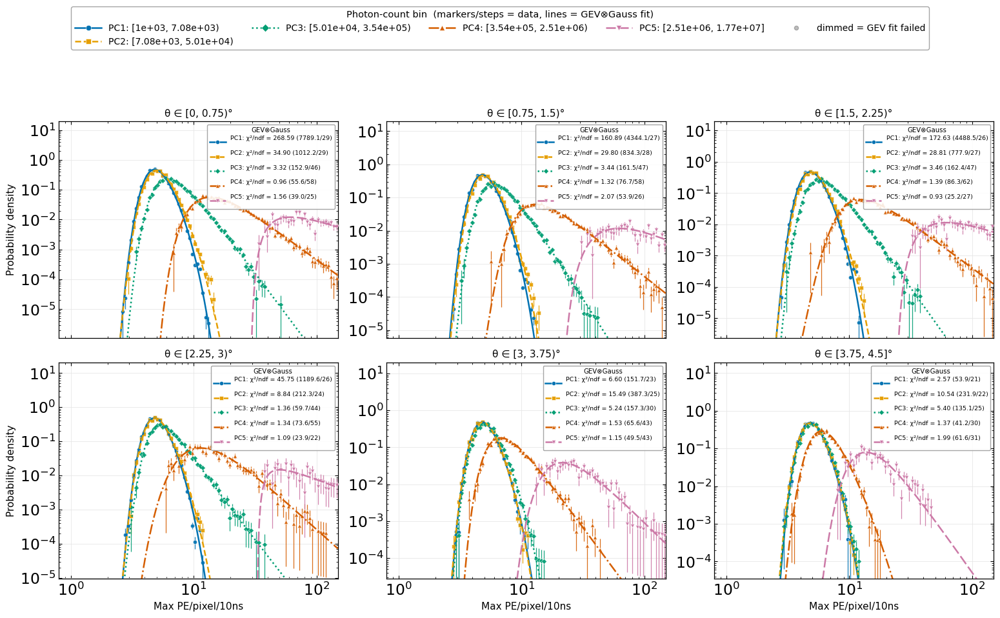

In [38]:
# 7. Static matplotlib grid: one panel per incidence-angle bin,
#    all photon-count bins overlaid (data + GEV⊗Gauss fit).
#    Shared legend = photon-count bins; per-panel legend = χ²/ndf + GEV params.
# ---------------------------------------------------------
import math
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ======================= settings =======================
DATA_STYLE      = "points"     # "points" -> markers + error bars
                               # "step"   -> step histogram + error bars
N_COLS          = None         # None -> automatic ~square grid
PANEL_W, PANEL_H = 5.2, 4.3    # inches per panel
INC_UNIT        = "°"
PC_UNIT         = ""           # e.g. " PE"
XLABEL          = "Max PE/pixel/10ns"
YLABEL          = "Probability density"

FAIL_ALPHA      = 0.22         # opacity of data whose GEV fit failed
DATA_ALPHA      = 0.90
MARKER_SIZE     = 4.5
LINE_WIDTH      = 1.8          # fit curves
STEP_WIDTH      = 1.2          # step histogram outline
CAPSIZE         = 0            # error-bar caps (0 = cleaner)

PANEL_LEG_LOC   = "upper right"   # per-panel legend position
PANEL_LEG_FONT  = 6.8
Y_HEADROOM      = 40.0         # top margin factor (log y) so the legend clears the data
Y_FOOTROOM      = 3.0

SAVE_PATH       = "gev_fits_by_incidence.pdf"   # None -> don't save (also try .png)
DPI             = 300

# ======================= style ==========================
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 11,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "axes.linewidth": 0.9,
    "legend.frameon": True,
    "legend.framealpha": 0.88,
    "legend.edgecolor": "0.6",
})

N_PC = len(pc_edges) - 1

# Okabe-Ito (colour-blind safe); yellow last (weak on white). >8 bins -> viridis.
_OKABE_ITO = ["#0072B2", "#E69F00", "#009E73", "#D55E00",
              "#CC79A7", "#56B4E9", "#000000", "#F0E442"]
PC_COLORS = (_OKABE_ITO[:N_PC] if N_PC <= len(_OKABE_ITO)
             else [plt.cm.viridis(v) for v in np.linspace(0, 0.92, N_PC)])
# redundant encoding: shape + dash -> readable in grayscale / any CVD
PC_MARKERS = ["o", "s", "D", "^", "v", "P", "X", "*", "h", "p"]
PC_DASHES  = ["-", "--", ":", "-.", (0, (6, 2)), (0, (6, 2, 1, 2, 1, 2))]

def sty(ip):
    return (PC_COLORS[ip], PC_MARKERS[ip % len(PC_MARKERS)],
            PC_DASHES[ip % len(PC_DASHES)])

def _fmt(v, f=".2f"):
    return format(v, f) if np.isfinite(v) else "nan"

pc_tag   = [f"PC{ip+1}" for ip in range(N_PC)]
pc_range = [f"[{pc_edges[ip]:.3g}, {pc_edges[ip+1]:.3g}{')' if ip < N_PC-1 else ']'}{PC_UNIT}"
            for ip in range(N_PC)]

# ======================= helpers ========================
_warned_sumw2 = False

def hist_density(detail):
    """Unit-area density with weighted errors sqrt(Σw²)."""
    global _warned_sumw2
    counts = np.asarray(detail["counts"], float)          # Σw per bin
    edges  = np.asarray(detail["bin_edges"], float)
    if detail.get("sumw2") is not None:
        sumw2 = np.asarray(detail["sumw2"], float)         # Σw² per bin
    else:
        if not _warned_sumw2:
            warnings.warn("bin_details has no 'sumw2' -> falling back to Poisson "
                          "errors sqrt(counts). Store Σw² for correct weighted errors.")
            _warned_sumw2 = True
        sumw2 = np.abs(counts)
    wtot = counts.sum()
    if not np.isfinite(wtot) or wtot <= 0:
        return None
    width   = np.diff(edges)
    dens    = counts / (width * wtot)
    err     = np.sqrt(np.clip(sumw2, 0, None)) / (width * wtot)
    centers = np.sqrt(edges[:-1] * edges[1:])             # geometric centre (log bins)
    return edges, centers, dens, err

def draw_data(ax, edges, centers, dens, err, color, marker, alpha):
    pos    = dens > 0
    err_lo = np.minimum(err, 0.95 * dens)                 # never reach 0 on log y
    if DATA_STYLE == "step":
        d = np.where(pos, dens, np.nan)                   # gaps instead of log(0)
        ax.stairs(d, edges, color=color, lw=STEP_WIDTH, alpha=alpha, baseline=None)
        ax.errorbar(centers[pos], dens[pos], yerr=[err_lo[pos], err[pos]],
                    fmt="none", ecolor=color, elinewidth=0.9, capsize=CAPSIZE,
                    alpha=alpha)
    else:
        ax.errorbar(centers[pos], dens[pos], yerr=[err_lo[pos], err[pos]],
                    fmt=marker, ms=MARKER_SIZE, mfc=color, mec="white", mew=0.4,
                    ecolor=color, elinewidth=0.9, capsize=CAPSIZE, alpha=alpha,
                    zorder=3)

def gev_label(ii, ip):
    chi2_red, chi2, ndof = (fit_params[q][ii, ip]
                            for q in ("chi2_red_gev", "chi2_gev", "ndof_gev"))
    mu, sc, xi, sg = (fit_params[q][ii, ip]
                      for q in ("mu_gev", "scale_gev", "xi_gev", "sg_gev"))
    return (f"{pc_tag[ip]}: χ²/ndf = {_fmt(chi2_red)} "
            f"({_fmt(chi2, '.1f')}/{_fmt(ndof, '.0f')})\n"
            #f"μ={_fmt(mu, '.3g')}  σ={_fmt(sc, '.3g')}  "
            #f"ξ={_fmt(xi, '.3f')}  σ_G={_fmt(sg, '.3g')}"
    )
# ======================= figure =========================
NC = N_COLS or math.ceil(math.sqrt(N_I))
NR = math.ceil(N_I / NC)
fig, axes = plt.subplots(NR, NC, figsize=(PANEL_W * NC, PANEL_H * NR + 1.0),
                         sharex=True, squeeze=False)

XLIM = (max(np.nanmin(pe_all), XMIN_CUT * 0.8), np.nanmax(pe_all))

for ii in range(NR * NC):
    ax = axes.flat[ii]
    if ii >= N_I:
        ax.set_visible(False)
        continue

    br = ")" if ii < N_I - 1 else "]"
    ax.set_title(f"θ ∈ [{inc_edges[ii]:.3g}, {inc_edges[ii+1]:.3g}{br}{INC_UNIT}")

    handles, labels, ylo, yhi = [], [], [], []
    for ip in range(N_PC):
        detail = bin_details[ii][ip]
        if detail is None or detail.get("counts") is None:
            continue
        h = hist_density(detail)
        if h is None:
            continue
        edges, centers, dens, err = h
        color, marker, dash = sty(ip)
        ok = bool(fit_params["success_gev"][ii, ip])
        alpha = DATA_ALPHA if ok else FAIL_ALPHA

        draw_data(ax, edges, centers, dens, err, color, marker, alpha)
        pos = dens > 0
        if pos.any():
            ylo.append(dens[pos].min()); yhi.append(dens[pos].max())

        if ok:
            xg = np.logspace(np.log10(edges[0]), np.log10(edges[-1]), 400)
            yg = gev_gauss_pdf(xg, *(fit_params[q][ii, ip]
                                     for q in ("mu_gev", "scale_gev", "xi_gev", "sg_gev")))
            ax.plot(xg, yg, color=color, ls=dash, lw=LINE_WIDTH, zorder=4)
            label = gev_label(ii, ip)
        else:
            n_ev = int(fit_params["n_events"][ii, ip])
            label = f"{pc_tag[ip]}: GEV fit failed (n={n_ev})"

        handles.append(Line2D([], [], color=color, ls=dash if ok else "none",
                              lw=LINE_WIDTH, marker=marker, ms=MARKER_SIZE,
                              mfc=color, mec="white", mew=0.4,
                              alpha=1.0 if ok else FAIL_ALPHA + 0.15))
        labels.append(label)

    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(*XLIM)
    if ylo:
        ax.set_ylim(min(ylo) / Y_FOOTROOM, max(yhi) * Y_HEADROOM)
    else:
        ax.text(0.5, 0.5, "no data", transform=ax.transAxes,
                ha="center", va="center", color="0.5")
    ax.grid(True, which="major", color="0.9", lw=0.6)
    ax.set_axisbelow(True)

    if handles:
        leg = ax.legend(handles, labels, loc=PANEL_LEG_LOC, fontsize=PANEL_LEG_FONT,
                        title="GEV⊗Gauss", title_fontsize=PANEL_LEG_FONT + 0.5,
                        handlelength=2.6, borderpad=0.4, labelspacing=0.35)
        for txt, hnd in zip(leg.get_texts(), handles):     # dim failed entries
            if hnd.get_alpha() is not None and hnd.get_alpha() < 1:
                txt.set_color("0.55")

    if ii // NC == NR - 1 or ii + NC >= N_I:              # bottom visible row
        ax.set_xlabel(XLABEL)
        ax.tick_params(labelbottom=True)
    if ii % NC == 0:
        ax.set_ylabel(YLABEL)

# ---------------- shared legend (photon-count bins) ----------------
shared = [Line2D([], [], color=sty(ip)[0], ls=sty(ip)[2], lw=LINE_WIDTH,
                 marker=sty(ip)[1], ms=MARKER_SIZE + 1.5, mfc=sty(ip)[0],
                 mec="white", mew=0.4) for ip in range(N_PC)]
shared_lbl = [f"{pc_tag[ip]}: {pc_range[ip]}" for ip in range(N_PC)]
shared += [Line2D([], [], color="0.3", marker="o", ls="none", ms=MARKER_SIZE,
                  alpha=FAIL_ALPHA + 0.15)]
shared_lbl += ["dimmed = GEV fit failed"]

fig.legend(shared, shared_lbl, loc="upper center", ncol=min(len(shared), 5),
           bbox_to_anchor=(0.5, 1.0), fontsize=10, handlelength=3,
           title="Photon-count bin  (markers/steps = data, lines = GEV⊗Gauss fit)",
           title_fontsize=10.5)

top = 1 - (0.9 + 0.3 * math.ceil(len(shared) / 5)) / fig.get_figheight()
fig.tight_layout(rect=(0, 0, 1, top))

if SAVE_PATH:
    fig.savefig(SAVE_PATH, dpi=DPI, bbox_inches="tight")
    print(f"saved: {SAVE_PATH}")
plt.show()

96 converged bins selected
  [diagnostic] 58/96 selected bins have mu < 7.0 PE; 29 of those (50.0%) have at_bound_gev set

Offset power-law fits  mu = A + B*x^C   (fitted in log10(mu))


  scale   : A=0.2707+/-0.49, B=5.375+/-0.51, C=0.6711+/-0.031 | chi2/ndf=11.8 (raw), sigma_int=0.0484 dex
  xi      : A=5.246+/-0.49, B=70.48+/-10, C=1.71+/-0.14 | chi2/ndf=30.2 (raw), sigma_int=0.117 dex
  sigma_s : A=7.783+/-0.77, B=2.679+/-3.6, C=1.273+/-0.74 | chi2/ndf=9.82e+04 (raw), sigma_int=0.354 dex

mu = 150*(1 - exp(-B*pc - C)) per incidence angle
  inc=  0.23: B=1.087e-07+/-6.6e-10, C=3.223e-02+/-7.6e-06, chi2/ndf=101
  inc=  0.68: B=1.031e-07+/-8.0e-10, C=3.218e-02+/-1.1e-05, chi2/ndf=87.5
  inc=  1.13: B=9.073e-08+/-5.4e-10, C=3.215e-02+/-8.4e-06, chi2/ndf=155
  inc=  1.58: B=7.960e-08+/-5.9e-10, C=3.215e-02+/-9.5e-06, chi2/ndf=204
  inc=  2.03: B=7.299e-08+/-1.2e-09, C=3.213e-02+/-2.1e-05, chi2/ndf=49.9
  inc=  2.48: B=5.712e-08+/-9.8e-10, C=3.218e-02+/-1.7e-05, chi2/ndf=74.1
  inc=  2.93: B=3.979e-08+/-9.9e-10, C=3.182e-02+/-5.5e-05, chi2/ndf=40.7
  inc=  3.38: B=2.194e-08+/-2.8e-10, C=3.182e-02+/-3.2e-05, chi2/ndf=60
  inc=  3.83: B=1.553e-08+/-3.0e-10, C=3.183e-02+/-4

/tmp/ipykernel_1992130/398941833.py:433: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.92, 0.96])


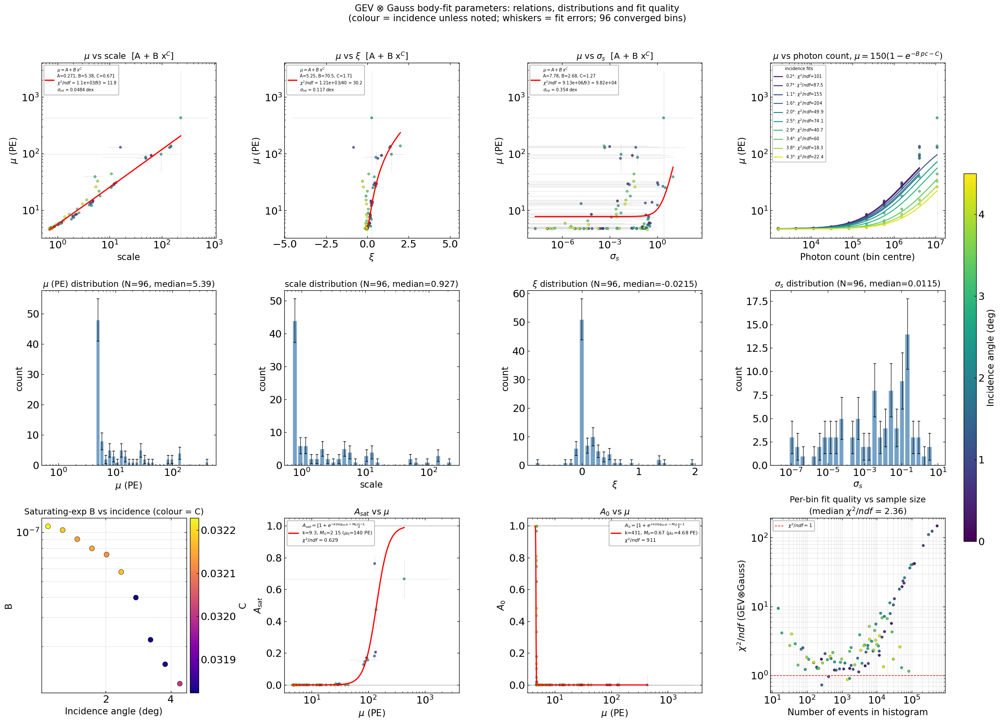


SUMMARY
mu(scale  ) = A + B*x^C : A=0.2707±0.49, B=5.375±0.51, C=0.6711±0.031 | chi2/ndf=11.8 (raw), sigma_int=0.0484 dex
mu(xi     ) = A + B*x^C : A=5.246±0.49, B=70.48±10, C=1.71±0.14 | chi2/ndf=30.2 (raw), sigma_int=0.117 dex
mu(sigma_s) = A + B*x^C : A=7.783±0.77, B=2.679±3.6, C=1.273±0.74 | chi2/ndf=9.82e+04 (raw), sigma_int=0.354 dex
mu(pc|inc) = 150(1-exp(-B pc - C)), 10 angles, median chi2/ndf = 67.1
A_sat(mu): k=9.301, M0=2.145 (mu_0=140 PE), chi2/ndf=0.629
A_0  (mu): k=431.4, M0=0.67 (mu_0=4.68 PE), chi2/ndf=911


In [27]:
# GEV ⊗ Gauss body-fit parameters: 3 x 4 summary figure
#
#  Row 1: mu vs scale | mu vs xi | mu vs sigma_s | mu vs photon count
#         (offset power law  mu = A + B*x^C  per parameter, fitted in
#          log10(mu) with effective variance + intrinsic scatter;
#          saturating-exp fit per incidence angle for photon count)
#  Row 2: histograms of mu, scale, xi, sigma_s
#  Row 3: B vs incidence (colour = C) | A_sat vs mu | A_0 vs mu |
#         chi2/ndf vs n_events
#
#  All scatter points coloured by incidence angle; fits weighted with
#  effective variance  sigma_eff^2 = sigma_y^2 + (df/dx * sigma_x)^2
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.optimize import curve_fit, brentq
from scipy.stats import spearmanr

# ---------------------------------------------------------------------
# USER SETTINGS
# ---------------------------------------------------------------------
npz_file = "landau_gev_gauss_2d_fit_results_weighted_tested.npz"

MU_MAX = 150.0          # saturation ceiling of mu(pc) = MU_MAX*(1-exp(-B*pc-C))

# model per parameter: "powerlaw" (mu = A + B*x^C) or None (no fit, show Spearman rho)
FIT_MODEL = {"scale": "powerlaw", "xi":  "powerlaw", "sigma_s": "powerlaw"}
FIT_INTRINSIC = True    # solve for intrinsic scatter so chi2/ndf = 1

FRAC_USE_XERR = True   # A_sat/A_0 fits: False = script-2 method (y-errors only)
N_EFFVAR_ITER = 3       # iterations of effective-variance re-weighting

# ---------------------------------------------------------------------
# 1. Load
# ---------------------------------------------------------------------
data = np.load(npz_file, allow_pickle=True)

mu,  mu_err  = data["mu_gev"],    data["mu_gev_err"]
sc,  sc_err  = data["scale_gev"], data["scale_gev_err"]
xi,  xi_err  = data["xi_gev"],    data["xi_gev_err"]
sg,  sg_err  = data["sg_gev"],    data["sg_gev_err"]

efficiency = data["efficiency_gev"]
success    = data["success_gev"].astype(bool)
fracv      = data["frac_valid"].astype(bool)
chi2_red   = data["chi2_red_gev"]
n_events   = data["n_events"]

A_sat, A_sat_err = data["A_sat"], data["A_sat_err"]
A_0,   A_0_err   = data["A_0"],   data["A_0_err"]

N_I, N_PC = mu.shape
inc_edges = data["inc_edges"][:N_I + 1]
pc_edges  = data["pc_edges"][:N_PC + 1]

inc_c = 0.5 * (inc_edges[:-1] + inc_edges[1:])
pc_c  = np.sqrt(pc_edges[:-1] * pc_edges[1:])
INC, PC = np.meshgrid(inc_c, pc_c, indexing="ij")

# ---------------------------------------------------------------------
# 2. Base mask (script 1) -> flatten
# ---------------------------------------------------------------------
mask = success & fracv & np.isfinite(efficiency) & np.isfinite(chi2_red)
for v, e in ((mu, mu_err), (sc, sc_err), (xi, xi_err), (sg, sg_err)):
    mask &= np.isfinite(v) & np.isfinite(e)
mask &= mu > 0          # needed for log axes / log10(mu)

f = lambda a: np.asarray(a)[mask].ravel()
MU, MU_E   = f(mu), f(mu_err)
SC, SC_E   = f(sc), f(sc_err)
XI, XI_E   = f(xi), f(xi_err)
SG, SG_E   = f(sg), f(sg_err)
INC_F, PC_F = f(INC), f(PC)
CHI2_F, NEV_F = f(chi2_red), f(n_events).astype(float)
ASAT, ASAT_E = f(A_sat), f(A_sat_err)
A0,   A0_E   = f(A_0),   f(A_0_err)
print(f"{MU.size} converged bins selected")

# Diagnostic: is mu pinned at a fit bound in the low-mu floor region?
if "at_bound_gev" in data.files:
    atb = np.asarray(data["at_bound_gev"])
    if atb.size == mu.size:
        # reshape to the 2D grid so the 2D mask applies, then flatten
        # (same ordering as the f() helper, so atb_m aligns with MU)
        atb_m = atb.reshape(mu.shape)[mask].ravel().astype(bool)
        floor_sel = MU < 7.0          # floor sits near ~5.3 PE
        nf = int(np.sum(floor_sel))
        nb = int(np.sum(floor_sel & atb_m))
        print(f"  [diagnostic] {nf}/{atb_m.size} selected bins have mu < 7.0 PE; "
              f"{nb} of those ({100 * nb / max(nf, 1):.1f}%) have "
              f"at_bound_gev set")
    else:
        print(f"  [diagnostic] skipped: at_bound_gev size {atb.size} "
              f"!= mu size {mu.size}")

def safe_err(err):
    """Replace non-positive / non-finite errors with the median positive error."""
    err = np.asarray(err, float).copy()
    good = np.isfinite(err) & (err > 0)
    fill = np.median(err[good]) if good.any() else 1.0
    err[~good] = fill
    return err

def floor_fraction_err(err, n):
    """Script-2 floor: zero fraction errors (k=0 bins) -> 1/n."""
    err = np.asarray(err, float).copy()
    bad = ~np.isfinite(err) | (err <= 0)
    err[bad] = 1.0 / np.maximum(np.asarray(n, float)[bad], 1.0)
    return err

MU_E_S = safe_err(MU_E)

# ---------------------------------------------------------------------
# 3. Generic effective-variance weighted fit
# ---------------------------------------------------------------------
def num_deriv(func, x, popt):
    h = 1e-5 * np.maximum(np.abs(x), 1e-3)
    return (func(x + h, *popt) - func(x - h, *popt)) / (2 * h)

def fit_effvar(func, x, y, xerr, yerr, p0, bounds=(-np.inf, np.inf),
               n_iter=N_EFFVAR_ITER, maxfev=100000):
    """Weighted fit; x-errors folded in via df/dx (iterated).
    Returns popt, perr, chi2, ndof, sigma_eff."""
    sig = np.asarray(yerr, float)
    popt, pcov = curve_fit(func, x, y, p0=p0, sigma=sig,
                           absolute_sigma=True, bounds=bounds, maxfev=maxfev)
    if xerr is not None:
        for _ in range(n_iter):
            dfdx = num_deriv(func, x, popt)
            sig = np.sqrt(yerr**2 + (dfdx * xerr)**2)
            sig = np.where(sig > 0, sig, np.min(yerr[yerr > 0]))
            popt, pcov = curve_fit(func, x, y, p0=popt, sigma=sig,
                                   absolute_sigma=True, bounds=bounds,
                                   maxfev=maxfev)
    perr = np.sqrt(np.diag(pcov))
    chi2 = np.sum(((y - func(x, *popt)) / sig) ** 2)
    ndof = len(x) - len(popt)
    return popt, perr, chi2, ndof, sig

# ---------------------------------------------------------------------
# 4. mu = f(param) : offset power law    mu = A + B*x^C
#    (same form as script 2's eta(MPV)).  Fitted in log10(mu) so low
#    and high mu count comparably, with effective variance from the
#    x-errors and an intrinsic scatter term solved so chi2/ndf = 1.
# ---------------------------------------------------------------------
def offset_power(x, A, B, C):
    return A + B * np.power(x, C)

def _log_model(x, A, B, C):
    return np.log10(offset_power(x, A, B, C))

def fit_offset_power(x, y, xerr, yerr, n_iter=6, fit_int=FIT_INTRINSIC):
    """Fit log10(mu) = log10(A + B x^C) with effective variance + intrinsic scatter."""
    xerr = np.where(np.isfinite(xerr), xerr, 0.0)
    m = (np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
         & np.isfinite(yerr) & (yerr > 0))
    x, y, xerr, yerr = x[m], y[m], xerr[m], yerr[m]
    if x.size < 5:
        return None

    ly  = np.log10(y)
    sly = yerr / (y * np.log(10))

    # starting values: floor from low-x points, slope from upper half (log-log)
    A0 = np.percentile(y, 5)
    hi = x > np.median(x)
    excess = np.clip(y[hi] - A0, 1e-3 * A0, None)
    C0, lnB = np.polyfit(np.log(x[hi]), np.log(excess), 1)
    C0 = float(np.clip(C0, 0.05, 5))
    popt = [A0, np.exp(lnB), C0]
    bounds = ([1e-6, 1e-12, 1e-3], [np.inf, np.inf, 10])

    sig_int, h = 0.0, 1e-4
    try:
        for _ in range(n_iter):
            dfdx = (_log_model(x * (1 + h), *popt)
                    - _log_model(x * (1 - h), *popt)) / (2 * h * x)
            base = sly**2 + (dfdx * xerr)**2
            popt, pcov = curve_fit(_log_model, x, ly, p0=popt,
                                   sigma=np.sqrt(base + sig_int**2),
                                   absolute_sigma=True, bounds=bounds,
                                   maxfev=50000)
            r2   = (ly - _log_model(x, *popt))**2
            ndof = x.size - 3
            if fit_int:
                g = lambda s: np.sum(r2 / (base + s**2)) - ndof
                sig_int = brentq(g, 0.0, 10.0) if g(0.0) > 0 else 0.0
    except Exception as e:
        print("  power-law fit failed:", e)
        return None

    chi2_raw = np.sum(r2 / base)
    chi2_int = np.sum(r2 / (base + sig_int**2))
    perr = np.sqrt(np.diag(pcov))
    return dict(popt=popt, perr=perr, ndof=ndof, sig_int=sig_int,
                chi2=chi2_raw, chi2r=chi2_raw / ndof, chi2r_int=chi2_int / ndof,
                xmin=x.min(), xmax=x.max())

param_cfg = [   # (key, values, errors, label)
    ("scale",   SC, SC_E, "scale"),
    ("xi",      XI, XI_E, r"$\xi$"),
    ("sigma_s", SG, SG_E, r"$\sigma_s$"),
]

sig_fits = {}
print("\nOffset power-law fits  mu = A + B*x^C   (fitted in log10(mu))")
for key, xv, xe, lab in param_cfg:
    model = FIT_MODEL.get(key)
    res = fit_offset_power(xv, MU, xe, MU_E_S) if model == "powerlaw" else None
    sig_fits[key] = res
    if res is None:
        print(f"  {key:8s}: no fit (model = {model})"); continue
    A, B, C = res["popt"]; dA, dB, dC = res["perr"]
    print(f"  {key:8s}: A={A:.4g}+/-{dA:.2g}, B={B:.4g}+/-{dB:.2g}, "
          f"C={C:.4g}+/-{dC:.2g} | chi2/ndf={res['chi2r']:.3g} "
          f"(raw), sigma_int={res['sig_int']:.3g} dex")

# ---------------------------------------------------------------------
# 5. mu = MU_MAX*(1 - exp(-B pc - C)) per incidence angle
# ---------------------------------------------------------------------
def saturating_exp(pc, B, C):
    return MU_MAX * (1.0 - np.exp(-B * pc - C))

sat_res = []   # list of dicts
print(f"\nmu = {MU_MAX:g}*(1 - exp(-B*pc - C)) per incidence angle")
for inc_val in np.unique(INC_F):
    m = INC_F == inc_val
    if m.sum() < 3:
        continue
    o = np.argsort(PC_F[m])
    pc_i, mu_i, e_i = PC_F[m][o], MU[m][o], MU_E_S[m][o]
    try:
        popt, perr, chi2, ndof, _ = fit_effvar(
            saturating_exp, pc_i, mu_i, None, e_i,
            p0=[1.0 / np.median(pc_i), 0.0], bounds=([0, 0], [1, 1]))
        chi2r = chi2 / ndof if ndof > 0 else np.nan
        sat_res.append(dict(inc=inc_val, B=popt[0], C=popt[1],
                            B_err=perr[0], C_err=perr[1], chi2r=chi2r,
                            pcmin=pc_i.min(), pcmax=pc_i.max()))
        print(f"  inc={inc_val:6.2f}: B={popt[0]:.3e}+/-{perr[0]:.1e}, "
              f"C={popt[1]:.3e}+/-{perr[1]:.1e}, chi2/ndf={chi2r:.3g}")
    except Exception as e:
        print(f"  inc={inc_val:6.2f}: fit failed ({e})")

# ---------------------------------------------------------------------
# 6. A_sat / A_0 vs mu  (script-2 method; x = log10(mu), asymptotes 0/1)
# ---------------------------------------------------------------------
def sigmoid_rise(mu_val, k, M0):
    return 1.0 / (1.0 + np.exp(np.clip(-k * (np.log10(mu_val) - M0), -500, 500)))

def sigmoid_fall(mu_val, k, M0):
    return 1.0 / (1.0 + np.exp(np.clip(+k * (np.log10(mu_val) - M0), -500, 500)))

def fit_frac_sigmoid(func, x, xerr, y, yerr, label):
    sel = np.isfinite(x) & np.isfinite(y) & (x > 0)
    x, xerr, y, yerr = x[sel], xerr[sel], y[sel], yerr[sel]
    if len(x) < 4:
        print(f"\n{label}: not enough points"); return None
    o = np.argsort(x)
    lx, ys = np.log10(x[o]), y[o]
    cross = np.where(np.diff(np.sign(ys - 0.5)) != 0)[0]
    M0_guess = lx[cross[0]] if len(cross) else 0.5 * (lx.min() + lx.max())
    k_guess = 10.0 / max(np.ptp(lx), 1e-12)
    try:
        popt, perr, chi2, ndof, _ = fit_effvar(
            func, x, y, xerr if FRAC_USE_XERR else None, yerr,
            p0=[k_guess, M0_guess], bounds=([1e-12, -np.inf], [np.inf, np.inf]))
    except Exception as e:
        print(f"\n{label}: fit failed ({e})"); return None
    chi2r = chi2 / ndof if ndof > 0 else np.nan
    print(f"\n{label}: k={popt[0]:.4g}+/-{perr[0]:.3g}, "
          f"M0={popt[1]:.4g}+/-{perr[1]:.3g} (mu_0={10**popt[1]:.3g} PE), "
          f"chi2/ndf={chi2:.4g}/{ndof}={chi2r:.4g}")
    return dict(popt=popt, perr=perr, chi2r=chi2r)

m_sat = np.isfinite(ASAT) & np.isfinite(NEV_F)
m_a0  = np.isfinite(A0)   & np.isfinite(NEV_F)
ASAT_E_FIT = floor_fraction_err(ASAT_E, NEV_F)
A0_E_FIT   = floor_fraction_err(A0_E,   NEV_F)

fit_sat = fit_frac_sigmoid(sigmoid_rise, MU[m_sat], MU_E_S[m_sat],
                           ASAT[m_sat], ASAT_E_FIT[m_sat], "A_sat vs mu (rising)")
fit_a0  = fit_frac_sigmoid(sigmoid_fall, MU[m_a0], MU_E_S[m_a0],
                           A0[m_a0], A0_E_FIT[m_a0], "A_0 vs mu (falling)")

# ---------------------------------------------------------------------
# 7. Figure 3 x 4
# ---------------------------------------------------------------------
cmap = plt.get_cmap("viridis")
norm = Normalize(vmin=inc_edges[0], vmax=inc_edges[-1])
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

fig, axes = plt.subplots(3, 4, figsize=(24, 17))

def err_scatter(ax, x, y, xerr, yerr, c):
    ax.errorbar(x, y, xerr=xerr, yerr=yerr, fmt="none", ecolor="lightgray",
                elinewidth=0.5, capsize=0, zorder=1)
    ax.scatter(x, y, c=c, cmap=cmap, norm=norm, s=18, alpha=0.8,
               edgecolors="k", linewidths=0.2, zorder=2)

# ---- Row 1, cols 0-2: mu vs scale / xi / sigma_s ----
for j, (key, xv, xe, lab) in enumerate(param_cfg):
    ax = axes[0, j]
    err_scatter(ax, xv, MU, xe, MU_E, INC_F)

    res = sig_fits.get(key)

    if res is not None:
        A, B, C = res["popt"]
        xs = np.logspace(np.log10(res["xmin"]), np.log10(res["xmax"]), 300)
        ax.plot(xs, offset_power(xs, A, B, C), "r-", lw=2, zorder=3,
                label=(rf"$\mu = A + B\,x^{{C}}$" "\n"
                       rf"A={A:.3g}, B={B:.3g}, C={C:.3g}" "\n"
                       rf"$\chi^2/ndf$ = {res['chi2']:.3g}/{res['ndof']} = {res['chi2r']:.3g}" "\n"
                       rf"$\sigma_{{int}}$ = {res['sig_int']:.3g} dex"))
        ax.legend(fontsize=7, loc="upper left")
    else:
        xm = np.isfinite(xv) & np.isfinite(MU)
        rho, pval = spearmanr(xv[xm], MU[xm])
        ax.text(0.03, 0.97, f"no fit\nSpearman ρ = {rho:+.2f} (p={pval:.1g})",
                transform=ax.transAxes, va="top", fontsize=8,
                bbox=dict(boxstyle="round", fc="white", alpha=0.8))
    if key != "xi":
        ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(lab)
    ax.set_ylabel(r"$\mu$ (PE)")
    ax.set_title(rf"$\mu$ vs {lab}" + ("  [A + B x$^C$]" if res else ""))

# ---- Row 1, col 3: mu vs photon count + per-incidence fits ----
ax = axes[0, 3]
ax.errorbar(PC_F, MU, yerr=MU_E, fmt="none", ecolor="lightgray",
            elinewidth=0.5, capsize=0, zorder=1)
ax.scatter(PC_F, MU, c=INC_F, cmap=cmap, norm=norm, s=18, alpha=0.8,
           edgecolors="k", linewidths=0.2, zorder=2)
for r in sat_res:
    pc_d = np.logspace(np.log10(r["pcmin"]), np.log10(r["pcmax"]), 200)
    ax.plot(pc_d, saturating_exp(pc_d, r["B"], r["C"]), "-",
            color=cmap(norm(r["inc"])), lw=1.6, zorder=3,
            label=rf"{r['inc']:.1f}°: $\chi^2/ndf$={r['chi2r']:.3g}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Photon count (bin centre)")
ax.set_ylabel(r"$\mu$ (PE)")
ax.set_title(rf"$\mu$ vs photon count, $\mu={MU_MAX:g}(1-e^{{-B\,pc-C}})$")
if sat_res:
    ax.legend(fontsize=7, ncol=1 if len(sat_res) <= 10 else 2,
              loc="upper left", framealpha=0.8, title="incidence fits",
              title_fontsize=7)

# ---- Row 2: histograms ----
hist_cfg = [(MU, r"$\mu$ (PE)", True), (SC, "scale", True),
            (XI, r"$\xi$", False), (SG, r"$\sigma_s$", True)]
for j, (vals, lab, logx) in enumerate(hist_cfg):
    ax = axes[1, j]
    vals = vals[np.isfinite(vals)]
    if logx:
        vals = vals[vals > 0]
        edges = np.logspace(np.log10(vals.min()), np.log10(vals.max()), 30)
        ax.set_xscale("log")
        centers = np.sqrt(edges[:-1] * edges[1:])
    else:
        edges = np.linspace(vals.min(), vals.max(), 30)
        centers = 0.5 * (edges[:-1] + edges[1:])
    counts, _ = np.histogram(vals, bins=edges)
    ax.bar(centers, counts, width=np.diff(edges) * 0.8, color="steelblue",
           alpha=0.75, edgecolor="white", yerr=np.sqrt(counts),
           error_kw=dict(ecolor="k", elinewidth=0.8, capsize=2))
    ax.set_xlabel(lab); ax.set_ylabel("count")
    ax.set_title(f"{lab} distribution (N={vals.size}, median={np.median(vals):.3g})")

# ---- Row 3, col 0: B vs incidence, colour = C ----
ax = axes[2, 0]
if sat_res:
    inc_a = np.array([r["inc"] for r in sat_res])
    B_a   = np.array([r["B"] for r in sat_res])
    Be_a  = np.array([r["B_err"] for r in sat_res])
    C_a   = np.array([r["C"] for r in sat_res])
    ax.errorbar(inc_a, B_a, yerr=Be_a, fmt="none", ecolor="gray",
                elinewidth=1, capsize=3, alpha=0.6, zorder=2)
    s_bc = ax.scatter(inc_a, B_a, c=C_a, cmap="plasma", s=70,
                      edgecolor="k", linewidth=0.5, zorder=3)
    fig.colorbar(s_bc, ax=ax, pad=0.02).set_label("C")
    ax.set_yscale("log")
else:
    ax.text(0.5, 0.5, "no saturating-exp fits", ha="center", va="center",
            transform=ax.transAxes)
ax.set_xlabel("Incidence angle (deg)")
ax.set_ylabel("B")
ax.set_title("Saturating-exp B vs incidence (colour = C)")
ax.grid(alpha=0.3, which="both")

# ---- Row 3, cols 1-2: A_sat / A_0 vs mu ----
for ax, m, y, ye, res, func, name, sgn, loc in (
        (axes[2, 1], m_sat, ASAT, ASAT_E_FIT, fit_sat, sigmoid_rise,
         r"A_{sat}", "-", "upper left"),
        (axes[2, 2], m_a0, A0, A0_E_FIT, fit_a0, sigmoid_fall,
         r"A_0", "+", "upper right")):
    err_scatter(ax, MU[m], y[m], MU_E[m], ye[m], INC_F[m])
    if res is not None:
        mu_d = np.logspace(np.log10(MU[m].min()), np.log10(MU[m].max()), 400)
        k, M0 = res["popt"]
        ax.plot(mu_d, func(mu_d, k, M0), "r-", lw=2, zorder=3,
                label=(rf"${name}=[1+e^{{{sgn}k(\log_{{10}}\mu-M_0)}}]^{{-1}}$" "\n"
                       f"k={k:.3g}, $M_0$={M0:.3g} ($\\mu_0$={10**M0:.3g} PE)\n"
                       rf"$\chi^2/ndf$ = {res['chi2r']:.3g}"))
        ax.legend(fontsize=8, loc=loc)
    ax.axhline(0, color="k", lw=0.8, ls=":"); ax.axhline(1, color="k", lw=0.8, ls=":")
    ax.set_xscale("log"); ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel(r"$\mu$ (PE)"); ax.set_ylabel(rf"${name}$")
    ax.set_title(rf"${name}$ vs $\mu$")

# ---- Row 3, col 3: chi2/ndf vs n_events ----
ax = axes[2, 3]
mc = np.isfinite(CHI2_F) & (CHI2_F > 0) & (NEV_F > 0)
ax.scatter(NEV_F[mc], CHI2_F[mc], c=INC_F[mc], cmap=cmap, norm=norm, s=20,
           edgecolors="k", linewidths=0.2)
ax.axhline(1.0, color="r", ls="--", lw=1, label=r"$\chi^2/ndf = 1$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Number of events in histogram")
ax.set_ylabel(r"$\chi^2/ndf$ (GEV$\otimes$Gauss)")
ax.set_title("Per-bin fit quality vs sample size\n"
             rf"(median $\chi^2/ndf$ = {np.median(CHI2_F[mc]):.3g})")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")

# ---- shared incidence colourbar ----
cax = fig.add_axes([0.93, 0.25, 0.012, 0.5])
fig.colorbar(sm, cax=cax).set_label("Incidence angle (deg)")

fig.suptitle("GEV ⊗ Gauss body-fit parameters: relations, distributions and fit quality\n"
             f"(colour = incidence unless noted; whiskers = fit errors; "
             f"{MU.size} converged bins)", fontsize=15)
plt.tight_layout(rect=[0, 0, 0.92, 0.96])
plt.show()

# ---------------------------------------------------------------------
# 8. Summary
# ---------------------------------------------------------------------
print("\n" + "=" * 64)
print("SUMMARY")
print("=" * 64)
for key, res in sig_fits.items():
    if res is not None:
        A, B, C = res["popt"]; dA, dB, dC = res["perr"]
        print(f"mu({key:7s}) = A + B*x^C : A={A:.4g}±{dA:.2g}, B={B:.4g}±{dB:.2g}, "
              f"C={C:.4g}±{dC:.2g} | chi2/ndf={res['chi2r']:.3g} "
              f"(raw), sigma_int={res['sig_int']:.3g} dex")
if sat_res:
    print(f"mu(pc|inc) = {MU_MAX:g}(1-exp(-B pc - C)), {len(sat_res)} angles, "
          f"median chi2/ndf = {np.nanmedian([r['chi2r'] for r in sat_res]):.3g}")
for name, res in (("A_sat", fit_sat), ("A_0", fit_a0)):
    if res is not None:
        print(f"{name:5s}(mu): k={res['popt'][0]:.4g}, M0={res['popt'][1]:.4g} "
              f"(mu_0={10**res['popt'][1]:.3g} PE), chi2/ndf={res['chi2r']:.3g}")
print("=" * 64)


Keys in file: ['inc_edges', 'pc_edges', 'bin_edges_pe', 'xmin_cut', 'xmax_cut', 'mpv', 'eta', 'sigma', 'A', 'A_0', 'A_sat', 'mpv_err', 'eta_err', 'sigma_err', 'A_err', 'A_0_err', 'A_sat_err', 'chi2', 'ndof', 'chi2_red', 'efficiency', 'efficiency_err', 'efficiency_data', 'efficiency_data_err', 'nll', 'mu_gev', 'scale_gev', 'xi_gev', 'sg_gev', 'mu_gev_err', 'scale_gev_err', 'xi_gev_err', 'sg_gev_err', 'chi2_gev', 'ndof_gev', 'chi2_red_gev', 'nll_gev', 'efficiency_gev', 'efficiency_gev_err', 'delta_nll', 'n_events', 'n_body', 'k_0', 'k_mid', 'k_sat', 'n_total', 'success', 'frac_valid', 'at_bound', 'success_gev', 'at_bound_gev', 'cov', 'cov_gev']


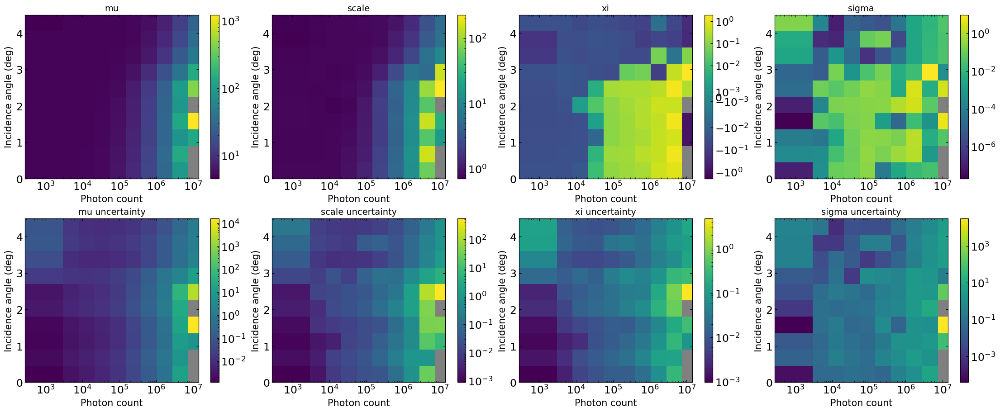

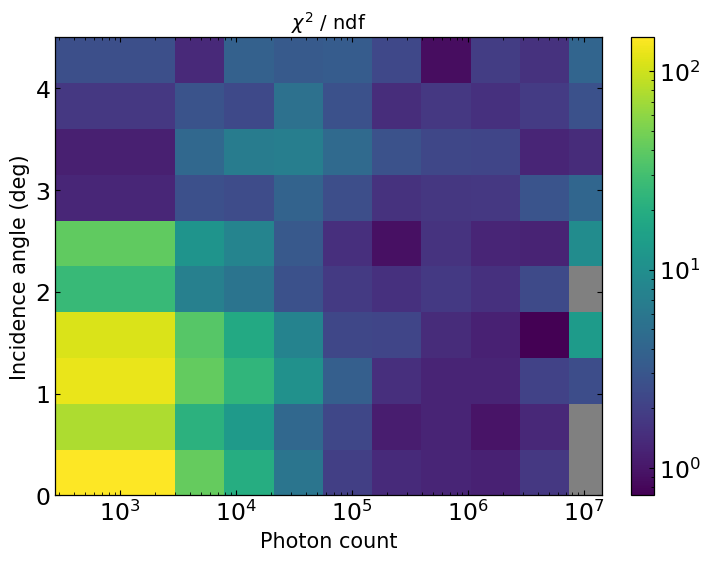

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, SymLogNorm

npz_file = "landau_gev_gauss_2d_fit_results_weighted_tested.npz"
out_params = "gev_gauss_params_heatmap.png"
out_chi2 = "gev_gauss_chi2_heatmap.png"

d = np.load(npz_file, allow_pickle=True)
print("Keys in file:", list(d.keys()))

# ---- Adjust here if your key names differ ----
KEYS = {
    "inc_edges": "inc_edges",      # incidence angle bin edges (deg)
    "pc_edges":  "pc_edges",       # photon count bin edges
    "params": [("mu_gev", "mu"), ("scale_gev", "scale"),
               ("xi_gev", "xi"), ("sg_gev", "sigma")],
    "err_suffix": "_err",
    "chi2red": "chi2_red_gev",
    "success": "success_gev",      # set to None if absent
}
# ----------------------------------------------

inc_edges = np.asarray(d[KEYS["inc_edges"]], float)
pc_edges = np.asarray(d[KEYS["pc_edges"]], float)

# Bin centres (photon count: geometric centre, since axis is log)
inc_c = 0.5 * (inc_edges[:-1] + inc_edges[1:])
pc_c = np.sqrt(pc_edges[:-1] * pc_edges[1:])

# Expected array layout: (n_inc, n_pc). Transposed automatically if needed.
def orient(a):
    a = np.asarray(a, float)
    if a.shape == (len(inc_c), len(pc_c)):
        return a
    if a.shape == (len(pc_c), len(inc_c)):
        return a.T
    raise ValueError(f"Unexpected shape {a.shape}, expected "
                     f"{(len(inc_c), len(pc_c))}")

ok = np.ones((len(inc_c), len(pc_c)), bool)
if KEYS["success"] and KEYS["success"] in d:
    ok = orient(d[KEYS["success"]]).astype(bool)

def make_norm(vals):
    """Log by default; symlog if any valid value is <= 0."""
    v = vals[np.isfinite(vals)]
    if v.size == 0:
        return None
    if np.any(v <= 0):
        absv = np.abs(v[v != 0])
        linthresh = np.percentile(absv, 5) if absv.size else 1.0
        vmax = np.max(np.abs(v))
        return SymLogNorm(linthresh=linthresh, vmin=-vmax, vmax=vmax, base=10)
    return LogNorm(vmin=v.min(), vmax=v.max())

def draw(ax, data, title, cmap):
    data = data.copy()
    data[~ok] = np.nan
    data[~np.isfinite(data)] = np.nan
    masked = np.ma.masked_invalid(data)
    norm = make_norm(data)
    cmap = plt.get_cmap(cmap).copy()
    cmap.set_bad("gray")
    ax.set_facecolor("gray")
    m = ax.pcolormesh(pc_c, inc_c, masked, cmap=cmap, norm=norm, shading="nearest")
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("Photon count")
    ax.set_ylabel("Incidence angle (deg)")
    plt.colorbar(m, ax=ax)

cmap = "viridis"

# ---------- Figure 1: parameters (row 1) and uncertainties (row 2) ----------
fig, axes = plt.subplots(2, 4, figsize=(22, 9), constrained_layout=True)
for j, (key, label) in enumerate(KEYS["params"]):
    val = orient(d[key])
    err = orient(d[key + KEYS["err_suffix"]])
    err = np.where(err > 0, err, np.nan)   # non-positive errors -> gray
    draw(axes[0, j], val, label, cmap)
    draw(axes[1, j], err, f"{label} uncertainty", cmap)
fig.savefig(out_params, dpi=300)

# ---------- Figure 2: chi2 / ndf ----------
chi2 = orient(d[KEYS["chi2red"]])
chi2 = np.where(chi2 > 0, chi2, np.nan)
fig2, ax2 = plt.subplots(figsize=(7, 5.5), constrained_layout=True)
draw(ax2, chi2, r"$\chi^2$ / ndf", cmap)
fig2.savefig(out_chi2, dpi=300)

plt.show()

Model efficiency loaded for 96 / 100 bins
Data efficiency computed for 100 / 100 bins (nonzero count bins)


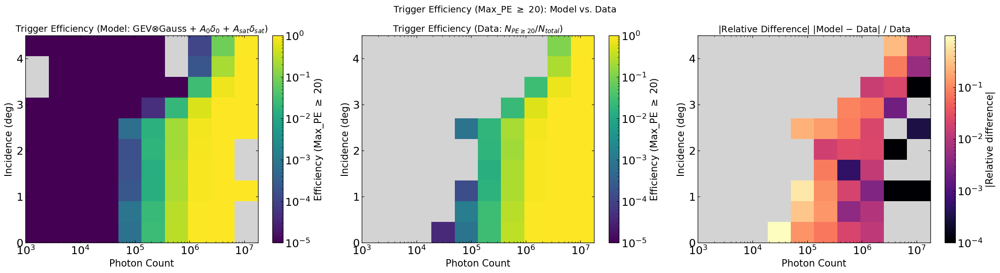


Median |relative difference| = 0.01855
Bins compared: 42 / 100
Pull computed for 92 / 100 bins
Mean pull = 0.162, median = 0.119, RMS = 0.670
Fraction |pull| > 3: 0.010


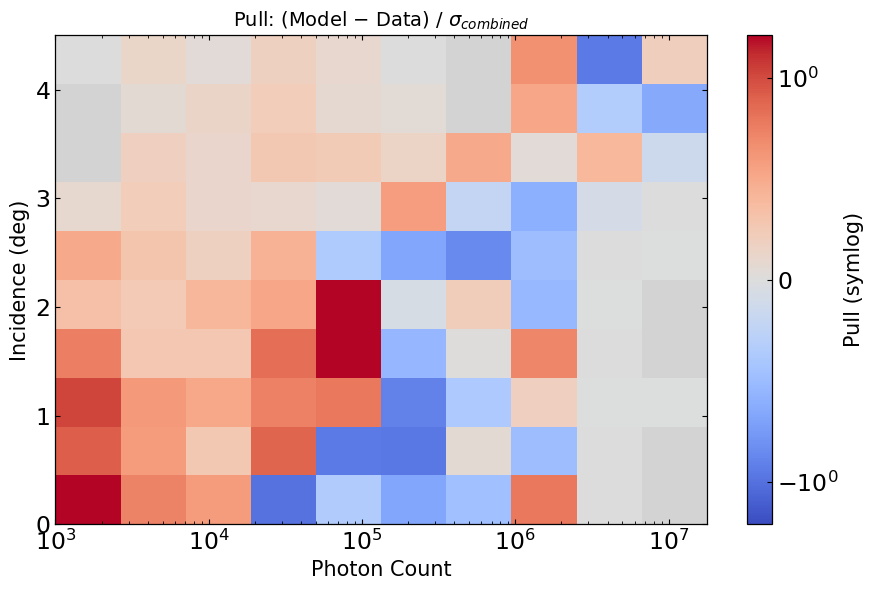

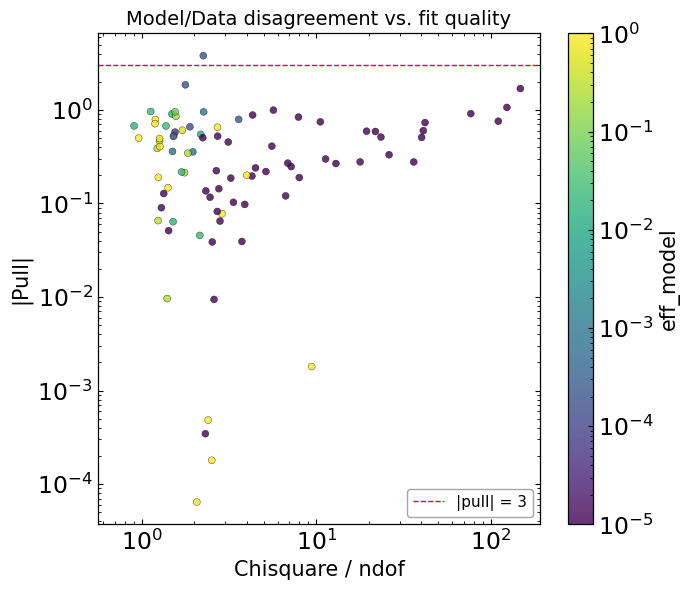

Correlation coefficient (log Deviance/ndof vs log|pull|): nan


/tmp/ipykernel_1992130/1342665321.py:256: RuntimeWarning: divide by zero encountered in log10
  r = np.corrcoef(np.log10(x), np.log10(y))[0, 1]
/uufs/chpc.utah.edu/common/home/u1520754/miniconda3/envs/landau310/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2888: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]


In [29]:
# Compare Data and Model (GEV ⊗ Gauss):
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
print_data = False
npz_file = "landau_gev_gauss_2d_fit_results_weighted_tested.npz"
# ---------------------------------------------------------
# 1. Load fit results (efficiency loaded directly, not recomputed)
# ---------------------------------------------------------
data = np.load(npz_file, allow_pickle=True)

mu_gev       = data["mu_gev"]
scale_gev    = data["scale_gev"]
xi_gev       = data["xi_gev"]
sg_gev       = data["sg_gev"]
A            = data["A"]
A_0          = data["A_0"]
A_sat        = data["A_sat"]
n_events     = data["n_events"]
success_gev  = data["success_gev"]
frac_valid   = data["frac_valid"]

efficiency_gev     = data["efficiency_gev"]
efficiency_gev_err = data["efficiency_gev_err"]

inc_edges = data["inc_edges"]
pc_edges  = data["pc_edges"]

N_I, N_PC_ACTUAL = mu_gev.shape

PE_THRESHOLD = 20.0

# ---------------------------------------------------------
# 2. Model trigger efficiency -- loaded from npz
# ---------------------------------------------------------
eff_model     = np.array(efficiency_gev, dtype=float)
eff_model_err = np.array(efficiency_gev_err, dtype=float)

valid_model = success_gev & frac_valid & np.isfinite(eff_model)
eff_model     = np.where(valid_model, eff_model, np.nan)
eff_model_err = np.where(valid_model, eff_model_err, np.nan)
eff_model     = np.clip(eff_model, 0.0, 1.0)

print(f"Model efficiency loaded for {np.isfinite(eff_model).sum()} / "
      f"{N_I*N_PC_ACTUAL} bins")


# ---------------------------------------------------------
# 3. Data trigger efficiency -- vectorized with histogram2d
#    (two passes over the data instead of 600 masked passes)
# ---------------------------------------------------------
mask2d_eff = (
    np.isfinite(Max_PE) & np.isfinite(photon_count) & np.isfinite(Incidence)
    & (photon_count >= pc_edges[0]) & (photon_count <= pc_edges[-1])
    & (Incidence >= inc_edges[0]) & (Incidence <= inc_edges[-1])
    & (R == 0) & (Energy_GeV <= 5e5)
)

pe_d  = np.asarray(Max_PE[mask2d_eff],       dtype=float)
pc_d  = np.asarray(photon_count[mask2d_eff], dtype=float)
inc_d = np.asarray(Incidence[mask2d_eff],    dtype=float)

# histogram2d closes the last bin on the right, matching the original
# "include right edge in last bin" special case.
n_tot, _, _ = np.histogram2d(inc_d, pc_d, bins=[inc_edges, pc_edges])

trig = pe_d >= PE_THRESHOLD
n_trig, _, _ = np.histogram2d(inc_d[trig], pc_d[trig], bins=[inc_edges, pc_edges])

n_data = n_tot.astype(int)
with np.errstate(divide="ignore", invalid="ignore"):
    eff_data = np.where(n_tot > 0, n_trig / n_tot, np.nan)
    eff_data_err = np.where(
        n_tot > 0,
        np.sqrt(np.clip(eff_data * (1.0 - eff_data), 0.0, None) / np.maximum(n_tot, 1)),
        np.nan)

print(f"Data efficiency computed for {np.isfinite(eff_data).sum()} / "
      f"{N_I*N_PC_ACTUAL} bins (nonzero count bins)")


# ---------------------------------------------------------
# 3b. Print model vs data efficiency (with uncertainty) side by side
# ---------------------------------------------------------
both_finite = np.isfinite(eff_model) & np.isfinite(eff_data)
if print_data == True:
    print(f"\nModel vs Data efficiency (bins with both defined: {both_finite.sum()}):")
    print(f"{'inc range':>18} {'pc range':>20} {'eff_model':>12} {'eff_data':>12}")
    for i, j in zip(*np.nonzero(both_finite)):
        em, eme = eff_model[i, j], eff_model_err[i, j]
        ed, ede = eff_data[i, j], eff_data_err[i, j]
        inc_str = f"[{inc_edges[i]:.2f},{inc_edges[i+1]:.2f})"
        pc_str  = f"[{pc_edges[j]:.3e},{pc_edges[j+1]:.3e})"
        print(f"{inc_str:>18} {pc_str:>20} "
              f"{em:6.4f}±{eme:6.4f} {ed:6.4f}±{ede:6.4f}")


# ---------------------------------------------------------
# 4. Relative difference: (model - data) / data
# ---------------------------------------------------------
with np.errstate(divide="ignore", invalid="ignore"):
    rel_diff = np.where(
        (eff_data > 0) & np.isfinite(eff_data) & np.isfinite(eff_model),
        (eff_model - eff_data) / eff_data,
        np.nan
    )


# ---------------------------------------------------------
# 5. Plot -- log color scale
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# LogNorm cannot show zeros; mask them so they render as blank.
eff_model_p = np.where(eff_model > 0, eff_model, np.nan)
eff_data_p  = np.where(eff_data  > 0, eff_data,  np.nan)

finite_eff = np.concatenate([
    eff_model_p[np.isfinite(eff_model_p)].ravel(),
    eff_data_p[np.isfinite(eff_data_p)].ravel(),
])
eff_vmin = max(finite_eff.min(), 1e-5) if finite_eff.size else 1e-5
eff_norm = LogNorm(vmin=eff_vmin, vmax=1.0)

cmap_eff = plt.get_cmap("viridis").copy()
cmap_eff.set_bad("lightgrey")

# --- Panel 1: model efficiency ---
ax = axes[0]
pcm0 = ax.pcolormesh(pc_edges, inc_edges, eff_model_p, cmap=cmap_eff,
                     norm=eff_norm, shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("Trigger Efficiency (Model: GEV$\\otimes$Gauss + $A_0\\delta_0$ + $A_{sat}\\delta_{sat}$)")
fig.colorbar(pcm0, ax=ax, label="Efficiency (Max_PE $\\geq$ 20)")

# --- Panel 2: data efficiency ---
ax = axes[1]
pcm1 = ax.pcolormesh(pc_edges, inc_edges, eff_data_p, cmap=cmap_eff,
                     norm=eff_norm, shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("Trigger Efficiency (Data: $N_{PE\\geq20}/N_{total}$)")
fig.colorbar(pcm1, ax=ax, label="Efficiency (Max_PE $\\geq$ 20)")

# --- Panel 3: relative difference (log magnitude, signed colormap) ---
ax = axes[2]
rel_abs = np.abs(rel_diff)
rel_abs_p = np.where(rel_abs > 0, rel_abs, np.nan)
finite_rel = rel_abs_p[np.isfinite(rel_abs_p)]
rel_vmin = max(finite_rel.min(), 1e-4) if finite_rel.size else 1e-4
rel_vmax = max(finite_rel.max(), rel_vmin * 10) if finite_rel.size else 1.0

cmap_rel = plt.get_cmap("magma").copy()
cmap_rel.set_bad("lightgrey")

pcm2 = ax.pcolormesh(pc_edges, inc_edges, rel_abs_p, cmap=cmap_rel,
                     norm=LogNorm(vmin=rel_vmin, vmax=rel_vmax), shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("|Relative Difference| $|$Model $-$ Data$|$ / Data")
fig.colorbar(pcm2, ax=ax, label="|Relative difference|")

fig.suptitle(f"Trigger Efficiency (Max_PE $\\geq$ {PE_THRESHOLD:.0f}): Model vs. Data",
             fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nMedian |relative difference| = {np.nanmedian(np.abs(rel_diff)):.4g}")
print(f"Bins compared: {np.isfinite(rel_diff).sum()} / {N_I*N_PC_ACTUAL}")


# 6. Pull analysis: (model - data) significance, and its
#    correlation with fit quality (Deviance/ndof)
# ---------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

# chi2_red/ndof per bin for the GEV⊗Gauss fit
dev_ndof = data["chi2_red_gev"] if "chi2_red_gev" in data else None

# --- pull = (model - data) / combined uncertainty ---
with np.errstate(divide="ignore", invalid="ignore"):
    pull = np.where(
        np.isfinite(eff_model) & np.isfinite(eff_data)
        & (n_data > 0) & np.isfinite(eff_model_err),
        (eff_model - eff_data) /
        np.sqrt(np.nan_to_num(eff_model_err, nan=0.0)**2 +
                np.nan_to_num(eff_data_err,  nan=0.0)**2),
        np.nan
    )

n_pull = np.isfinite(pull).sum()
print(f"Pull computed for {n_pull} / {N_I*N_PC_ACTUAL} bins")
print(f"Mean pull = {np.nanmean(pull):.3f}, "
      f"median = {np.nanmedian(pull):.3f}, "
      f"RMS = {np.sqrt(np.nanmean(pull**2)):.3f}")
print(f"Fraction |pull| > 3: {np.nanmean(np.abs(pull) > 3):.3f}")

# ---------------------------------------------------------
# 6a. 2D heatmap of pull over (inc, pc)
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

pull_abs_max = np.nanpercentile(np.abs(pull), 98) if n_pull else 1.0
# linear threshold around 0 -- region below this is shown linearly,
# beyond it switches to log scaling. Tune linthresh to taste (e.g. 1-3
# since |pull| < 3 is "good").
linthresh = 1.0
norm = SymLogNorm(linthresh=linthresh, vmin=-pull_abs_max, vmax=pull_abs_max,
                   base=10)

cmap_pull = plt.get_cmap("coolwarm").copy()
cmap_pull.set_bad("lightgrey")

pcm = ax.pcolormesh(pc_edges, inc_edges, pull, cmap=cmap_pull,
                     norm=norm, shading="auto")
ax.set_xscale("log")
ax.set_xlabel("Photon Count")
ax.set_ylabel("Incidence (deg)")
ax.set_title("Pull: (Model $-$ Data) / $\\sigma_{combined}$")
fig.colorbar(pcm, ax=ax, label="Pull (symlog)")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6b. Pull vs. Deviance/ndof scatter -- checks whether large
#     model/data disagreement tracks with poor GEV⊗Gauss fits
# ---------------------------------------------------------
if dev_ndof is not None:
    mask_both = np.isfinite(pull) & np.isfinite(dev_ndof)
    x = dev_ndof[mask_both]
    y = np.abs(pull[mask_both])

    fig, ax = plt.subplots(figsize=(7, 6))
    sc = ax.scatter(x, y, c=eff_model[mask_both], cmap="viridis",
                     norm=LogNorm(vmin=max(eff_model[mask_both].min(), 1e-5),
                                  vmax=1.0),
                     s=25, alpha=0.8, edgecolor="k", linewidth=0.3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Chisquare / ndof")
    ax.set_ylabel("|Pull|")
    ax.set_title("Model/Data disagreement vs. fit quality")
    fig.colorbar(sc, ax=ax, label="eff_model")
    ax.axhline(3, color="red", ls="--", lw=1, label="|pull| = 3")
    ax.legend()
    plt.tight_layout()
    plt.show()

    if x.size > 2:
        r = np.corrcoef(np.log10(x), np.log10(y))[0, 1]
        print(f"Correlation coefficient (log Deviance/ndof vs log|pull|): {r:.3f}")
else:
    print("No 'chi2_red_gev' array found in the npz -- skipping panel 6b. "
          "Check the key name used when the fit results were saved.")


In [30]:
# Complete Model (loads precomputed fit results, no recomputation)
import numpy as np
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import plotly.io as pio
pio.renderers.default = "notebook"
npz_file = "landau_gev_gauss_2d_fit_results_weighted_tested.npz"

def mpl_to_plotly_colorscale(name, n=256):
    cmap = plt.get_cmap(name)
    return [[i / (n - 1), to_hex(cmap(i / (n - 1)))] for i in range(n)]

terrain_pl = mpl_to_plotly_colorscale("terrain")

# =========================================================
# CONFIG
# =========================================================
PE_THRESHOLD = 20.0
N_MIN_TRIG   = 1
LINTHRESH    = 1e-20

# =========================================================
# 1. Load precomputed fit results
# =========================================================
data = np.load(npz_file, allow_pickle=True)

inc_edges = data["inc_edges"]
pc_edges  = data["pc_edges"]

n_events   = data["n_events"]
frac_valid = data["frac_valid"]
n_body     = data["n_body"]

A          = data["A"]
A_err      = data["A_err"]
A_0        = data["A_0"]
A_0_err    = data["A_0_err"]
A_sat      = data["A_sat"]
A_sat_err  = data["A_sat_err"]
k_0        = data["k_0"]
k_mid      = data["k_mid"]
k_sat      = data["k_sat"]
n_total    = data["n_total"]

efficiency_data     = data["efficiency_data"]
efficiency_data_err = data["efficiency_data_err"]

# --- GEV ⊗ Gauss per-bin model (replaces Landau-Gauss) ---
success_gev     = data["success_gev"]
mu_gev          = data["mu_gev"]
scale_gev       = data["scale_gev"]
xi_gev          = data["xi_gev"]
sg_gev          = data["sg_gev"]
mu_gev_err      = data["mu_gev_err"]
scale_gev_err   = data["scale_gev_err"]
xi_gev_err      = data["xi_gev_err"]
sg_gev_err      = data["sg_gev_err"]

chi2_red_gev    = data["chi2_red_gev"]
nll_gev         = data["nll_gev"]

efficiency_gev     = data["efficiency_gev"]
efficiency_gev_err = data["efficiency_gev_err"]

cov_gev = data["cov_gev"]

N_I, N_PC_ACTUAL = mu_gev.shape

# =========================================================
# 2. Provenance: data-driven vs. per-bin model
# =========================================================
with np.errstate(invalid="ignore"):
    n_trig_equiv = efficiency_data * n_total

use_data   = (n_trig_equiv >= N_MIN_TRIG) & frac_valid & np.isfinite(efficiency_data)
use_perbin = (~use_data) & success_gev & frac_valid & np.isfinite(efficiency_gev)

eff_hybrid = np.full((N_I, N_PC_ACTUAL), np.nan)
eff_hybrid[use_data]   = efficiency_data[use_data]
eff_hybrid[use_perbin] = efficiency_gev[use_perbin]
eff_hybrid = np.clip(eff_hybrid, 0.0, 1.0)

provenance = np.zeros((N_I, N_PC_ACTUAL), dtype=int)
provenance[use_data]   = 1
provenance[use_perbin] = 2

print(f"\nTier 1 (data, n_total >= {N_MIN_TRIG}) : {use_data.sum()}")
print(f"Tier 2 (per-bin GEV⊗Gauss fit)   : {use_perbin.sum()}")
print(f"No estimate                        : {(provenance == 0).sum()}")
print(f"Total bins                         : {N_I * N_PC_ACTUAL}")

# =========================================================
# 3. Blocky (exact) boundaries between provenance regions
# =========================================================
def staircase_segments(mask):
    xs, ys = [], []

    def add(x0, y0, x1, y1):
        xs.extend([x0, x1, None])
        ys.extend([y0, y1, None])

    ni, nj = mask.shape
    for i in range(ni):
        for j in range(nj):
            if not mask[i, j]:
                continue
            x_l, x_r = pc_edges[j], pc_edges[j + 1]
            y_b, y_t = inc_edges[i], inc_edges[i + 1]
            if j == 0      or not mask[i, j - 1]: add(x_l, y_b, x_l, y_t)
            if j == nj - 1 or not mask[i, j + 1]: add(x_r, y_b, x_r, y_t)
            if i == 0      or not mask[i - 1, j]: add(x_l, y_b, x_r, y_b)
            if i == ni - 1 or not mask[i + 1, j]: add(x_l, y_t, x_r, y_t)
    return xs, ys

x_data_b,   y_data_b   = staircase_segments(use_data)
x_perbin_b, y_perbin_b = staircase_segments(use_perbin)   # GEV⊗Gauss model boundary

# =========================================================
# 4. Symlog transform for the colour scale
# =========================================================
def symlog_fwd(v, lt=LINTHRESH):
    v = np.asarray(v, dtype=float)
    return np.sign(v) * np.log10(1.0 + np.abs(v) / lt)

z_sym = symlog_fwd(eff_hybrid)
z_min, z_max = 0.0, symlog_fwd(1.0)

tick_vals_eff = [0.0, 1e-4, 1e-3, 1e-2, 0.1, 0.3, 0.5, 1.0]
tick_pos  = [float(symlog_fwd(v)) for v in tick_vals_eff]
tick_text = ["0" if v == 0 else (f"{v:g}" if v >= 0.01 else f"{v:.0e}")
             for v in tick_vals_eff]

# =========================================================
# 5. Hover text
# =========================================================
prov_name = {0: "no estimate", 1: "DATA", 2: "per-bin GEV⊗Gauss fit"}

customdata = np.empty((N_I, N_PC_ACTUAL), dtype=object)
for i in range(N_I):
    for j in range(N_PC_ACTUAL):
        e = eff_hybrid[i, j]
        p = provenance[i, j]
        lines = [
            f"<b>eff = {e:.2e}</b>" if np.isfinite(e) else "<b>eff = n/a</b>",
            f"source: {prov_name[p]}",
            f"inc: [{inc_edges[i]:.3g}, {inc_edges[i+1]:.3g}] deg",
            f"pc:  [{pc_edges[j]:.3g}, {pc_edges[j+1]:.3g}]",
            f"n_events = {int(n_events[i, j])}, n_trigger = {n_total[i, j]*efficiency_data[i,j]:.3g}",
        ]
        if p == 1 and np.isfinite(efficiency_data_err[i, j]):
            lines.append(f"stat err = ±{efficiency_data_err[i, j]:.2e}")
        if p == 2:
            lines.append(f"GEV params: mu={mu_gev[i,j]:.4g}, scale={scale_gev[i,j]:.4g}, "
                         f"xi={xi_gev[i,j]:.4g}, sg={sg_gev[i,j]:.4g}")
            lines.append(f"A={A[i,j]:.4g}, A_0={A_0[i,j]:.4g}, "
                         f"A_sat={A_sat[i,j]:.4g}")
            if np.isfinite(efficiency_gev_err[i, j]):
                lines.append(f"model stat err = ±{efficiency_gev_err[i,j]:.2e}")
            lines.append(f"chi2_red = {chi2_red_gev[i,j]:.3g}")
        if np.isfinite(efficiency_gev[i, j]) and p == 1:
            lines.append(f"(per-bin model would give {efficiency_gev[i,j]:.2e})")
        customdata[i, j] = "<br>".join(lines)

# =========================================================
# 6. Plot
# =========================================================
fig = go.Figure()

fig.add_trace(go.Heatmap(
    x=pc_edges, y=inc_edges, z=z_sym,
    customdata=customdata,
    hovertemplate="%{customdata}<extra></extra>",
    colorscale="plasma",
    zmin=z_min, zmax=z_max,
    colorbar=dict(
        title=dict(text=f"Efficiency<br>(Max_PE ≥ {PE_THRESHOLD:.0f})", side="right"),
        tickmode="array", tickvals=tick_pos, ticktext=tick_text,
        len=0.9,
    ),
    hoverongaps=False,
    name="efficiency",
))

fig.add_trace(go.Scatter(
    x=x_data_b, y=y_data_b, mode="lines",
    line=dict(color="crimson", width=2.5),
    name=f"data region (n_total ≥ {N_MIN_TRIG})",
    hoverinfo="skip",
))

fig.add_trace(go.Scatter(                                  # GEV⊗Gauss model region
    x=x_perbin_b, y=y_perbin_b, mode="lines",
    line=dict(color="black", width=2.0, dash="dash"),
    name="per-bin GEV⊗Gauss region",
    hoverinfo="skip",
))

fig.update_xaxes(type="log", title_text="Photon Count",
                 range=[np.log10(pc_edges[0]), np.log10(pc_edges[-1])])
fig.update_yaxes(title_text="Incidence (deg)",
                 range=[inc_edges[0], inc_edges[-1]])

fig.update_layout(
    title=(f"Hybrid Trigger Efficiency (Max_PE ≥ {PE_THRESHOLD:.0f})<br>"
           f"<sup>data where n_total ≥ {N_MIN_TRIG}; per-bin GEV⊗Gauss fit otherwise. "
           f"symlog colour, linthresh={LINTHRESH:g}</sup>"),
    width=1100, height=700,
    template="plotly_white",
    legend=dict(orientation="h", yanchor="bottom", y=1.02,
                xanchor="right", x=1.0),
)

fig.show()

# =========================================================
# 7. Cross-check in the overlap region
# =========================================================
both = use_data & np.isfinite(efficiency_gev) & (efficiency_data > 0)
if both.sum():
    r = (efficiency_gev[both] - efficiency_data[both]) / efficiency_data[both]
    print(f"\nOverlap check ({both.sum()} bins where data is used and a "
          f"GEV⊗Gauss model also exists):")
    print(f"  median (model-data)/data = {np.median(r):+.4g}")
    print(f"  16-84 pct               = [{np.percentile(r,16):+.4g}, "
          f"{np.percentile(r,84):+.4g}]")
else:
    print("\nNo overlap bins available for a model-vs-data cross-check.")



Tier 1 (data, n_total >= 1) : 45
Tier 2 (per-bin GEV⊗Gauss fit)   : 55
No estimate                        : 0
Total bins                         : 100



Overlap check (41 bins where data is used and a GEV⊗Gauss model also exists):
  median (model-data)/data = -0.002109
  16-84 pct               = [-0.1056, +0.008771]



Tier 1 (data, n_trig >= 1) : 45
Tier 2 (per-bin GEV⊗Gauss fit)   : 55
No estimate                        : 0
Total bins                         : 100

Smoothing: sigma=(0.9, 0.9) bins, space=log, weight=uniform
  median |smoothed/raw - 1| = 0.789
  bins changed by >20%      = 79 / 96


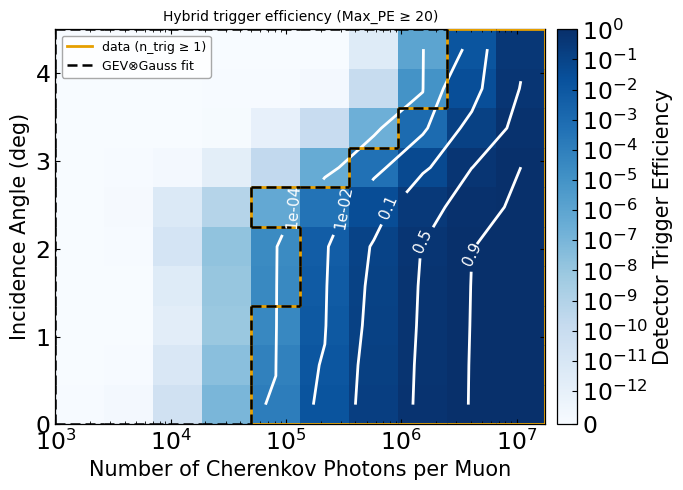


Overlap check (41 bins where data is used and a GEV⊗Gauss model also exists):
  median (model-data)/data = -0.002109
  16-84 pct               = [-0.1056, +0.008771]


In [34]:
# Complete Model (loads precomputed fit results, no recomputation)
# Static matplotlib version, styled like the empirical efficiency map,
# with NaN-aware Gaussian smoothing
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from scipy.ndimage import gaussian_filter

npz_file = "landau_gev_gauss_2d_fit_results_weighted_tested.npz"

# =========================================================
# CONFIG
# =========================================================
PE_THRESHOLD   = 20.0
N_MIN_TRIG     = 1
LINTHRESH      = 1e-12 #None          # None -> smallest positive efficiency (as in the theme)
LINSCALE       = 1
CMAP           = "Blues"
XLIM           = None #(1e3, 1e7)    # None -> full pc_edges range
CONTOUR_LEVELS = [ 1e-4, 1e-2, 0.1, 0.5, 0.9]
CONTOUR_COLOR  = "white"
CONTOUR_FS     = 11
SHOW_REGIONS   = True          # draw data / GEV-fit region boundaries
DATA_COLOR     = "#E69F00"     # Okabe-Ito orange (visible on Blues, CB-safe)
MODEL_COLOR    = "black"
SHOW_TITLE     = True
SAVE_PATH      = None          # e.g. ".../plot/eff_hybrid_inc_photoncount.png"

# --- Smoothing ---
SMOOTH         = True
SMOOTH_SIGMA   = (0.9, 0.9)    # (incidence bins, photon-count bins)
SMOOTH_SPACE   = "log"         # "log" (recommended for symlog maps) or "lin"
SMOOTH_WEIGHT  = "uniform"     # "uniform" or "counts" (weight data bins by n_total)
EFF_FLOOR      = 1e-15          # floor for log-space smoothing (eff = 0 bins)
KEEP_FOOTPRINT = True          # True -> do not fill bins that had no estimate

# =========================================================
# 1. Load precomputed fit results
# =========================================================
data = np.load(npz_file, allow_pickle=True)

inc_edges = data["inc_edges"]
pc_edges  = data["pc_edges"]

n_events            = data["n_events"]
frac_valid          = data["frac_valid"].astype(bool)
n_total             = data["n_total"]
efficiency_data     = data["efficiency_data"]
efficiency_data_err = data["efficiency_data_err"]

success_gev        = data["success_gev"].astype(bool)
mu_gev             = data["mu_gev"]
efficiency_gev     = data["efficiency_gev"]
efficiency_gev_err = data["efficiency_gev_err"]
chi2_red_gev       = data["chi2_red_gev"]

N_I, N_PC_ACTUAL = mu_gev.shape
inc_cen = 0.5 * (inc_edges[:-1] + inc_edges[1:])
pc_cen  = np.sqrt(pc_edges[:-1] * pc_edges[1:])

# =========================================================
# 2. Provenance: data-driven vs. per-bin model
# =========================================================
with np.errstate(invalid="ignore"):
    n_trig_equiv = efficiency_data * n_total

use_data   = (n_trig_equiv >= N_MIN_TRIG) & frac_valid & np.isfinite(efficiency_data)
use_perbin = (~use_data) & success_gev & frac_valid & np.isfinite(efficiency_gev)

eff_hybrid = np.full((N_I, N_PC_ACTUAL), np.nan)
eff_hybrid[use_data]   = efficiency_data[use_data]
eff_hybrid[use_perbin] = efficiency_gev[use_perbin]
eff_hybrid = np.clip(eff_hybrid, 0.0, 1.0)

provenance = np.zeros((N_I, N_PC_ACTUAL), dtype=int)
provenance[use_data]   = 1
provenance[use_perbin] = 2

print(f"\nTier 1 (data, n_trig >= {N_MIN_TRIG}) : {use_data.sum()}")
print(f"Tier 2 (per-bin GEV⊗Gauss fit)   : {use_perbin.sum()}")
print(f"No estimate                        : {(provenance == 0).sum()}")
print(f"Total bins                         : {N_I * N_PC_ACTUAL}")

# =========================================================
# 3. NaN-aware Gaussian smoothing
# =========================================================
def nan_gaussian(z, sigma, weights=None, keep_footprint=True):
    """Normalised convolution: ignores NaNs, optional per-bin weights."""
    valid = np.isfinite(z)
    w = np.ones_like(z, dtype=float) if weights is None else np.asarray(weights, float)
    w = np.where(valid & np.isfinite(w), w, 0.0)
    num = gaussian_filter(np.where(valid, z, 0.0) * w, sigma, mode="nearest")
    den = gaussian_filter(w, sigma, mode="nearest")
    with np.errstate(invalid="ignore", divide="ignore"):
        out = np.where(den > 1e-12, num / den, np.nan)
    if keep_footprint:
        out[~valid] = np.nan
    return out

def smooth_efficiency(eff, sigma, space="log", weights=None,
                      floor=1e-6, keep_footprint=True):
    if space == "log":
        z = np.log10(np.clip(eff, floor, 1.0))          # NaN stays NaN
        s = 10.0 ** nan_gaussian(z, sigma, weights, keep_footprint)
        s[s <= floor * 1.0001] = 0.0                    # map the floor back to 0
    elif space == "lin":
        s = nan_gaussian(eff, sigma, weights, keep_footprint)
    else:
        raise ValueError(f"SMOOTH_SPACE must be 'log' or 'lin', got {space!r}")
    return np.clip(s, 0.0, 1.0)

if SMOOTH:
    if SMOOTH_WEIGHT == "counts":
        # data bins: their statistics; model bins: median data weight
        w = np.where(use_data, n_total, np.nan).astype(float)
        w[use_perbin] = np.nanmedian(w[use_data]) if use_data.any() else 1.0
    elif SMOOTH_WEIGHT == "uniform":
        w = None
    else:
        raise ValueError(f"SMOOTH_WEIGHT must be 'uniform' or 'counts', got {SMOOTH_WEIGHT!r}")

    eff_plot = smooth_efficiency(eff_hybrid, SMOOTH_SIGMA, SMOOTH_SPACE, w,
                                 EFF_FLOOR, KEEP_FOOTPRINT)

    # How much did smoothing change things?
    chg = np.isfinite(eff_plot) & np.isfinite(eff_hybrid) & (eff_hybrid > 0)
    if chg.any():
        rel = eff_plot[chg] / eff_hybrid[chg] - 1.0
        print(f"\nSmoothing: sigma={SMOOTH_SIGMA} bins, space={SMOOTH_SPACE}, "
              f"weight={SMOOTH_WEIGHT}")
        print(f"  median |smoothed/raw - 1| = {np.median(np.abs(rel)):.3g}")
        print(f"  bins changed by >20%      = {(np.abs(rel) > 0.2).sum()} / {chg.sum()}")
else:
    eff_plot = eff_hybrid

# =========================================================
# 4. Blocky (exact) boundaries between provenance regions
# =========================================================
def staircase_segments(mask):
    """Outer cell edges of a boolean (N_I, N_PC) mask as [(x0,y0),(x1,y1)] segments."""
    segs = []
    ni, nj = mask.shape
    for i in range(ni):
        for j in range(nj):
            if not mask[i, j]:
                continue
            xl, xr = pc_edges[j], pc_edges[j + 1]
            yb, yt = inc_edges[i], inc_edges[i + 1]
            if j == 0      or not mask[i, j - 1]: segs.append([(xl, yb), (xl, yt)])
            if j == nj - 1 or not mask[i, j + 1]: segs.append([(xr, yb), (xr, yt)])
            if i == 0      or not mask[i - 1, j]: segs.append([(xl, yb), (xr, yb)])
            if i == ni - 1 or not mask[i + 1, j]: segs.append([(xl, yt), (xr, yt)])
    return segs

# =========================================================
# 5. Plot
# =========================================================
pos = eff_plot[np.isfinite(eff_plot) & (eff_plot > 1e-9)]
linthresh = LINTHRESH if LINTHRESH is not None else (pos.min() if pos.size else 1e-4)

fig, ax = plt.subplots(figsize=(7, 5))

# eff_plot is (N_I, N_PC) = (rows=y, cols=x) -> no transpose needed
pcm = ax.pcolormesh(
    pc_edges, inc_edges, np.ma.masked_invalid(eff_plot),
    cmap=CMAP,
    norm=SymLogNorm(linthresh=linthresh, linscale=LINSCALE, base=10,
                    vmin=0.0, vmax=1.0),
)

# ── Contours ──────────────────────────────────────────────────────────────
if np.isfinite(eff_plot).any():
    zmin, zmax = np.nanmin(eff_plot), np.nanmax(eff_plot)
    valid_levels = [lv for lv in CONTOUR_LEVELS if zmin <= lv <= zmax]
else:
    valid_levels = []

if valid_levels:
    cs = ax.contour(
        pc_cen, inc_cen, np.ma.masked_invalid(eff_plot),
        levels=valid_levels, colors=CONTOUR_COLOR, linewidths=2, alpha=1,
    )
    ax.clabel(
        cs,
        fmt={v: f"{v:.0e}" if v < 0.1 else f"{v:.1f}" for v in valid_levels},
        fontsize=CONTOUR_FS, inline=True,
    )

# ── Provenance region boundaries (from UNSMOOTHED masks) ──────────────────
if SHOW_REGIONS:
    handles = []
    if use_data.any():
        ax.add_collection(LineCollection(staircase_segments(use_data),
                                         colors=DATA_COLOR, linewidths=2.0,
                                         linestyles="solid", zorder=3))
        handles.append(Line2D([], [], color=DATA_COLOR, lw=2.0,
                              label=f"data (n_trig ≥ {N_MIN_TRIG})"))
    if use_perbin.any():
        ax.add_collection(LineCollection(staircase_segments(use_perbin),
                                         colors=MODEL_COLOR, linewidths=1.8,
                                         linestyles=(0, (4, 2)), zorder=3))
        handles.append(Line2D([], [], color=MODEL_COLOR, lw=1.8, ls=(0, (4, 2)),
                              label="GEV⊗Gauss fit"))
    if handles:
        ax.legend(handles=handles, loc="upper left", fontsize=9,
                  framealpha=0.85, edgecolor="0.6")

# ── Axes ──────────────────────────────────────────────────────────────────
ax.set_xscale("log")
ax.set_xlim(*(XLIM if XLIM is not None else (pc_edges[0], pc_edges[-1])))
ax.set_ylim(inc_edges[0], inc_edges[-1])
ax.set_xlabel("Number of Cherenkov Photons per Muon")
ax.set_ylabel("Incidence Angle (deg)")

if SHOW_TITLE:
    smooth_txt = (f", Gaussian-smoothed (σ = {SMOOTH_SIGMA} bins, {SMOOTH_SPACE})"
                  if SMOOTH else "")
    ax.set_title(f"Hybrid trigger efficiency (Max_PE ≥ {PE_THRESHOLD:.0f})", #{smooth_txt}",
                 fontsize=10)

cbar = plt.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label("Detector Trigger Efficiency")

plt.tight_layout()
if SAVE_PATH:
    plt.savefig(SAVE_PATH, dpi=300, transparent=True)
    print(f"saved: {SAVE_PATH}")
plt.show()

# =========================================================
# 6. Cross-check in the overlap region (raw, unsmoothed values)
# =========================================================
both = use_data & np.isfinite(efficiency_gev) & (efficiency_data > 0)
if both.sum():
    r = (efficiency_gev[both] - efficiency_data[both]) / efficiency_data[both]
    print(f"\nOverlap check ({both.sum()} bins where data is used and a "
          f"GEV⊗Gauss model also exists):")
    print(f"  median (model-data)/data = {np.median(r):+.4g}")
    print(f"  16-84 pct               = [{np.percentile(r,16):+.4g}, "
          f"{np.percentile(r,84):+.4g}]")
else:
    print("\nNo overlap bins available for a model-vs-data cross-check.")


Data bins (n_total >= 1, n_trig >= 1) : 45
Empty / rejected bins                         : 55
Total bins                                    : 100

Smoothing: sigma=(0.0, 0.0) bins, space=log, weight=uniform
  median |smoothed/raw - 1| = 0
  bins changed by >20%      = 0 / 45


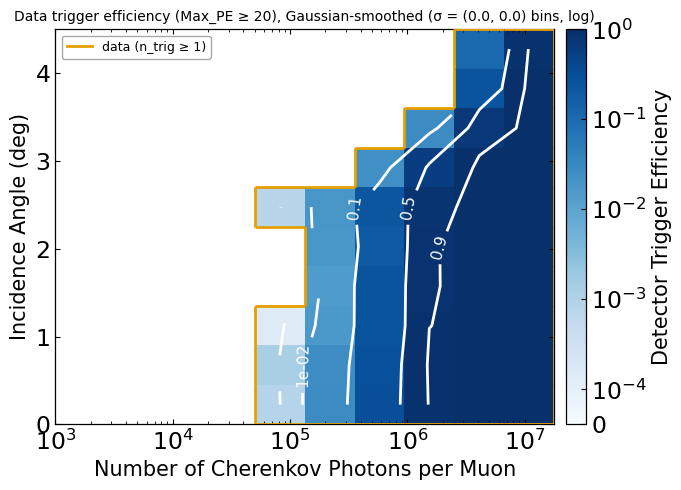

In [32]:
# Data-only trigger efficiency (loads precomputed results, no recomputation)
# Static matplotlib version, styled like the empirical efficiency map,
# with NaN-aware Gaussian smoothing
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from scipy.ndimage import gaussian_filter

npz_file = "landau_gev_gauss_2d_fit_results_weighted_tested.npz"

# =========================================================
# CONFIG
# =========================================================
PE_THRESHOLD   = 20.0
N_MIN_TRIG     = 1             # min. triggered events per bin (0 -> keep eff = 0 bins)
N_MIN_TOTAL    = 1             # min. total events per bin
LINTHRESH      = None #1e-12          # None -> smallest positive efficiency
LINSCALE       = 0.5
CMAP           = "Blues"
XLIM           = None #(1e3, 1e7)    # None -> full pc_edges range
CONTOUR_LEVELS = [1e-4, 1e-3, 1e-2, 0.1, 0.5, 0.9]
CONTOUR_COLOR  = "white"
CONTOUR_FS     = 11
SHOW_REGIONS   = True          # outline the bins that carry data
DATA_COLOR     = "#E69F00"     # Okabe-Ito orange (visible on Blues, CB-safe)
SHOW_TITLE     = True
SAVE_PATH      = None          # e.g. ".../plot/eff_data_inc_photoncount.png"

# --- Smoothing ---
SMOOTH         = True
SMOOTH_SIGMA   = (0.0, 0.0)    # (incidence bins, photon-count bins)
SMOOTH_SPACE   = "log"         # "log" (recommended for symlog maps) or "lin"
SMOOTH_WEIGHT  = "uniform"     # "uniform" or "counts" (weight bins by n_total)
EFF_FLOOR      = 1e-6          # floor for log-space smoothing (eff = 0 bins)
KEEP_FOOTPRINT = True          # True -> do not fill bins that had no data

# =========================================================
# 1. Load precomputed data efficiencies
# =========================================================
data = np.load(npz_file, allow_pickle=True)

inc_edges = data["inc_edges"]
pc_edges  = data["pc_edges"]

frac_valid          = data["frac_valid"].astype(bool)
n_total             = data["n_total"].astype(float)
efficiency_data     = data["efficiency_data"].astype(float)
efficiency_data_err = data["efficiency_data_err"]

N_I, N_PC_ACTUAL = efficiency_data.shape
inc_cen = 0.5 * (inc_edges[:-1] + inc_edges[1:])
pc_cen  = np.sqrt(pc_edges[:-1] * pc_edges[1:])

# =========================================================
# 2. Select data bins
# =========================================================
with np.errstate(invalid="ignore"):
    n_trig_equiv = efficiency_data * n_total

use_data = (np.isfinite(efficiency_data) & frac_valid
            & (n_total >= N_MIN_TOTAL) & (n_trig_equiv >= N_MIN_TRIG))

eff_raw = np.full((N_I, N_PC_ACTUAL), np.nan)
eff_raw[use_data] = np.clip(efficiency_data[use_data], 0.0, 1.0)

print(f"\nData bins (n_total >= {N_MIN_TOTAL}, n_trig >= {N_MIN_TRIG}) : {use_data.sum()}")
print(f"Empty / rejected bins                         : {(~use_data).sum()}")
print(f"Total bins                                    : {N_I * N_PC_ACTUAL}")

# =========================================================
# 3. NaN-aware Gaussian smoothing
# =========================================================
def nan_gaussian(z, sigma, weights=None, keep_footprint=True):
    """Normalised convolution: ignores NaNs, optional per-bin weights."""
    valid = np.isfinite(z)
    w = np.ones_like(z, dtype=float) if weights is None else np.asarray(weights, float)
    w = np.where(valid & np.isfinite(w), w, 0.0)
    num = gaussian_filter(np.where(valid, z, 0.0) * w, sigma, mode="nearest")
    den = gaussian_filter(w, sigma, mode="nearest")
    with np.errstate(invalid="ignore", divide="ignore"):
        out = np.where(den > 1e-12, num / den, np.nan)
    if keep_footprint:
        out[~valid] = np.nan
    return out

def smooth_efficiency(eff, sigma, space="log", weights=None,
                      floor=1e-6, keep_footprint=True):
    if space == "log":
        z = np.log10(np.clip(eff, floor, 1.0))          # NaN stays NaN
        s = 10.0 ** nan_gaussian(z, sigma, weights, keep_footprint)
        s[s <= floor * 1.0001] = 0.0                    # map the floor back to 0
    elif space == "lin":
        s = nan_gaussian(eff, sigma, weights, keep_footprint)
    else:
        raise ValueError(f"SMOOTH_SPACE must be 'log' or 'lin', got {space!r}")
    return np.clip(s, 0.0, 1.0)

if SMOOTH:
    if SMOOTH_WEIGHT == "counts":
        w = np.where(use_data, n_total, 0.0)
    elif SMOOTH_WEIGHT == "uniform":
        w = None
    else:
        raise ValueError(f"SMOOTH_WEIGHT must be 'uniform' or 'counts', got {SMOOTH_WEIGHT!r}")

    eff_plot = smooth_efficiency(eff_raw, SMOOTH_SIGMA, SMOOTH_SPACE, w,
                                 EFF_FLOOR, KEEP_FOOTPRINT)

    chg = np.isfinite(eff_plot) & np.isfinite(eff_raw) & (eff_raw > 0)
    if chg.any():
        rel = eff_plot[chg] / eff_raw[chg] - 1.0
        print(f"\nSmoothing: sigma={SMOOTH_SIGMA} bins, space={SMOOTH_SPACE}, "
              f"weight={SMOOTH_WEIGHT}")
        print(f"  median |smoothed/raw - 1| = {np.median(np.abs(rel)):.3g}")
        print(f"  bins changed by >20%      = {(np.abs(rel) > 0.2).sum()} / {chg.sum()}")
else:
    eff_plot = eff_raw

# =========================================================
# 4. Blocky (exact) outline of the data region
# =========================================================
def staircase_segments(mask):
    """Outer cell edges of a boolean (N_I, N_PC) mask as [(x0,y0),(x1,y1)] segments."""
    segs = []
    ni, nj = mask.shape
    for i in range(ni):
        for j in range(nj):
            if not mask[i, j]:
                continue
            xl, xr = pc_edges[j], pc_edges[j + 1]
            yb, yt = inc_edges[i], inc_edges[i + 1]
            if j == 0      or not mask[i, j - 1]: segs.append([(xl, yb), (xl, yt)])
            if j == nj - 1 or not mask[i, j + 1]: segs.append([(xr, yb), (xr, yt)])
            if i == 0      or not mask[i - 1, j]: segs.append([(xl, yb), (xr, yb)])
            if i == ni - 1 or not mask[i + 1, j]: segs.append([(xl, yt), (xr, yt)])
    return segs

# =========================================================
# 5. Plot
# =========================================================
pos = eff_plot[np.isfinite(eff_plot) & (eff_plot > 1e-9)]
linthresh = LINTHRESH if LINTHRESH is not None else (pos.min() if pos.size else 1e-4)

fig, ax = plt.subplots(figsize=(7, 5))

# eff_plot is (N_I, N_PC) = (rows=y, cols=x) -> no transpose needed
pcm = ax.pcolormesh(
    pc_edges, inc_edges, np.ma.masked_invalid(eff_plot),
    cmap=CMAP,
    norm=SymLogNorm(linthresh=linthresh, linscale=LINSCALE, base=10,
                    vmin=0.0, vmax=1.0),
)

# ── Contours ──────────────────────────────────────────────────────────────
if np.isfinite(eff_plot).any():
    zmin, zmax = np.nanmin(eff_plot), np.nanmax(eff_plot)
    valid_levels = [lv for lv in CONTOUR_LEVELS if zmin <= lv <= zmax]
else:
    valid_levels = []

if valid_levels:
    cs = ax.contour(
        pc_cen, inc_cen, np.ma.masked_invalid(eff_plot),
        levels=valid_levels, colors=CONTOUR_COLOR, linewidths=2, alpha=1,
    )
    ax.clabel(
        cs,
        fmt={v: f"{v:.0e}" if v < 0.1 else f"{v:.1f}" for v in valid_levels},
        fontsize=CONTOUR_FS, inline=True,
    )

# ── Data region outline (from UNSMOOTHED mask) ────────────────────────────
if SHOW_REGIONS and use_data.any():
    ax.add_collection(LineCollection(staircase_segments(use_data),
                                     colors=DATA_COLOR, linewidths=2.0,
                                     linestyles="solid", zorder=3))
    ax.legend(handles=[Line2D([], [], color=DATA_COLOR, lw=2.0,
                              label=f"data (n_trig ≥ {N_MIN_TRIG})")],
              loc="upper left", fontsize=9, framealpha=0.85, edgecolor="0.6")

# ── Axes ──────────────────────────────────────────────────────────────────
ax.set_xscale("log")
ax.set_xlim(*(XLIM if XLIM is not None else (pc_edges[0], pc_edges[-1])))
ax.set_ylim(inc_edges[0], inc_edges[-1])
ax.set_xlabel("Number of Cherenkov Photons per Muon")
ax.set_ylabel("Incidence Angle (deg)")

if SHOW_TITLE:
    smooth_txt = (f", Gaussian-smoothed (σ = {SMOOTH_SIGMA} bins, {SMOOTH_SPACE})"
                  if SMOOTH else "")
    ax.set_title(f"Data trigger efficiency (Max_PE ≥ {PE_THRESHOLD:.0f}){smooth_txt}",
                 fontsize=10)

cbar = plt.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label("Detector Trigger Efficiency")

plt.tight_layout()
if SAVE_PATH:
    plt.savefig(SAVE_PATH, dpi=300, transparent=True)
    print(f"saved: {SAVE_PATH}")
plt.show()

Energy ranges (GeV): [(100.0, 1000.0), (1000.0, 10000.0), (10000.0, 100000.0)]
8280418 linear bins, width = 10 photons


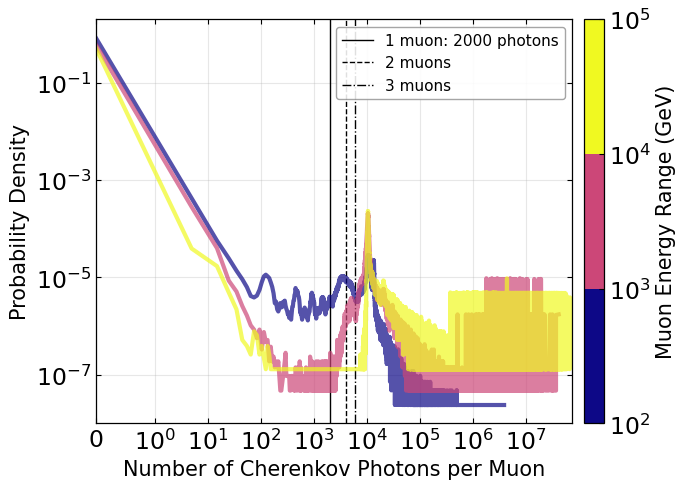

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl

# ── Sans-serif font globally ───────────────────────────────────────────────
plt.rcParams.update({
    'font.family':          'sans-serif',
    'font.sans-serif':      ['DejaVu Sans'],
    'mathtext.fontset':     'dejavusans',
    'xtick.labelsize':      17,
    'ytick.labelsize':      17,
    'axes.labelsize':       15,
    'axes.titlesize':       14,
    'legend.fontsize':      11,
})

target_energies = [1e2, 1e3, 1e4, 1e5]  # <-- edit these (bin EDGES)
n_groups = len(target_energies) - 1
print("Energy ranges (GeV):",
      [(target_energies[i], target_energies[i + 1]) for i in range(n_groups)])

# ── Linear binning settings ───────────────────────────────────────────────
BIN_WIDTH  = 10.0      # photons per bin (linear); set None to use N_LIN_BINS
N_LIN_BINS = 200      # used only if BIN_WIDTH is None
linthresh  = 1.0
SHOW_ERR   = False     # True: shaded ±1σ band

# Shared linear edges for all energy groups (same binning, directly comparable)
pc_pos_all = photon_count[np.isfinite(photon_count) & (photon_count > 0)]
pc_max = pc_pos_all.max()
if BIN_WIDTH is not None:
    lin_edges = np.arange(0.0, pc_max + BIN_WIDTH, BIN_WIDTH)
else:
    lin_edges = np.linspace(0.0, pc_max, N_LIN_BINS + 1)
lin_centers = 0.5 * (lin_edges[:-1] + lin_edges[1:])   # arithmetic centers (linear bins)
lin_widths  = np.diff(lin_edges)
print(f"{len(lin_edges) - 1} linear bins, width = {lin_widths[0]:.3g} photons")

# ── Colormap + norm tied to energy bin edges ──────────────────────────────
cmap = mpl.colormaps['plasma'].resampled(n_groups)
norm = mcolors.BoundaryNorm(boundaries=np.log10(target_energies), ncolors=n_groups)

# ── Plot ──────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
# ── Reference line: photon count from a single bare muon ──────────────────
PC_SINGLE = 2000
ax.axvline(PC_SINGLE, color='black', linestyle='-', linewidth=1,
           label=f'1 muon: {PC_SINGLE} photons')
PC_2 = PC_SINGLE *2
ax.axvline(PC_2, color='black', linestyle='--', linewidth=1,
           label='2 muons')
PC_3 = PC_SINGLE *3
ax.axvline(PC_3, color='black', linestyle='-.', linewidth=1,
           label='3 muons')
ax.legend(loc='upper right')

for i in range(n_groups):
    color = cmap(i)

    mask   = (Energy_GeV >= target_energies[i]) & (Energy_GeV < target_energies[i + 1])
    #mask    = (Ground_Energy >= target_energies[i]) & (Ground_Energy < target_energies[i + 1])
    counts = photon_count[mask]
    counts = counts[np.isfinite(counts)]
    N_tot  = counts.size
    if N_tot == 0:
        continue

    # Zero bin: treat 0 as an integer bin of width 1 -> density = N0 / (N_tot * 1)
    n_zero = np.sum(counts == 0)

    # Positive counts: linear histogram, normalised over ALL events (incl. zeros)
    n_pos, _ = np.histogram(counts[counts > 0], bins=lin_edges)
    dens     = n_pos / (N_tot * lin_widths)
    err      = np.sqrt(n_pos) / (N_tot * lin_widths)

    x   = np.concatenate([[0.0],              lin_centers])
    y   = np.concatenate([[n_zero / N_tot],   dens])
    dy  = np.concatenate([[np.sqrt(n_zero) / N_tot], err])
    ok  = y > 0

    ax.plot(x[ok], y[ok], '-', color=color, linewidth=3, alpha=0.7)
    if SHOW_ERR:
        ax.fill_between(x[ok], np.clip(y[ok] - dy[ok], 1e-300, None), y[ok] + dy[ok],
                        color=color, alpha=0.2, linewidth=0)

# ── Colorbar ──────────────────────────────────────────────────────────────
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Muon Energy Range (GeV)')
tick_vals = np.log10(target_energies)
cbar.set_ticks(tick_vals)
cbar.set_ticklabels([rf'$10^{{{int(np.log10(e))}}}$' for e in target_energies])

# ── Axes: linear bins, log display ────────────────────────────────────────
ax.set_xlabel("Number of Cherenkov Photons per Muon")
ax.set_ylabel('Probability Density')
ax.set_yscale('log')
ax.set_xscale('symlog', linthresh=linthresh)
ax.set_xlim(left=0)
ax.grid(True, which='both', alpha=0.3)

fig.tight_layout()
plt.show()

In [50]:
from trigger_eff import build_efficiency_table, TriggerEfficiency
# anytime
teff = TriggerEfficiency("trigger_eff_table.npz")

teff(30.0, 5e4)                                   # scalar -> (eff, err)
eff, err = teff(Incidence, photon_count)          # per-event, 1-D
eff, err = teff(Incidence, photon_count, mode="data")

# grid (broadcasting)
I, P = np.meshgrid(np.linspace(0, 90, 400), np.logspace(3, 7, 400), indexing="ij")
eff, err, src = teff(I, P, return_source=True)

# speed check
%timeit teff(Incidence, photon_count)             # expect ~0.1 s per 1e6–1e7 points

300 ms ± 8.72 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


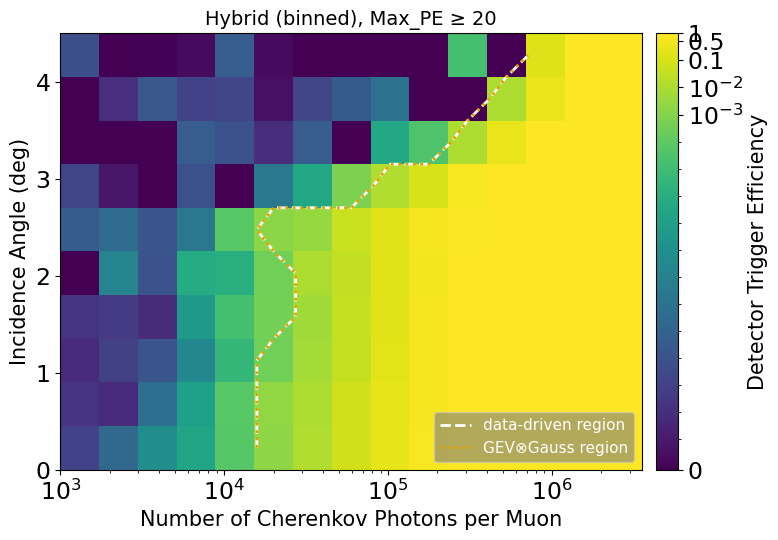

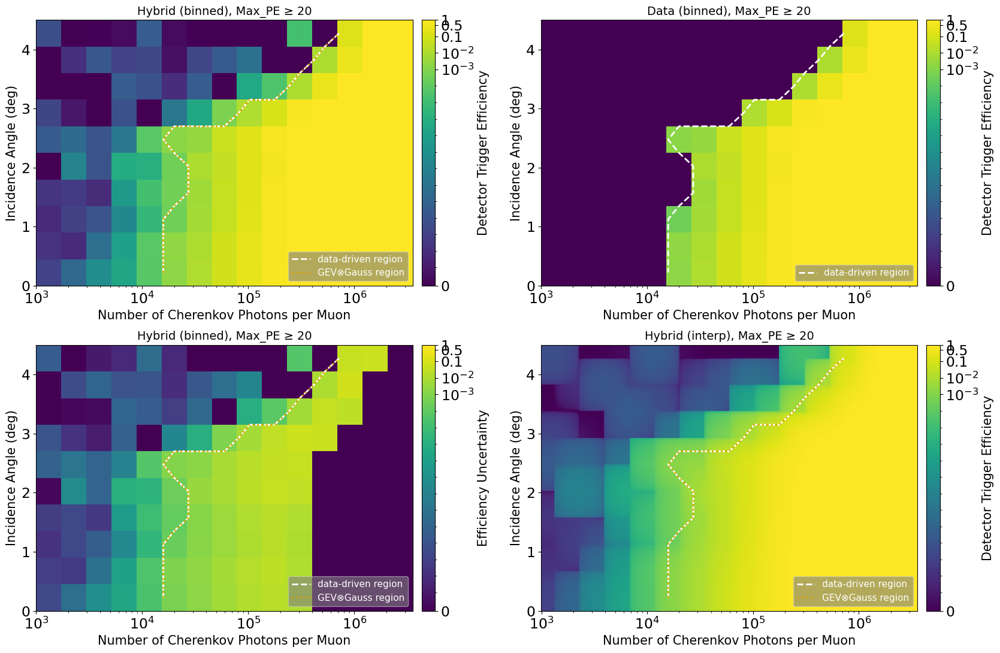

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
from matplotlib.lines import Line2D
from trigger_eff import TriggerEfficiency

plt.rcParams.update({
    'font.family':      'sans-serif',
    'font.sans-serif':  ['DejaVu Sans'],
    'mathtext.fontset': 'dejavusans',
    'xtick.labelsize':  17,
    'ytick.labelsize':  17,
    'axes.labelsize':   15,
    'axes.titlesize':   14,
    'legend.fontsize':  11,
})

teff = TriggerEfficiency("trigger_eff_table.npz")


def plot_eff_map(teff, mode="hybrid", style="binned", show_err=False,
                 n_grid=400, linthresh=1e-15, cmap="viridis",
                 show_boundary=True, xlim=(1e3, 1e7), ax=None, savepath=None):
    """
    mode     : "hybrid" | "data"
    style    : "binned" (exact table bins) | "interp" (evaluate teff on a fine grid)
    show_err : plot the efficiency uncertainty instead of the efficiency
    """
    E, S, SRC = teff._tab[mode]
    inc_e, pc_e = teff.inc_edges, teff.pc_edges

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5.5))
    else:
        fig = ax.figure

    norm = SymLogNorm(linthresh=linthresh, vmin=0.0, vmax=1.0, base=10)

    # ── Colour layer ──────────────────────────────────────────────────────
    if style == "binned":
        Z = S if show_err else E
        pcm = ax.pcolormesh(pc_e, inc_e, Z, cmap=cmap, norm=norm,
                            shading="flat", rasterized=True)
    elif style == "interp":
        pc_g  = np.logspace(np.log10(pc_e[0]), np.log10(pc_e[-1]), n_grid)
        inc_g = np.linspace(inc_e[0], inc_e[-1], n_grid)
        I, P  = np.meshgrid(inc_g, pc_g, indexing="ij")      # (n_inc, n_pc)
        eff, err = teff(I, P, mode=mode, method="linear")
        Z = err if show_err else eff
        pcm = ax.pcolormesh(pc_g, inc_g, Z, cmap=cmap, norm=norm,
                            shading="nearest", rasterized=True)
    else:
        raise ValueError("style must be 'binned' or 'interp'")

    # ── Data-region boundary (bins with real triggers) ────────────────────
    handles = []
    if show_boundary:
        pc_c  = np.sqrt(pc_e[:-1] * pc_e[1:])
        inc_c = 0.5 * (inc_e[:-1] + inc_e[1:])
        is_data = (SRC == 1).astype(float)
        if 0 < is_data.sum() < is_data.size:
            ax.contour(pc_c, inc_c, is_data, levels=[0.5],
                       colors="white", linewidths=2, linestyles="--")
            handles.append(Line2D([], [], color="white", ls="--", lw=2,
                                  label="data-driven region"))
        if mode == "hybrid":
            is_fit = (SRC == 3).astype(float)
            if 0 < is_fit.sum() < is_fit.size:
                ax.contour(pc_c, inc_c, is_fit, levels=[0.5],
                           colors="#E69F00", linewidths=2, linestyles=":")
                handles.append(Line2D([], [], color="#E69F00", ls=":", lw=2,
                                      label="GEV⊗Gauss region"))
        if handles:
            leg = ax.legend(handles=handles, loc="lower right", framealpha=0.6,
                            facecolor="gray")
            for t in leg.get_texts():
                t.set_color("white")

    # ── Axes ──────────────────────────────────────────────────────────────
    ax.set_xscale("log")
    #ax.set_xlim(*xlim)
    ax.set_ylim(inc_e[0], inc_e[-1])
    ax.set_xlabel("Number of Cherenkov Photons per Muon")
    ax.set_ylabel("Incidence Angle (deg)")
    ax.set_title(f"{mode.capitalize()} ({style}), Max_PE ≥ {teff.pe_threshold:.0f}")

    cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
    ticks = [0, 1e-3, 1e-2, 0.1, 0.5, 1.0]
    cbar.set_ticks(ticks)
    cbar.set_ticklabels(["0", r"$10^{-3}$", r"$10^{-2}$", "0.1", "0.5", "1"])
    cbar.set_label("Efficiency Uncertainty" if show_err
                   else "Detector Trigger Efficiency")

    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight", transparent=True)
    return fig, ax


# ── Single map ────────────────────────────────────────────────────────────
fig, ax = plot_eff_map(teff, mode="hybrid", style="binned")
plt.tight_layout()
plt.show()

# ── Comparison grid: hybrid vs data, efficiency vs uncertainty ────────────
fig, axes = plt.subplots(2, 2, figsize=(17, 11))
plot_eff_map(teff, mode="hybrid", style="binned",               ax=axes[0, 0])
plot_eff_map(teff, mode="data",   style="binned",               ax=axes[0, 1])
plot_eff_map(teff, mode="hybrid", style="binned", show_err=True, ax=axes[1, 0])
plot_eff_map(teff, mode="hybrid", style="interp",               ax=axes[1, 1])
plt.tight_layout()
plt.show()